# Lagunazo CRMs volumetric and tonnage assessments: ICP 2026 validation dataset

## 1 · Imports & configuration

In [1]:
%matplotlib inline
import os, re, io, json, time, math, zipfile, hashlib, platform, warnings
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from pathlib import Path
from IPython.display import display, HTML, Markdown
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy
from scipy.spatial import cKDTree
from scipy import stats
from scipy.optimize import curve_fit

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.path import Path as MPath

try:
    import pyproj
    from pyproj import Transformer
except ImportError:
    raise ImportError("pyproj is required for the WGS 84 -> UTM 29N projection (pip install pyproj).")
try:
    import shapely
    from shapely.geometry import Polygon as ShapelyPolygon, MultiPoint, Point
    SHAPELY_OK = True
except ImportError:
    shapely, SHAPELY_OK = None, False
    print("warning: shapely not found - polygon handling falls back to matplotlib (pip install shapely).")
try:
    import openpyxl
    OPENPYXL_OK = True
except ImportError:
    openpyxl, OPENPYXL_OK = None, False
    print("note: openpyxl not found - the r2 workbook (Section 13) and the Excel export are skipped (pip install openpyxl).")
try:
    pd.DataFrame({"a": [1]}).style.to_html()
    JINJA_OK = True
except Exception:
    JINJA_OK = False
try:
    pd.set_option("styler.format.escape", "html")
except Exception:
    pass

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 9.5, "axes.titlesize": 10.5, "axes.labelsize": 9.5,
    "axes.linewidth": 0.9, "xtick.direction": "in", "ytick.direction": "in",
    "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "svg.fonttype": "none"})

# input files
ICP26_CSV  = "ICP_26_clean_ver.csv"
KMZ_FILE   = "Lagunazo_waste_area.kmz" 
DEM_FILE   = "Lagunazo.dem"
ICP25_XLSX = "ICP-DATA_2026.xlsx"
SHEET_DATA, SHEET_QC, SHEET_LOC = "Analytical Data", "QC Data", "Locations"
OUT_DIR    = "results_ICP2026_validation_base193"
EPSG_UTM   = "EPSG:32629"

# sample-ID reconciliation
LAB_TO_FIELD_PREFIX = {"LA": "LG"}
LOCATION_ID_FIXES = [
    dict(no=13, recorded="LG-35-31", corrected="LG-25-31", kind="typo",
         reason="year field '35' is a typo; point lies in the LG-25-33 -> 31 -> 29 field sequence"),
    dict(no=23, recorded="LH-25-06", corrected="LG-25-06", kind="typo",
         reason="prefix 'LH' is a typo; point lies in the LG-25-07 -> 06 -> 05 field sequence"),
    dict(no=29, recorded="LG-25-34", corrected="LG-25-24", kind="inferred",
         reason="LG-25-34 is recorded twice (No. 29 and No. 44) and LG-25-24 is otherwise missing; "
                "No. 29 lies between LG-25-25 and LG-25-23 in the field sequence"),
]
APPLY_INFERRED_FIXES = True

# censored assay
BDL_FACTOR = 0.5
ODL_FACTOR = 1.0

CENSOR_AMBIGUOUS_DECADES = 1.0

AQ251_LIMITS = {
    "Mo": ("ppm", 0.01, 2000), "Cu": ("ppm", 0.01, 10000), "Pb": ("ppm", 0.01, 10000), "Zn": ("ppm", 0.1, 10000),
    "Ag": ("ppb", 2, 100000), "Ni": ("ppm", 0.1, 10000), "Co": ("ppm", 0.1, 2000), "Mn": ("ppm", 1, 10000),
    "Fe": ("%", 0.01, 40), "As": ("ppm", 0.1, 10000), "U": ("ppm", 0.05, 2000), "Au": ("ppb", 0.2, 100000),
    "Th": ("ppm", 0.1, 2000), "Sr": ("ppm", 0.5, 10000), "Cd": ("ppm", 0.01, 2000), "Sb": ("ppm", 0.02, 2000),
    "Bi": ("ppm", 0.02, 2000), "V": ("ppm", 1, 10000), "Ca": ("%", 0.01, 40), "P": ("%", 0.001, 5),
    "La": ("ppm", 0.5, 10000), "Cr": ("ppm", 0.5, 10000), "Mg": ("%", 0.01, 30), "Ba": ("ppm", 0.5, 10000),
    "Ti": ("%", 0.001, 10), "B": ("ppm", 1, 2000), "Al": ("%", 0.01, 10), "Na": ("%", 0.001, 10),
    "K": ("%", 0.01, 10), "W": ("ppm", 0.1, 100), "Sc": ("ppm", 0.1, 100), "Tl": ("ppm", 0.02, 1000),
    "S": ("%", 0.02, 10), "Hg": ("ppb", 5, 50000), "Se": ("ppm", 0.1, 100), "Te": ("ppm", 0.02, 1000),
    "Ga": ("ppm", 0.1, 1000), "Cs": ("ppm", 0.02, 2000), "Ge": ("ppm", 0.1, 100), "Hf": ("ppm", 0.02, 1000),
    "Nb": ("ppm", 0.02, 2000), "Rb": ("ppm", 0.1, 2000), "Sn": ("ppm", 0.1, 100), "Ta": ("ppm", 0.05, 2000),
    "Zr": ("ppm", 0.1, 2000), "Y": ("ppm", 0.01, 2000), "Ce": ("ppm", 0.1, 2000), "In": ("ppm", 0.02, 1000),
    "Re": ("ppb", 1, 1000), "Be": ("ppm", 0.1, 1000), "Li": ("ppm", 0.1, 2000), "Pd": ("ppb", 10, 10000),
    "Pt": ("ppb", 2, 10000)}

# stations
STATION_TOL_M = 5.0
STATION_VALUE = "depth" 

# Stage B: CRM screening
SHORTLIST_MIN_QUANT_PCT = 70.0   # samples quantified (above MDL and below the upper limit), per cent
SHORTLIST_MIN_CF        = 5.0    # median concentration factor against the upper continental crust
#   Upper continental crust, Rudnick & Gao (2014, Treatise on Geochemistry 2nd ed., Table 3), in ppm.
#   Ti, Al, Mg, Mn, P converted from the oxides (TiO2 0.64, Al2O3 15.4, MgO 2.48, MnO 0.10, P2O5 0.15 wt %).
UCC_PPM = {"Li": 24, "Be": 2.1, "B": 17, "Mg": 14955, "Al": 81505, "P": 655, "Sc": 14.0, "Ti": 3836, "V": 97,
           "Mn": 774, "Co": 17.3, "Ni": 47, "Cu": 28, "Ga": 17.5, "Ge": 1.4, "As": 4.8, "Sr": 320, "Y": 21,
           "Nb": 12, "Pd": 0.00052, "Sb": 0.4, "Ba": 628, "La": 31, "Ce": 63, "Hf": 5.3, "Ta": 0.9, "W": 1.9,
           "Pt": 0.0005, "Bi": 0.16,
           # not CRMs under Regulation (EU) 2024/1252 - used only for the co-product context table
           "Pb": 17, "Fe": 39180, "Ag": 0.053, "Au": 0.0015, "Zn": 67, "Sn": 2.1, "In": 0.056, "Hg": 0.05, "Se": 0.09}
DELETERIOUS = {"As": "listed CRM, but in sulphide mine waste arsenic is a penalty element and an environmental "
                     "liability; it is inventoried, not ranked as a recovery target"}
RESOURCE_ELEMENTS = None   # None = the Stage-B shortlist | e.g. ["Sb", "Bi", "Cu"]

# Stage C: DEM, base elevation, volume, density
BASE_ELEVATION_M = 193.0

GRID_DENSITY_M   = 3.0 
BULK_DENSITY     = dict(low=1.10, base=1.25, high=1.40)


# Stage D: variogram rules, used here to test whether a variogram can be estimated
TRANSFORM_CANDIDATES   = ["none", "log", "nscore"]
TRANSFORM_MIN_GAIN_PCT = 2.0
LOG_BACKTRANSFORM      = "journel"
NSCORE_BACKTRANSFORM   = "expectation"
NSCORE_UPPER_OMEGA     = 1.5
NSCORE_ZMAX_FACTOR     = 2.0
GH_NODES               = 24
N_LAGS_MAX     = 15
MIN_PAIRS_LAG  = 30
CUTOFF_FACTOR  = 0.50
RMSSE_PENALTY     = 0.15
SELECTION_TOL_PCT = 2.0
GAUSSIAN_MIN_NUGGET_FRAC = 1e-3
MODEL_PREFERENCE = ["Nugget", "Spherical", "Exponential", "Cubic", "Gaussian"]
K_NEIGHBORS          = 16
MIN_NEIGHBORS        = 6
SEARCH_RADIUS_FACTOR = 1.6
MIN_STATIONS, MIN_PAIRS_TOTAL, MIN_DISTINCT_VALS = 10, 45, 3
MIN_LAGS       = 3 
LOO_MIN_GAIN_PCT = 2.0            

MIN_R2_SURFACE = 0.10
PAD_FRAC       = 0.06

# Stage E: ranges, sensitivity
CI_LEVEL        = 0.90            # confidence level of the grade range 
CI_METHOD       = "student-t"     
N_BOOT_MEAN     = 20000         
BOOT_SEED       = 11
ODL_SENS_FACTOR = 1.5            
ET_SIG_FIGS     = 2             

# Used in Section 13 only when ICP25_XLSX is absent; when the workbook is present they are recomputed and checked.
R2_REFERENCE = {
    "Sb": dict(n=36, mean=532.430, median=336.775, sd=511.507, declustered=485.075, n_odl=2),
    "Bi": dict(n=36, mean=139.724, median=80.675, sd=149.135, declustered=128.190, n_odl=0),
    "As": dict(n=36, mean=1361.525, median=898.750, sd=1250.401, declustered=1386.875, n_odl=0),
    "Cu": dict(n=36, mean=511.453, median=239.950, sd=877.228, declustered=413.487, n_odl=0),
    "Co": dict(n=36, mean=4.636, median=3.100, sd=7.146, declustered=3.732, n_odl=0)}
R2_NN_SPACING_M = 22.4 

SAVE_FIGURES = True
FIG_FORMATS  = ("pdf", "svg", "png")   

for _f in (ICP26_CSV, KMZ_FILE, DEM_FILE):
    if not Path(_f).exists():
        raise FileNotFoundError(f"'{_f}' not found in {Path.cwd()} - place it next to this notebook.")
HAVE_R2_WORKBOOK = bool(Path(ICP25_XLSX).exists() and OPENPYXL_OK)
os.makedirs(OUT_DIR, exist_ok=True)
RUN_STARTED = datetime.now(timezone.utc).isoformat(timespec="seconds")
Z_CI = float(stats.norm.ppf(0.5 + CI_LEVEL / 2))
print("Configuration loaded.")
print(f"  Inputs   : {ICP26_CSV} | {KMZ_FILE} | {DEM_FILE}   ->   {OUT_DIR}/")
print(f"  r2 data  : {ICP25_XLSX} " + ("found - Section 13 recomputes the r2 statistics" if HAVE_R2_WORKBOOK
                                       else "not found - Section 13 uses R2_REFERENCE"))
print(f"  Base case: {BASE_ELEVATION_M:g} m a.s.l., homogeneous through the thickness   |   bulk density "
      f"{BULK_DENSITY['base']:g} t/m3")
print(f"  Stations : value = '{STATION_VALUE}' composite; samples within {STATION_TOL_M:g} m form one station")
print(f"  Range    : {100 * CI_LEVEL:.0f} % {CI_METHOD} interval of the mean grade")

FileNotFoundError: 'ICP_26_clean_ver.csv' not found in c:\Users\Debbie Novalina\Documents\Tharsis-Lagunazo-Master-Thesis-Project\Tharsis-Lagunazo-Master-Thesis-Project - place it next to this notebook.

## 2 · Core routines

In [ ]:
# tables
_STATUS_CSS = {"PASS": "background-color:#eafaf1;color:#1e8449;font-weight:bold",
               "WARN": "background-color:#fef9e7;color:#b7950b;font-weight:bold",
               "FAIL": "background-color:#fdedec;color:#922b21;font-weight:bold",
               "INFO": "background-color:#eaf2f8;color:#1a5276;font-weight:bold"}

def show_table(df, precision=None, status_col=None):
    """Display a DataFrame without its index; Styler when available, plain HTML otherwise."""
    if JINJA_OK:
        try:
            sty = df.style
            if precision is not None:
                sty = sty.format(precision=precision, thousands=",")
            if status_col is not None:
                colour = sty.map if hasattr(sty, "map") else sty.applymap
                sty = colour(lambda v: _STATUS_CSS.get(v, ""), subset=[status_col])
            display(sty.hide(axis="index"))
            return
        except Exception:
            pass
    d = df.copy()
    if precision is not None:
        num = d.select_dtypes("number").columns
        d[num] = d[num].round(precision)
    html = d.to_html(index=False, na_rep="", escape=True)
    if status_col is not None:
        for key, css in _STATUS_CSS.items():
            html = html.replace(f"<td>{key}</td>", f'<td style="{css}">{key}</td>')
    display(HTML(html))


# stations
def station_means(df, x_col, y_col, var, tol_m=5.0, id_col=None, flag_col=None):
    """Collapse replicates within tol_m (single linkage) to one station; returns (stations, report)."""
    d = df.copy()
    for c in (x_col, y_col, var):
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=[x_col, y_col, var]).reset_index(drop=True)
    xy = d[[x_col, y_col]].to_numpy(float)
    parent = np.arange(len(d))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for a, b in cKDTree(xy).query_pairs(r=max(tol_m, 1e-9)):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    d["_station"] = [find(i) for i in range(len(d))]
    agg = {x_col: (x_col, "mean"), y_col: (y_col, "mean"), var: (var, "mean"),
           "n_reps": (var, "size"), "rep_sd": (var, "std")}
    if id_col:
        agg[id_col] = (id_col, lambda s: "+".join(map(str, s)))
    if flag_col:
        agg[flag_col] = (flag_col, lambda s: ",".join(sorted(set(map(str, s)))))
    out = d.groupby("_station").agg(**agg).reset_index(drop=True)
    rep = dict(n_measurements=int(len(d)), n_stations=int(len(out)),
               n_stations_with_reps=int((out["n_reps"] > 1).sum()),
               median_rep_sd=float(out.loc[out["n_reps"] > 1, "rep_sd"].median())
               if (out["n_reps"] > 1).any() else np.nan)
    return out.drop(columns=["rep_sd"]), rep


# declustering
def declustering_weights(coords, values, cell_sizes=None, n_origins=12, target="min_mean", seed=0):
    """Cell declustering (GSLIB declus): origin-averaged weights (mean 1) at the cell size that minimises
    (or maximises) the declustered mean. Returns (weights, cell_size_m, table)."""
    coords, v = np.asarray(coords, float), np.asarray(values, float)
    n = len(v)
    if n < 3:
        return np.ones(n), np.nan, pd.DataFrame()
    if cell_sizes is None:
        nn = float(np.median(cKDTree(coords).query(coords, k=2)[0][:, 1]))
        ext = float(max(np.ptp(coords[:, 0]), np.ptp(coords[:, 1])))
        cell_sizes = np.unique(np.round(np.linspace(max(nn, 1.0), max(ext / 2.0, nn * 1.01), 24), 1))
    rng = np.random.default_rng(seed)
    x0, y0 = coords[:, 0].min(), coords[:, 1].min()
    rows, W = [], {}
    for cs in cell_sizes:
        acc = np.zeros(n)
        for o in range(n_origins):
            ox, oy = (0.0, 0.0) if o == 0 else (rng.uniform(0, cs), rng.uniform(0, cs))
            ix = np.floor((coords[:, 0] - x0 + ox) / cs).astype(np.int64)
            iy = np.floor((coords[:, 1] - y0 + oy) / cs).astype(np.int64)
            _, inv, cnt = np.unique(np.column_stack([ix, iy]), axis=0, return_inverse=True, return_counts=True)
            w = 1.0 / cnt[np.asarray(inv).ravel()]
            acc += w * n / w.sum()
        w = acc / n_origins
        w *= n / w.sum()
        W[float(cs)] = w
        rows.append((float(cs), float(np.sum(w * v) / n)))
    tab = pd.DataFrame(rows, columns=["cell_size_m", "declustered_mean"])
    i = tab["declustered_mean"].idxmin() if target == "min_mean" else tab["declustered_mean"].idxmax()
    cs = float(tab.loc[i, "cell_size_m"])
    return W[cs], cs, tab


# metrics
def metrics(y_true, y_pred, label=""):
    """Cross-validation statistics in grade units."""
    yt, yp = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[ok], yp[ok]
    if yt.size < 2:
        return {}
    res = yp - yt
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    rmse = float(np.sqrt(np.mean(res ** 2)))
    good = np.std(yt) > 0 and np.std(yp) > 0
    return dict(
        Label=label, n=int(yt.size), RMSE=rmse, MAE=float(np.mean(np.abs(res))), ME_bias=float(res.mean()),
        Rel_bias_pct=float(100 * res.mean() / yt.mean()) if yt.mean() else np.nan,
        Rel_RMSE_pct=float(100 * rmse / yt.mean()) if yt.mean() else np.nan,
        R2_pred=float(1 - np.sum(res ** 2) / ss_tot) if ss_tot > 0 else np.nan,
        Pearson_r=float(np.corrcoef(yt, yp)[0, 1]) if good else np.nan,
        Spearman_r=float(stats.spearmanr(yt, yp)[0]),
        Slope_obs_on_pred=float(stats.linregress(yp, yt)[0]) if good else np.nan,   # conditional bias, ideal 1
        Reg_slope=float(stats.linregress(yt, yp)[0]) if good else np.nan,           # smoothing
        Obs_min=float(yt.min()), Obs_max=float(yt.max()), Est_min=float(yp.min()), Est_max=float(yp.max()),
        Var_ratio=float(np.var(yp, ddof=1) / np.var(yt, ddof=1)) if np.var(yt) > 0 else np.nan)

print("Tables, stations, declustering and metrics loaded.")

Tables, stations, declustering and metrics loaded.


In [ ]:
# variogram models 
# Practical-range parameterisation (the model reaches ~95 % (exp, gau) or 100 % (sph, cub) of the sill at `rng`).
def _sph(h, a):
    r = np.minimum(h / a, 1.0)
    return 1.5 * r - 0.5 * r ** 3

def _exp(h, a):
    return 1.0 - np.exp(-3.0 * h / a)

def _gau(h, a):
    return 1.0 - np.exp(-3.0 * (h / a) ** 2)

def _cub(h, a):
    r = np.minimum(h / a, 1.0)
    return 7 * r ** 2 - 8.75 * r ** 3 + 3.5 * r ** 5 - 0.75 * r ** 7

SHAPES = {"Spherical": _sph, "Exponential": _exp, "Gaussian": _gau, "Cubic": _cub}


class VModel:
    """Nugget + one structure. gamma(0) = 0 (the nugget is a discontinuity at the origin)."""

    def __init__(self, name, nugget, psill, rng):
        self.name, self.nugget, self.psill, self.rng = name, float(nugget), float(psill), float(rng)

    @property
    def sill(self):
        return self.nugget + self.psill

    def gamma(self, h):
        h = np.asarray(h, float)
        g = np.full(h.shape, self.nugget)
        if self.name != "Nugget":
            g = g + self.psill * SHAPES[self.name](h, self.rng)
        return np.where(h <= 1e-9, 0.0, g)

    def rho(self, h):
        """Covariance normalised by the sill: 1 at h = 0."""
        return 1.0 - self.gamma(h) / self.sill

    def __repr__(self):
        return (f"{self.name}(nugget={self.nugget:.4g}, psill={self.psill:.4g}, "
                + ("" if self.name == "Nugget" else f"range={self.rng:.1f} m, ") + f"N:S={self.nugget / self.sill:.2f})")


def experimental_variogram(coords, y, cutoff, min_pairs=MIN_PAIRS_LAG, n_lags_max=N_LAGS_MAX):
    """Omnidirectional semivariogram with EQUAL-COUNT lags: every lag holds >= min_pairs pairs by construction.
    Returns DataFrame(lag, h_mean, h_min, h_max, gamma, n_pairs)."""
    coords, y = np.asarray(coords, float), np.asarray(y, float)
    iu = np.triu_indices(len(y), k=1)
    h = np.hypot(coords[iu[0], 0] - coords[iu[1], 0], coords[iu[0], 1] - coords[iu[1], 1])
    g = 0.5 * (y[iu[0]] - y[iu[1]]) ** 2
    keep = (h > 0) & (h <= cutoff)
    h, g = h[keep], g[keep]
    n_lags = int(min(n_lags_max, h.size // max(min_pairs, 1)))
    if n_lags < 1:
        return pd.DataFrame(columns=["lag", "h_mean", "h_min", "h_max", "gamma", "n_pairs"])
    order = np.argsort(h, kind="mergesort")
    rows = []
    for i, s in enumerate(np.array_split(order, n_lags)):
        rows.append((i + 1, h[s].mean(), h[s].min(), h[s].max(), g[s].mean(), s.size))
    return pd.DataFrame(rows, columns=["lag", "h_mean", "h_min", "h_max", "gamma", "n_pairs"])


def fit_models(vgm, cutoff):
    """Weighted least squares (weights = pair counts; with equal-count lags these are near-equal, so the fit is
    effectively unweighted) for four structured models + the pure-nugget benchmark.
    Parameterised as nugget + PARTIAL sill so both are >= 0. Returns list of (VModel, bound_hits, wrss)."""
    xf, yf, wf = (vgm[c].to_numpy(float) for c in ("h_mean", "gamma", "n_pairs"))
    gmax = float(yf.max())
    nug_hi, ps_hi = max(1.05 * gmax, 1e-12), max(1.5 * gmax, 1e-12)
    r_lo = float(max(0.5 * xf.min(), 1.0))
    r_hi = float(max(1.5 * cutoff, 4 * r_lo))
    nug0 = float(np.clip(min(yf[0], np.percentile(yf, 25)), 0.0, nug_hi))
    ps0 = float(np.clip(max(np.median(yf[-3:]) - nug0, 0.05 * gmax), 0.0, ps_hi))
    rg0 = float(np.clip(0.4 * xf.max(), r_lo, r_hi))
    sigma = 1.0 / np.sqrt(np.maximum(wf, 1e-9))
    out = []
    for name, shape in SHAPES.items():
        lo, hi = [0.0, 0.0, r_lo], [nug_hi, ps_hi, r_hi]
        if name == "Gaussian":
            lo[0] = GAUSSIAN_MIN_NUGGET_FRAC * gmax          # a zero-nugget Gaussian is numerically singular
        p0 = [float(np.clip(v, l_, h_)) for v, l_, h_ in zip([nug0, ps0, rg0], lo, hi)]
        try:
            popt, _ = curve_fit(lambda h, c0, c, a: c0 + c * shape(h, a), xf, yf, p0=p0, sigma=sigma,
                                bounds=(lo, hi), maxfev=200000)
        except (RuntimeError, ValueError):
            continue
        hits = [nm for nm, v, l_, h_ in zip(("nugget", "psill", "range"), popt, lo, hi)
                if (h_ - l_) > 0 and (abs(v - l_) <= 1e-2 * (h_ - l_) or abs(h_ - v) <= 1e-2 * (h_ - l_))
                and not (nm == "nugget" and v <= lo[0] + 1e-12 and name != "Gaussian")]
        m = VModel(name, *popt)
        out.append((m, hits, float(np.sum(wf * (m.gamma(xf) - yf) ** 2))))
    c0 = float(np.average(yf, weights=wf))
    m = VModel("Nugget", c0, 0.0, cutoff)
    out.append((m, [], float(np.sum(wf * (c0 - yf) ** 2))))
    return out

print("Variogram models and fitting loaded.")

Variogram models and fitting loaded.


In [ ]:
# ordinary kriging engine 
def _select_neighbours(d, ix, K, min_k, radius):
    """d, ix sorted by distance. Use the neighbours inside `radius` (at most K); if fewer than min_k are inside,
    use the min_k nearest (extended). The used set is always a prefix of the sorted list."""
    within = d <= radius
    n_in = within.sum(axis=1)
    m = np.where(n_in >= min_k, np.minimum(n_in, K), np.minimum(min_k, d.shape[1]))
    return m.astype(int), n_in < min_k


def ok_batch(targets, coords, y, model, K=K_NEIGHBORS, min_k=MIN_NEIGHBORS, radius=np.inf,
             exclude_self=False, chunk=4000):
    """Batched ordinary kriging at `targets`. With exclude_self=True the targets are the stations themselves
    and each is kriged from the others (leave-one-out).
    Returns dict(est, var, mu, n_used, extended, cond_max)."""
    coords, y = np.asarray(coords, float), np.asarray(y, float)
    targets = np.atleast_2d(np.asarray(targets, float))
    n, T = len(y), len(targets)
    Kq = int(min(K if K else n, n - (1 if exclude_self else 0)))
    kq = Kq + (1 if exclude_self else 0)
    d, ix = cKDTree(coords).query(targets, k=kq)
    d, ix = np.asarray(d).reshape(T, kq), np.asarray(ix).reshape(T, kq)
    if exclude_self:
        selfc = ix == np.arange(T)[:, None]
        selfc[~selfc.any(axis=1), -1] = True
        d, ix = d[~selfc].reshape(T, Kq), ix[~selfc].reshape(T, Kq)
    m_used, extended = _select_neighbours(d, ix, Kq, min(min_k, Kq), radius)
    est, var, mu = np.full(T, np.nan), np.full(T, np.nan), np.full(T, np.nan)
    cond_max = 0.0
    for m in np.unique(m_used):
        rows = np.flatnonzero(m_used == m)
        for s in range(0, rows.size, chunk):
            R = rows[s:s + chunk]
            I = ix[R, :m]
            P = coords[I]                                               # (g, m, 2)
            D = np.hypot(P[:, :, None, 0] - P[:, None, :, 0], P[:, :, None, 1] - P[:, None, :, 1])
            A = np.zeros((R.size, m + 1, m + 1))
            A[:, :m, :m] = model.rho(D)
            A[:, :m, m] = 1.0
            A[:, m, :m] = 1.0
            b = np.ones((R.size, m + 1))
            b[:, :m] = model.rho(d[R, :m])
            try:
                sol = np.linalg.solve(A, b[..., None])[..., 0]
            except np.linalg.LinAlgError:
                sol = np.stack([np.linalg.lstsq(A[j], b[j], rcond=None)[0] for j in range(R.size)])
            lam, nu = sol[:, :m], sol[:, m]
            est[R] = np.sum(lam * y[I], axis=1)
            var[R] = model.sill * np.maximum(1.0 - np.sum(lam * b[:, :m], axis=1) - nu, 0.0)
            mu[R] = -model.sill * nu                                    # semivariogram-form multiplier
            if R.size <= 64 or s == 0:
                cond_max = max(cond_max, float(np.max(np.linalg.cond(A[:64]))))
    return dict(est=est, var=var, mu=mu, n_used=m_used, extended=extended, cond_max=cond_max)


def ok_point_gamma(pt, coords, y, model, K=K_NEIGHBORS, min_k=MIN_NEIGHBORS, radius=np.inf):
    """Independent reference solver for ONE target in the SEMIVARIOGRAM form
    [Gamma 1; 1' 0][lambda; mu] = [gamma0; 1], sigma2 = lambda.gamma0 + mu. Used only in the audit."""
    dd = np.hypot(coords[:, 0] - pt[0], coords[:, 1] - pt[1])
    order = np.argsort(dd, kind="mergesort")[:min(K if K else len(y), len(y))]
    inside = order[dd[order] <= radius]
    use = inside[:K] if inside.size >= min_k else order[:min_k]
    P = coords[use]
    G = model.gamma(np.hypot(P[:, None, 0] - P[None, :, 0], P[:, None, 1] - P[None, :, 1]))
    m = len(use)
    A = np.zeros((m + 1, m + 1)); A[:m, :m] = G; A[:m, m] = 1; A[m, :m] = 1
    g0 = model.gamma(dd[use])
    sol = np.linalg.solve(A, np.append(g0, 1.0))
    lam, mu_g = sol[:m], sol[m]
    return float(lam @ y[use]), float(lam @ g0 + mu_g), float(mu_g), lam, use


def search_radius_for(model, spacing):
    return float(max(model.rng * SEARCH_RADIUS_FACTOR, 5.0 * spacing))

print("Ordinary kriging engine loaded.")

Ordinary kriging engine loaded.


In [ ]:
# transforms
class Transform:
    """none | log | nscore with explicit, documented back-transforms of a KRIGED value.

    log    : y = ln(z + c). Back: 'journel' exp(y + s2/2 - mu) - c (ordinary-kriging lognormal correction,
             Journel & Huijbregts 1978); 'naive' exp(y + s2/2) - c (simple-kriging form; biased high under OK);
             'median' exp(y) - c. Approximate prediction SD in grade units: (z* + c) sqrt(exp(s2) - 1).
    nscore : y = Phi^-1(F_w(z)) with F_w the DECLUSTERED cdf, ties sharing one score (mid-point of their
             cumulative weight). Back: 'expectation' = E[F^-1(Phi(Y))], Y ~ N(y*, s2), by Gauss-Hermite
             quadrature (the conditional mean under a multiGaussian model, with the OK variance standing in for
             the simple-kriging variance); 'median' = table look-up of y*. Tails (GSLIB backtr): linear in the
             cdf from 0 to the smallest datum, hyperbolic (omega) above the largest datum, capped at
             NSCORE_ZMAX_FACTOR x the largest datum."""

    def __init__(self, kind="none", log_mode=LOG_BACKTRANSFORM, ns_mode=NSCORE_BACKTRANSFORM, gh=GH_NODES):
        self.kind, self.log_mode, self.ns_mode = kind, log_mode, ns_mode
        t, w = np.polynomial.hermite_e.hermegauss(gh)
        self._t, self._w = t, w / w.sum()
        self.c = 0.0

    def fit(self, z, w=None):
        z = np.asarray(z, float)
        if self.kind == "log":
            self.c = 0.0 if z.min() > 0 else abs(z.min()) + 1e-6 * (np.ptp(z) or 1.0)
        elif self.kind == "nscore":
            w = np.ones_like(z) if w is None else np.asarray(w, float)
            zs, inv = np.unique(z, return_inverse=True)
            wsum = np.bincount(np.asarray(inv).ravel(), weights=w)
            cw = np.cumsum(wsum)
            p = (cw - 0.5 * wsum) / cw[-1]
            self._zs, self._ys = zs, stats.norm.ppf(p)
        return self

    def forward(self, z):
        z = np.asarray(z, float)
        if self.kind == "log":
            return np.log(z + self.c)
        if self.kind == "nscore":
            return np.interp(z, self._zs, self._ys)
        return z

    def _ns_back(self, y):
        y = np.asarray(y, float)
        z = np.interp(y, self._ys, self._zs)
        lo, hi = y < self._ys[0], y > self._ys[-1]
        if lo.any():                                      # linear in the cdf down to z = 0
            z[lo] = self._zs[0] * stats.norm.cdf(y[lo]) / stats.norm.cdf(self._ys[0])
        if hi.any():                                      # hyperbolic upper tail, capped
            ratio = stats.norm.sf(self._ys[-1]) / np.maximum(stats.norm.sf(y[hi]), 1e-300)
            z[hi] = np.minimum(self._zs[-1] * ratio ** (1.0 / NSCORE_UPPER_OMEGA),
                               NSCORE_ZMAX_FACTOR * self._zs[-1])
        return z

    def back(self, y, var=None, mu=None):
        y = np.asarray(y, float)
        if self.kind == "log":
            if self.log_mode == "median" or var is None:
                return np.exp(y) - self.c
            corr = var / 2.0 - (mu if (self.log_mode == "journel" and mu is not None) else 0.0)
            return np.exp(y + corr) - self.c
        if self.kind == "nscore":
            if self.ns_mode == "median" or var is None:
                return self._ns_back(y)
            s = np.sqrt(np.maximum(var, 0.0))
            vals = self._ns_back(y[..., None] + s[..., None] * self._t)
            return np.sum(vals * self._w, axis=-1)
        return y

    def back_sd(self, y, var, est):
        """Approximate prediction standard deviation in GRADE units."""
        y, var = np.asarray(y, float), np.maximum(np.asarray(var, float), 0.0)
        if self.kind == "log":
            return (np.asarray(est, float) + self.c) * np.sqrt(np.expm1(var))
        if self.kind == "nscore":
            s = np.sqrt(var)
            vals = self._ns_back(y[..., None] + s[..., None] * self._t)
            m1 = np.sum(vals * self._w, axis=-1)
            return np.sqrt(np.maximum(np.sum(vals ** 2 * self._w, axis=-1) - m1 ** 2, 0.0))
        return np.sqrt(var)

    def note(self):
        return {"none": "no transform",
                "log": f"log, c = {self.c:.3g}, back-transform '{self.log_mode}'",
                "nscore": f"normal score (declustered cdf), back-transform '{self.ns_mode}'"}[self.kind]

print("Transforms loaded.")

Transforms loaded.


In [ ]:
def _max_sep(c):
    return float(np.max(np.hypot(c[:, None, 0] - c[None, :, 0], c[:, None, 1] - c[None, :, 1])))

def _spacing(c):
    return float(np.median(cKDTree(c).query(c, k=2)[0][:, 1]))

def analyse_core(coords, v, w, transform, label=""):
    """Transform -> variogram -> 5 model fits -> LOOCV each -> model choice -> LOOCV metrics in grade units.
    Works on plain arrays so that the nested cross-validation can re-run it without any held-out station."""
    spacing = _spacing(coords)
    tf = Transform(transform).fit(v, w=w)
    y = tf.forward(v)
    cutoff = CUTOFF_FACTOR * _max_sep(coords)
    vgm = experimental_variogram(coords, y, cutoff)
    out = dict(transform=transform, tf=tf, y=y, vgm=vgm, cutoff=cutoff, spacing=spacing,
               sample_variance=float(np.var(y, ddof=1)))
    if len(vgm) < 3:
        out["status"] = f"only {len(vgm)} lag(s) with >= {MIN_PAIRS_LAG} pairs"
        return out
    res = []
    for model, hits, wrss in fit_models(vgm, cutoff):
        radius = search_radius_for(model, spacing)
        cv = ok_batch(coords, coords, y, model, radius=radius, exclude_self=True)
        err = cv["est"] - y
        rmse = float(np.sqrt(np.mean(err ** 2)))
        pos = cv["var"] > 0
        rmsse = float(np.sqrt(np.mean(err[pos] ** 2 / cv["var"][pos]))) if pos.any() else np.nan
        score = rmse * (1 + RMSSE_PENALTY * abs((rmsse if np.isfinite(rmsse) else 1.0) - 1.0))
        res.append(dict(model=model, hits=hits, wrss=wrss, radius=radius, cv=cv,
                        rmse_fit=rmse, rmsse=rmsse, score=score))
    res.sort(key=lambda r: r["score"])
    tied = [r for r in res if r["score"] <= res[0]["score"] * (1 + SELECTION_TOL_PCT / 100)]
    best = sorted(tied, key=lambda r: MODEL_PREFERENCE.index(r["model"].name))[0]
    cv = best["cv"]
    pred = cv["est"] if transform == "none" else tf.back(cv["est"], var=cv["var"], mu=cv["mu"])
    n_clip = int(np.sum(pred < 0))
    pred = np.clip(pred, 0.0, None)
    m = metrics(v, pred, label=f"OK LOOCV {label} ({transform})")
    z = (cv["est"] - y) / np.sqrt(np.maximum(cv["var"], 1e-300))
    nug = next(r for r in res if r["model"].name == "Nugget")
    out.update(status="ok", results=res, tied=[r["model"].name for r in tied], best=best, model=best["model"],
               radius=best["radius"], pred_ppm=pred, n_clip_cv=n_clip, m=m, rmse_ppm=m["RMSE"], r2_ppm=m["R2_pred"],
               rmse_fit=best["rmse_fit"], rmsse=best["rmsse"],
               coverage95=float(100 * np.mean(np.abs(z) <= 1.959964)), mean_std_err=float(np.mean(z)),
               gain_vs_nugget_pct=100 * (nug["rmse_fit"] - best["rmse_fit"]) / nug["rmse_fit"],
               bound_hits=", ".join(best["hits"]), n_extended_cv=int(cv["extended"].sum()))
    return out


def analyse(el, transform):
    S = STATIONS[el]
    out = analyse_core(S["coords"], S["v"], S["w"], transform, label=el)
    out["element"] = el
    return out


def gain_pct(base, chal):
    """Improvement of `chal` over `base` for an error measure (lower is better), normalised by |base|."""
    return 100.0 * (base - chal) / max(abs(base), 1e-12)


def select_transform(cands):
    """Lowest back-transformed LOOCV RMSE; a transform must beat 'none' by TRANSFORM_MIN_GAIN_PCT."""
    ok_ = {t: a for t, a in cands.items() if a["status"] == "ok"}
    if not ok_:
        return None
    pick = min(ok_.values(), key=lambda a: a["rmse_ppm"])
    g = np.nan
    if "none" in ok_ and pick["transform"] != "none":
        g = gain_pct(ok_["none"]["rmse_ppm"], pick["rmse_ppm"])
        if g < TRANSFORM_MIN_GAIN_PCT:
            pick = ok_["none"]
    pick["transform_gain_pct"] = g
    return pick


def loo_mean(v):
    v = np.asarray(v, float)
    return (v.sum() - v) / (len(v) - 1)

def loo_idw(coords, v, p=2.0, k=16):
    n = len(v); k = min(k, n - 1)
    d, ix = cKDTree(coords).query(coords, k=k + 1)
    d, ix = d[:, 1:], ix[:, 1:]
    w = 1.0 / np.maximum(d, 1e-9) ** p
    return np.sum(w * v[ix], axis=1) / w.sum(axis=1)

def reliability_class(r2):
    if r2 is None or not np.isfinite(r2) or r2 < 0:
        return "no skill"
    return "predictive" if r2 >= MIN_R2_SURFACE else "weak"

def fit_element(coords, v, w, label=""):
    """Stage 2 for one station set: every transform analysed, then the transform selected."""
    cands = {t: analyse_core(coords, v, w, t, label=label) for t in TRANSFORM_CANDIDATES}
    return cands, select_transform(cands)

print("Stage-2 routines loaded (analyse_core, select_transform, fit_element, loo_mean, loo_idw).")

Stage-2 routines loaded (analyse_core, select_transform, fit_element, loo_mean, loo_idw).


## 3 · ICP-2026 data, censored values, and sample locations

In [ ]:
def parse_cell(v):
    """Laboratory cell -> (number, flag)."""
    if v is None:
        return np.nan, "na"
    s = str(v).strip().replace(",", "")
    if s == "":
        return np.nan, "na"
    if s.upper() == "IS":
        return np.nan, "is"
    try:
        if s.startswith("<"):
            return float(s[1:]), "bdl"
        if s.startswith(">"):
            return float(s[1:]), "odl"
        return float(s), "ok"
    except ValueError:
        return np.nan, "other"


def canon_id(s):
    """'LA - 25 - 03' / 'Lg-25-7' -> ('LA', 25, 3); None if not parseable."""
    m = re.match(r"^\s*([A-Za-z]+)\s*-\s*(\d+)\s*-\s*(\d+)\s*$", str(s))
    return (m.group(1).upper(), int(m.group(2)), int(m.group(3))) if m else None


def read_lab_sheet(path, sheet):
    """Read a laboratory report sheet -> (VAL, FLAG, META, info) with one row per sample."""
    ws = openpyxl.load_workbook(path, data_only=True, read_only=True)[sheet]
    rows = [list(r) for r in ws.iter_rows(values_only=True)]

    def find_row(label):
        for i, r in enumerate(rows):
            if len(r) > 1 and isinstance(r[1], str) and r[1].strip().lower() == label:
                return i
        raise ValueError(f"'{label}' header row not found in sheet '{sheet}'")

    i_meth, i_an, i_unit, i_mdl = (find_row(x) for x in ("method", "analyte", "unit", "mdl"))
    i_hdr = next(i for i, r in enumerate(rows)
                 if r and isinstance(r[0], str) and r[0].strip().lower() == "sample")
    meta = []
    for j in range(2, len(rows[i_an])):
        an, me = rows[i_an][j], rows[i_meth][j]
        if an is None or me in (None, "WGHT"):
            continue
        key = str(an).strip() if me == "AQ251" else f"{str(an).strip()}_{me}"
        meta.append(dict(col=j, key=key, analyte=str(an).strip(), method=me,
                         unit=str(rows[i_unit][j]).strip(), mdl=float(rows[i_mdl][j])))
    meta = pd.DataFrame(meta).set_index("key")
    recs, ids, types = [], [], []
    for r in rows[i_hdr + 1:]:
        if not r or r[0] is None or str(r[0]).strip() == "" or r[1] is None:
            continue                                   # section captions / empty rows
        ids.append(str(r[0]).strip())
        types.append(str(r[1]).strip())
        recs.append([parse_cell(r[j]) for j in meta["col"]])
    val = pd.DataFrame([[c[0] for c in rec] for rec in recs], columns=meta.index)
    flg = pd.DataFrame([[c[1] for c in rec] for rec in recs], columns=meta.index)
    val.insert(0, "Lab_ID", ids); flg.insert(0, "Lab_ID", ids)
    val.insert(1, "Type", types); flg.insert(1, "Type", types)
    info = {str(r[0]).strip(":"): r[1] for r in rows[:i_meth] if r and isinstance(r[0], str)}
    return val, flg, meta.drop(columns="col"), info


# Locations sheet: DMS -> decimal degrees -> UTM 29N; ID reconciliation
DMS_RE = re.compile(r"(\d+(?:\.\d+)?)\s*[°º]\s*(\d+(?:\.\d+)?)\s*['′’]\s*(\d+(?:\.\d+)?)\s*(?:\"|″|'')?\s*([NSEW])")

def dms_pair(s):
    out = {}
    for d, m_, s_, h in DMS_RE.findall(str(s)):
        v = float(d) + float(m_) / 60 + float(s_) / 3600
        out["lat" if h in "NS" else "lon"] = -v if h in "SW" else v
    if set(out) != {"lat", "lon"}:
        raise ValueError(f"Cannot parse coordinate string: {s!r}")
    return out["lat"], out["lon"]

def lonlat_to_utm(lon, lat, epsg=EPSG_UTM):
    tf = Transformer.from_crs("EPSG:4326", epsg, always_xy=True)
    x, y = tf.transform(np.asarray(lon, float), np.asarray(lat, float))
    return np.asarray(x, float), np.asarray(y, float)


def fmt_num(v):
    if not np.isfinite(v):
        return ""
    return f"{v:,.4g}" if abs(v) < 1e4 else f"{v:,.0f}"

print("r2 parsing helpers loaded (parse_cell, canon_id, read_lab_sheet, dms_pair, lonlat_to_utm).")

r2 parsing helpers loaded (parse_cell, canon_id, read_lab_sheet, dms_pair, lonlat_to_utm).


In [ ]:
# samples
_TXT = pd.read_csv(ICP26_CSV, dtype=str, keep_default_na=False)
_TXT.columns = [str(c).strip() for c in _TXT.columns]
_REQUIRED = ["Sample_ID", "Location", "Easting (m)", "Northing (m)", "Depth_top_cm", "Depth_base_cm",
             "Lab_sample_type", "Sample_weight_kg"]
_miss = [c for c in _REQUIRED if c not in _TXT.columns]
if _miss:
    raise ValueError(f"{ICP26_CSV}: missing column(s) {_miss}")

def _num(col):
    return pd.to_numeric(_TXT[col].astype(str).str.strip().replace("", np.nan), errors="coerce")

SAMP = pd.DataFrame({"Sample": _TXT["Sample_ID"].astype(str).str.strip(),
                     "Group": _TXT["Location"].astype(str).str.strip(),
                     "X_utm": _num("Easting (m)"), "Y_utm": _num("Northing (m)"),
                     "Top_cm": _num("Depth_top_cm"), "Base_cm": _num("Depth_base_cm"),
                     "Type": _TXT["Lab_sample_type"].astype(str).str.strip(), "Mass_kg": _num("Sample_weight_kg")})
if SAMP["Sample"].duplicated().any():
    raise ValueError(f"duplicated sample IDs: {SAMP.loc[SAMP['Sample'].duplicated(), 'Sample'].tolist()}")
if (SAMP["Top_cm"].notna() != SAMP["Base_cm"].notna()).any():
    raise ValueError("a depth interval has a top without a base, or a base without a top")
_dep = SAMP["Top_cm"].notna().to_numpy()
if (SAMP.loc[_dep, "Top_cm"] >= SAMP.loc[_dep, "Base_cm"]).any():
    raise ValueError("a depth interval has top >= base")
LOCATED = (SAMP["X_utm"].notna() & SAMP["Y_utm"].notna()).to_numpy()
SHORT_ID = SAMP["Sample"].str.replace(r"^LG_26_", "", regex=True).str.replace("_(", " (", regex=False)
# plausibility of the projection: the r2 samples span E 661439-661976, N 4165391-4165792 in UTM 29N
_win = (SAMP.loc[LOCATED, "X_utm"].between(655_000, 668_000) & SAMP.loc[LOCATED, "Y_utm"].between(4_158_000, 4_172_000))
if not _win.all():
    print(f"WARNING: {int((~_win).sum())} sample(s) fall outside the Lagunazo window of UTM 29N - check the projection.")

# analytes and limits
_ANALYTE_RE = re.compile(r"^([A-Z][a-z]?)_(ppm|ppb|pct)$")
_UNIT = {"ppm": "ppm", "ppb": "ppb", "pct": "%"}
TO_PPM = {"%": 1e4, "ppm": 1.0, "ppb": 1e-3}
ANALYTE_COLS = [c for c in _TXT.columns if _ANALYTE_RE.match(c)]
META = pd.DataFrame([{"key": _ANALYTE_RE.match(c).group(1), "col": c, "unit": _UNIT[_ANALYTE_RE.match(c).group(2)]}
                     for c in ANALYTE_COLS]).set_index("key")
_unknown = [k for k in META.index if k not in AQ251_LIMITS]
_badunit = [k for k in META.index if k in AQ251_LIMITS and AQ251_LIMITS[k][0] != META.loc[k, "unit"]]
if _unknown or _badunit:
    raise ValueError(f"no AQ251 limits configured for {_unknown}; unit differs from AQ251_LIMITS for {_badunit}")
META["method"] = "AQ251"
META["mdl"] = [float(AQ251_LIMITS[k][1]) for k in META.index]
META["udl"] = [float(AQ251_LIMITS[k][2]) for k in META.index]
_unused_cols = [c for c in _TXT.columns if c not in _REQUIRED and c not in ANALYTE_COLS]

# values, flags and the direction of the empty cells
VAL = pd.DataFrame(np.nan, index=SAMP.index, columns=META.index, dtype=float)
FLAG = pd.DataFrame("na", index=SAMP.index, columns=META.index, dtype=object)
_cens, LIMIT_VIOLATIONS = [], []
for k in META.index:
    parsed = [parse_cell(x) for x in _TXT[META.loc[k, "col"]]]
    v = np.array([p[0] for p in parsed], float)
    f = np.array([p[1] for p in parsed], dtype=object)
    if (f == "other").any():
        raise ValueError(f"{k}: unreadable cell(s) {list(_TXT.loc[f == 'other', META.loc[k, 'col']])}")
    mdl, udl = META.loc[k, "mdl"], META.loc[k, "udl"]
    rep = v[f == "ok"]
    if rep.size and (rep.min() < mdl * (1 - 1e-9) or rep.max() > udl * (1 + 1e-9)):
        LIMIT_VIOLATIONS.append(f"{k} ({rep.min():g} - {rep.max():g} {META.loc[k, 'unit']} against MDL {mdl:g}, "
                                f"upper limit {udl:g})")
    empty = f == "na"
    if empty.any():
        if rep.size:
            d_lo, d_hi = float(np.log10(rep.min() / mdl)), float(np.log10(udl / rep.max()))
            direction = "bdl" if d_lo <= d_hi else "odl"
            evidence = "clear" if abs(d_lo - d_hi) >= CENSOR_AMBIGUOUS_DECADES else "AMBIGUOUS [CONFIRM]"
        else:
            d_lo = d_hi = np.nan
            direction, evidence = "bdl", "nothing reported - not detected"
        f[empty] = direction
        v[empty] = mdl if direction == "bdl" else udl
        _ids = SHORT_ID[empty].tolist()
        _cens.append({"Analyte": k, "Unit": META.loc[k, "unit"], "MDL": mdl, "Upper limit": udl,
                      "n empty": int(empty.sum()), "n reported": int(rep.size),
                      "Lowest reported": fmt_num(rep.min()) if rep.size else "",
                      "Highest reported": fmt_num(rep.max()) if rep.size else "",
                      "Decades above MDL": d_lo, "Decades below upper limit": d_hi,
                      "Empty cells read as": "< MDL" if direction == "bdl" else "> upper limit (lower bound)",
                      "Evidence": evidence,
                      "Empty in": ", ".join(_ids) if len(_ids) <= 6 else f"{len(_ids)} of {len(SAMP)} samples"})
    VAL[k], FLAG[k] = v, f
CENSOR_TABLE = pd.DataFrame(_cens)

print(f"{ICP26_CSV}: {len(SAMP)} samples, {len(META)} analytes (all {', '.join(sorted(set(META['unit'])))} units of "
      f"the AQ251 package), {int(LOCATED.sum())} located"
      + (f"; columns not used: {_unused_cols}" if _unused_cols else ""))
print(f"  depth intervals given for {int(_dep.sum())} samples; sample mass {1000 * SAMP['Mass_kg'].min():.0f} - "
      f"{1000 * SAMP['Mass_kg'].max():.0f} g; laboratory sample type: {', '.join(SAMP['Type'].unique())}")
print(f"  analytes reported in every sample: {int((FLAG == 'ok').all().sum())}; with empty cells: {len(CENSOR_TABLE)}")
_odl = CENSOR_TABLE[CENSOR_TABLE["Empty cells read as"].str.startswith(">")] if len(CENSOR_TABLE) else CENSOR_TABLE
print(f"  empty cells read as '> upper limit' (lower bounds): "
      + (", ".join(f"{r['Analyte']} ({r['n empty']})" for _, r in _odl.iterrows()) or "none"))
_amb = CENSOR_TABLE[CENSOR_TABLE["Evidence"].str.startswith("AMBIGUOUS")] if len(CENSOR_TABLE) else CENSOR_TABLE
print(f"  ambiguous direction: " + (", ".join(_amb["Analyte"]) if len(_amb) else "none"))
print("  reported values outside the configured limits: " + ("; ".join(LIMIT_VIOLATIONS) if LIMIT_VIOLATIONS else "none"))
_show = CENSOR_TABLE.copy()
for _c in ("MDL", "Upper limit"):
    _show[_c] = _show[_c].map(lambda x: f"{x:,g}")
show_table(_show, precision=2)

ICP_26_clean_ver.csv: 18 samples, 53 analytes (all %, ppb, ppm units of the AQ251 package), 18 located
  depth intervals given for 11 samples; sample mass 20 - 50 g; laboratory sample type: Rock Chip
  analytes reported in every sample: 24; with empty cells: 29
  empty cells read as '> upper limit' (lower bounds): Pb (15), Ag (10), S (6), Hg (10), Se (5), Sn (12)
  ambiguous direction: Al
  reported values outside the configured limits: none


Analyte,Unit,MDL,Upper limit,n empty,n reported,Lowest reported,Highest reported,Decades above MDL,Decades below upper limit,Empty cells read as,Evidence,Empty in
Pb,ppm,0.01,"10,000",15,3,"1,062","6,551",5.03,0.18,> upper limit (lower bound),clear,15 of 18 samples
Ag,ppb,2,"100,000",10,8,"10,487","92,251",3.72,0.04,> upper limit (lower bound),clear,10 of 18 samples
U,ppm,0.05,"2,000",2,16,0.1,1,0.30,3.30,< MDL,clear,"G2_31, P1 (0-10)cm"
Th,ppm,0.1,"2,000",2,16,0.2,1.8,0.30,3.05,< MDL,clear,"G2_31, P1 (0-10)cm"
V,ppm,1,"10,000",7,11,1,16,0.00,2.80,< MDL,clear,7 of 18 samples
Ca,%,0.01,40,17,1,0.01,0.01,0.00,3.60,< MDL,clear,17 of 18 samples
P,%,0.001,5,3,15,0.001,0.02,0.00,2.40,< MDL,clear,"G1_15, P6 (170-180)cm, P6 (220-230)cm"
Mg,%,0.01,30,16,2,0.01,0.02,0.00,3.18,< MDL,clear,16 of 18 samples
Ba,ppm,0.5,"10,000",2,16,1.1,100.3,0.34,2.00,< MDL,clear,"P1 (0-10)cm, P6 (220-230)cm"
Ti,%,0.001,10,6,12,0.001,0.006,0.00,3.22,< MDL,clear,"G1_15, G1_29, P1 (0-10)cm, P1 (25-30)cm, P1 (45-50)cm, P6 (220-230)cm"


### 3.1 · Stations and depth profiles

In [ ]:
def depth_weights(top, base):
    """Depth (cm) each interval of ONE profile represents: its own length plus half of every unsampled gap next to it.
    The gap between the surface and the first interval goes to the first interval; nothing below the deepest one."""
    top, base = np.asarray(top, float), np.asarray(base, float)
    o = np.argsort(top, kind="mergesort")
    t, b = top[o], base[o]
    if np.any(t[1:] < b[:-1] - 1e-9):
        raise ValueError(f"overlapping depth intervals: {list(zip(t, b))}")
    cut = 0.5 * (b[:-1] + t[1:])
    w = np.empty(len(t))
    w[o] = np.r_[cut, b[-1]] - np.r_[0.0, cut]
    return w

def station_index(xy, tol):
    """Single-linkage grouping of positions closer than tol (the rule of r2's station_means), numbered in file order."""
    parent = np.arange(len(xy))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for a, b in cKDTree(xy).query_pairs(r=max(tol, 1e-9)):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    return pd.factorize(pd.Series([find(i) for i in range(len(xy))]))[0]

SAMP["Station_no"] = -1
SAMP.loc[LOCATED, "Station_no"] = station_index(SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(float), STATION_TOL_M)
SAMP["Depth_w_cm"] = np.nan
_rows = []
for s, g in SAMP[LOCATED].groupby("Station_no", sort=True):
    has_d = g["Top_cm"].notna()
    if has_d.any() and not has_d.all():
        raise ValueError(f"station {s}: some samples have a depth interval and some do not ({list(g['Sample'])})")
    profile = bool(has_d.all() and len(g) > 1)
    if profile:
        SAMP.loc[g.index, "Depth_w_cm"] = depth_weights(g["Top_cm"], g["Base_cm"])
    kind = "profile" if profile else ("single sample" if len(g) == 1 else "replicates")
    name = (g["Group"].iloc[0] if profile and g["Group"].nunique() == 1 else "+".join(SHORT_ID[g.index]))
    _rows.append({"Station_no": int(s), "Station": name, "Kind": kind, "Group": "/".join(sorted(g["Group"].unique())),
                  "n samples": len(g),
                  "Depth (cm)": f"{g['Top_cm'].min():g}-{g['Base_cm'].max():g}" if has_d.all() else "",
                  "Sampled length (cm)": float((g["Base_cm"] - g["Top_cm"]).sum()) if has_d.all() else np.nan,
                  "Weights (cm)": ", ".join(f"{w:g}" for w in SAMP.loc[g.index, "Depth_w_cm"]) if profile else "",
                  "X_utm": float(g["X_utm"].mean()), "Y_utm": float(g["Y_utm"].mean()),
                  "Max offset (m)": float(np.max(np.hypot(g["X_utm"] - g["X_utm"].mean(), g["Y_utm"] - g["Y_utm"].mean()))),
                  "Samples": ", ".join(SHORT_ID[g.index])})
STATION_LIST = pd.DataFrame(_rows)
N_STATIONS = len(STATION_LIST)
_xy = STATION_LIST[["X_utm", "Y_utm"]].to_numpy(float)
_nn = cKDTree(_xy).query(_xy, k=2)[0][:, 1]
STATION_LIST["NN distance (m)"] = _nn
show_table(STATION_LIST.drop(columns=["Station_no"]), precision=1)
_k = STATION_LIST["Kind"].value_counts()
print(f"{int(LOCATED.sum())} located samples -> {N_STATIONS} stations: "
      + ", ".join(f"{n} {k}{'s' if n > 1 and not k.endswith('s') else ''}" for k, n in _k.items()))
for _, r in STATION_LIST[STATION_LIST["Kind"] == "profile"].iterrows():
    print(f"  {r['Station']:4s} {r['Depth (cm)']:>8s} cm, {r['n samples']} intervals totalling {r['Sampled length (cm)']:g} cm; "
          f"depth weights {r['Weights (cm)']} cm")
print(f"Nearest-neighbour spacing between stations: median {np.median(_nn):.1f} m (min {_nn.min():.1f}, max {_nn.max():.1f}) - "
      f"about {np.median(_nn) / R2_NN_SPACING_M:.1f} x the {R2_NN_SPACING_M:g} m of the r2 samples")

Station,Kind,Group,n samples,Depth (cm),Sampled length (cm),Weights (cm),X_utm,Y_utm,Max offset (m),Samples,NN distance (m)
G1_15,single sample,G1,1,,,,661462.0,4165632.5,0.0,G1_15,61.1
G1_27,single sample,G1,1,,,,661699.6,4165857.0,0.0,G1_27,97.1
G1_29,single sample,G1,1,,,,661712.0,4165760.6,0.0,G1_29,86.5
G2_14,single sample,G2,1,,,,661903.8,4165664.5,0.0,G2_14,110.0
G2_19,single sample,G2,1,,,,661812.5,4165726.0,0.0,G2_19,106.3
G2_28,single sample,G2,1,,,,661716.0,4165514.3,0.0,G2_28,64.5
G2_31,single sample,G2,1,,,,661731.9,4165603.4,0.0,G2_31,90.5
P1,profile,P1,3,0-50,20.0,"17.5, 20, 12.5",661669.4,4165685.4,0.0,"P1 (0-10)cm, P1 (25-30)cm, P1 (45-50)cm",86.5
P6,profile,P6,4,10-300,40.0,"95, 105, 60, 40",661492.8,4165685.3,0.0,"P6 (10-20)cm, P6 (170-180)cm, P6 (220-230)cm, P6 (290-300)cm",61.1
A2,profile,A2,4,0-41,41.0,"12, 12, 12, 5",661658.3,4165485.4,0.0,"A2 (0-12)cm, A2 (12-24)cm, A2 (24-36)cm, A2 (36-41)cm",64.5


18 located samples -> 10 stations: 7 single samples, 3 profiles
  P1       0-50 cm, 3 intervals totalling 20 cm; depth weights 17.5, 20, 12.5 cm
  P6     10-300 cm, 4 intervals totalling 40 cm; depth weights 95, 105, 60, 40 cm
  A2       0-41 cm, 4 intervals totalling 41 cm; depth weights 12, 12, 12, 5 cm
Nearest-neighbour spacing between stations: median 86.5 m (min 61.1, max 110.0) - about 3.9 x the 22.4 m of the r2 samples


## 4 · Laboratory QC 

In [ ]:
print(f"QC records in {ICP26_CSV}: none (no duplicates, reference materials or blanks) - batch precision not assessed.")
print(f"Reported values against the configured AQ251 limits: "
      + ("all inside" if not LIMIT_VIOLATIONS else "OUTSIDE for " + "; ".join(LIMIT_VIOLATIONS)))
MDL_CHECK = pd.DataFrame()
if HAVE_R2_WORKBOOK:
    _, _, _r2meta, _r2info = read_lab_sheet(ICP25_XLSX, SHEET_DATA)
    _aq = _r2meta[_r2meta["method"] == "AQ251"]
    MDL_CHECK = pd.DataFrame([{"Analyte": k, "Unit (2026)": META.loc[k, "unit"], "MDL configured": META.loc[k, "mdl"],
                               "Unit (r2)": _aq.loc[k, "unit"] if k in _aq.index else "",
                               "MDL r2 workbook": _aq.loc[k, "mdl"] if k in _aq.index else np.nan}
                              for k in META.index])
    MDL_CHECK["Same"] = ((MDL_CHECK["Unit (2026)"] == MDL_CHECK["Unit (r2)"])
                         & np.isclose(MDL_CHECK["MDL configured"], MDL_CHECK["MDL r2 workbook"]))
    _diff = MDL_CHECK[~MDL_CHECK["Same"]]
    print(f"MDLs against the r2 workbook ({_r2info.get('Job Number', '')}): {int(MDL_CHECK['Same'].sum())} of {len(MDL_CHECK)} "
          "identical in unit and value" + ("" if _diff.empty else "; differ for:"))
    if not _diff.empty:
        show_table(_diff.assign(**{c: _diff[c].map(lambda x: f"{x:g}") for c in ("MDL configured", "MDL r2 workbook")}))
else:
    print("r2 workbook not present - MDLs not cross-checked.")

QC records in ICP_26_clean_ver.csv: none (no duplicates, reference materials or blanks) - batch precision not assessed.
Reported values against the configured AQ251 limits: all inside
MDLs against the r2 workbook (PLKRK2600014): 52 of 53 identical in unit and value; differ for:


Analyte,Unit (2026),MDL configured,Unit (r2),MDL r2 workbook,Same
U,ppm,0.05,ppm,0.1,False


## 5 · Stage B which CRMs are present, and which are enriched?

In [ ]:
# (CRMA 2024 entry, strategic?, ICP analytes, note)
CRMA_2024 = [
    ("Aluminium / bauxite",  "yes",  ["Al", "Al2O3_LF725"], ""),
    ("Antimony",             "no",   ["Sb"], ""),
    ("Arsenic",              "no",   ["As"], ""),
    ("Baryte",               "no",   ["Ba", "Ba_LF725"], "proxy: Ba (baryte = BaSO4)"),
    ("Beryllium",            "no",   ["Be"], ""),
    ("Bismuth",              "yes",  ["Bi"], ""),
    ("Boron / borate",       "yes (metallurgy grade)", ["B"], ""),
    ("Cobalt",               "yes",  ["Co"], ""),
    ("Coking coal",          "no",   [], "not determinable (fuel, not an element assay)"),
    ("Copper",               "yes",  ["Cu", "Cu_LF725"], ""),
    ("Feldspar",             "no",   [], "not determinable (mineral; needs mineralogy)"),
    ("Fluorspar",            "no",   [], "not analysed (F not in AQ251/LF725)"),
    ("Gallium",              "yes",  ["Ga"], ""),
    ("Germanium",            "yes",  ["Ge"], ""),
    ("Hafnium",              "no",   ["Hf"], ""),
    ("Helium",               "no",   [], "not determinable"),
    ("Heavy rare earth elements", "partly (magnet REE Tb, Dy, Gd not analysed)", ["Y"],
     "only Y analysed; Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb, Lu not in AQ251"),
    ("Light rare earth elements", "partly (Ce is a magnet REE)", ["La", "Ce"],
     "Pr, Nd, Sm not in AQ251"),
    ("Lithium",              "yes (battery grade)", ["Li"], ""),
    ("Magnesium",            "yes (metal)", ["Mg", "MgO_LF725"], ""),
    ("Manganese",            "yes (battery grade)", ["Mn", "MnO_LF725"], ""),
    ("Natural graphite",     "yes (battery grade)", [], "not analysed (C not in AQ251/LF725)"),
    ("Nickel – battery grade", "yes", ["Ni"], ""),
    ("Niobium",              "no",   ["Nb"], ""),
    ("Phosphate rock",       "no",   ["P2O5_LF725"], "proxy: P2O5"),
    ("Phosphorus",           "no",   ["P", "P2O5_LF725"], ""),
    ("Platinum group metals", "yes", ["Pd", "Pt"], "only Pd, Pt analysed"),
    ("Scandium",             "no",   ["Sc"], ""),
    ("Silicon metal",        "yes",  ["SiO2_LF725"], "proxy only: SiO2 in tailings is not a Si-metal feedstock"),
    ("Strontium",            "no",   ["Sr"], ""),
    ("Tantalum",             "no",   ["Ta"], ""),
    ("Titanium metal",       "yes",  ["Ti", "TiO2_LF725"], ""),
    ("Tungsten",             "yes",  ["W"], ""),
    ("Vanadium",             "no",   ["V"], ""),
]
assert len(CRMA_2024) == 34, "CRMA 2024 Annex II lists 34 critical raw materials"

# Behaviour of aqua regia (AQ251) by host phase. Fusion (LF725) is a total method.
AR_NEAR_TOTAL = {"Cu", "Co", "Ni", "Bi", "Sb", "As"}                       # sulphide / sulphosalt / oxide-hosted
AR_PARTIAL    = {"Al", "Ba", "Be", "Ga", "Hf", "Li", "Nb", "Sc", "Sr", "Ta", "Ti", "V", "W",
                 "La", "Ce", "Y", "B", "Mg"}                                # silicate / resistate-hosted
AR_VARIABLE   = {"Mn": "Mn-oxide/carbonate soluble, silicate Mn not",
                 "P": "apatite soluble, monazite/xenotime not",
                 "Ge": "sphalerite-hosted Ge soluble; volatile GeCl4 losses possible in HCl media",
                 "Pd": "native/sulphide-hosted PGM largely soluble", "Pt": "native/sulphide-hosted PGM largely soluble"}

def digestion_class(key):
    if key.endswith("_LF725"):
        return "total (fusion XRF)"
    if key in AR_NEAR_TOTAL:
        return "near-total (aqua regia)"
    if key in AR_PARTIAL:
        return "partial (aqua regia) †"
    if key in AR_VARIABLE:
        return "variable (aqua regia)"
    return "aqua regia"

def fmt_num(v):
    if not np.isfinite(v):
        return ""
    return f"{v:,.4g}" if abs(v) < 1e4 else f"{v:,.0f}"

rows = []
_loc = pd.Series(LOCATED, index=SAMP.index)
for crm, srm, analytes, note in CRMA_2024:
    for a in analytes:
        if a not in META.index:
            continue                                   # fusion-XRF (LF725) analytes were not run on the 2026 samples
        f_all, v_all = FLAG[a], VAL[a]
        analysed = f_all.isin(["ok", "bdl", "odl"])
        det = f_all.isin(["ok", "odl"])
        q = v_all[f_all == "ok"]
        sub = np.where(f_all == "bdl", BDL_FACTOR * v_all, v_all)[analysed.to_numpy()]   # >UDL kept at the limit
        min_s = (f"<{META.loc[a, 'mdl']:g}" if (f_all == "bdl").any() else fmt_num(q.min())) if analysed.any() else ""
        max_s = (f">{v_all[f_all == 'odl'].max():g}" if (f_all == "odl").any()
                 else fmt_num(q.max()) if len(q) else f"<{META.loc[a, 'mdl']:g}") if analysed.any() else ""
        hi = v_all[det]
        quality = ("" if not det.any() else "marginal (all detections < 3 x MDL)"
                   if (hi < 3 * META.loc[a, "mdl"]).all() else "")
        rows.append({
            "CRMA 2024 raw material": crm, "Strategic (Annex I)": srm, "Analyte": a, "Unit": META.loc[a, "unit"],
            "MDL": META.loc[a, "mdl"], "n analysed": int(analysed.sum()), "n > MDL": int(det.sum()),
            "% > MDL": round(100 * det.sum() / analysed.sum(), 1) if analysed.sum() else np.nan,
            "n > upper limit": int((f_all == "odl").sum()),
            "Min": min_s, "Median (subst.)": float(np.median(sub)) if sub.size else np.nan, "Max": max_s,
            "Identified": "yes" if det.any() else ("not detected" if analysed.any() else "not analysed"),
            "Detection quality": quality, "Digestion": digestion_class(a),
            f"Stations with a detection (of {N_STATIONS})": int(SAMP.loc[det & _loc, "Station_no"].nunique()),
            "Note": note})
CRM_TABLE = pd.DataFrame(rows)
SRM_OVERRIDE = {"Y": "no (Y is not a magnet REE)", "La": "no (La is not a magnet REE)", "Ce": "yes (magnet REE)"}
CRM_TABLE["Strategic (Annex I)"] = [SRM_OVERRIDE.get(a, s) for a, s in
                                    zip(CRM_TABLE["Analyte"], CRM_TABLE["Strategic (Annex I)"])]
CRM_NOT_COVERED = pd.DataFrame([{"CRMA 2024 raw material": c, "Strategic (Annex I)": s,
                                 "Note": n if not a else "only a fusion-XRF proxy in r2 (" + ", ".join(a) + "); not run in 2026"}
                                for c, s, a, n in CRMA_2024 if not any(x in META.index for x in a)])
IDENTIFIED = CRM_TABLE.loc[CRM_TABLE["Identified"] == "yes", "Analyte"].tolist()

show = CRM_TABLE.copy()
show["Median (subst.)"] = show["Median (subst.)"].map(fmt_num)
show["MDL"] = show["MDL"].map(lambda x: f"{x:g}")
pd.set_option("display.max_colwidth", 60)
show_table(show.drop(columns=["Note"]), precision=1)
print("\nCRMA 2024 raw materials not determinable from this file:")
show_table(CRM_NOT_COVERED)

CRMA 2024 raw material,Strategic (Annex I),Analyte,Unit,MDL,n analysed,n > MDL,% > MDL,n > upper limit,Min,Median (subst.),Max,Identified,Detection quality,Digestion,Stations with a detection (of 10)
Aluminium / bauxite,yes,Al,%,0.01,18,16,88.9,0,<0.01,0.06,0.83,yes,,partial (aqua regia) †,10
Antimony,no,Sb,ppm,0.02,18,18,100.0,0,18.18,436.6,"1,628",yes,,near-total (aqua regia),10
Arsenic,no,As,ppm,0.1,18,18,100.0,0,349.2,"1,380","5,713",yes,,near-total (aqua regia),10
Baryte,no,Ba,ppm,0.5,18,16,88.9,0,<0.5,39.45,100.3,yes,,partial (aqua regia) †,10
Beryllium,no,Be,ppm,0.1,18,2,11.1,0,<0.1,0.05,0.2,yes,marginal (all detections < 3 x MDL),partial (aqua regia) †,2
Bismuth,yes,Bi,ppm,0.02,18,18,100.0,0,5.74,91.2,447.2,yes,,near-total (aqua regia),10
Boron / borate,yes (metallurgy grade),B,ppm,1,18,3,16.7,0,<1,0.5,7,yes,,partial (aqua regia) †,3
Cobalt,yes,Co,ppm,0.1,18,18,100.0,0,0.4,2.45,13.8,yes,,near-total (aqua regia),10
Copper,yes,Cu,ppm,0.01,18,18,100.0,0,48.22,256.8,"2,726",yes,,near-total (aqua regia),10
Gallium,yes,Ga,ppm,0.1,18,17,94.4,0,<0.1,0.6,5.6,yes,,partial (aqua regia) †,10



CRMA 2024 raw materials not determinable from this file:


CRMA 2024 raw material,Strategic (Annex I),Note
Coking coal,no,"not determinable (fuel, not an element assay)"
Feldspar,no,not determinable (mineral; needs mineralogy)
Fluorspar,no,not analysed (F not in AQ251/LF725)
Helium,no,not determinable
Natural graphite,yes (battery grade),not analysed (C not in AQ251/LF725)
Phosphate rock,no,only a fusion-XRF proxy in r2 (P2O5_LF725); not run in 2026
Silicon metal,yes,only a fusion-XRF proxy in r2 (SiO2_LF725); not run in 2026


### 5.1 · Digestion check

### 5.2 · Screening against the upper continental crust

In [ ]:
C_INK, C_MUTED, C_GRID = "#1F3B57", "#6b6b68", "#d9d9d6"
C_SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
ELEMENT_COLOUR = {}                                         

def savefig(fig, name):
    """Write a figure in every format of FIG_FORMATS and return the first path."""
    paths = []
    if SAVE_FIGURES:
        for ext in FIG_FORMATS:
            p = os.path.join(OUT_DIR, f"{name}.{ext}")
            fig.savefig(p, bbox_inches="tight")
            paths.append(p)
    return paths[0] if paths else None

def plain_log_axis(ax, which="x", scale=1.0):
    """Log axis with plain-number ticks at 1-2-5 steps (no 2x10^2 minor labels); values divided by `scale` for display."""
    axis = ax.xaxis if which == "x" else ax.yaxis
    axis.set_major_locator(mticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / scale:,.6g}"))
    axis.set_minor_locator(mticker.NullLocator())

def located_ppm(el):
    """Located assays of `el` in ppm (censored values substituted) and their flags."""
    f = FLAG[el].to_numpy()[LOCATED]
    v = VAL[el].to_numpy(float)[LOCATED]
    ana = np.isin(f, ["ok", "bdl", "odl"])
    z = np.where(f == "ok", v, np.where(f == "bdl", BDL_FACTOR * v, np.where(f == "odl", ODL_FACTOR * v, np.nan)))
    return z[ana] * TO_PPM[META.loc[el, "unit"]], f[ana]

rows = []
for _, r in CRM_TABLE.drop_duplicates("Analyte").iterrows():
    el = r["Analyte"]
    z, f = located_ppm(el)
    n = len(z)
    q_pct = 100.0 * np.mean(f == "ok") if n else np.nan
    ucc = UCC_PPM.get(el, np.nan)
    med, mean = (float(np.median(z)), float(np.mean(z))) if n else (np.nan, np.nan)
    cf_med, cf_mean = med / ucc, mean / ucc
    quant_ok, enrich_ok = q_pct >= SHORTLIST_MIN_QUANT_PCT, cf_med >= SHORTLIST_MIN_CF
    if not quant_ok:
        status = "insufficiently quantified"
    elif not enrich_ok:
        status = "at or below crustal abundance" if cf_med <= 1 else "weakly enriched"
    else:
        status = "shortlisted - deleterious" if el in DELETERIOUS else "shortlisted"
    rows.append({"Element": el, "CRMA 2024 raw material": r["CRMA 2024 raw material"],
                 "Strategic (Annex I)": r["Strategic (Annex I)"], "n samples": n, "% quantified": q_pct,
                 "n < MDL": int(np.sum(f == "bdl")), "n > UDL": int(np.sum(f == "odl")),
                 "Median (ppm)": med, "Mean (ppm)": mean, "Max (ppm)": float(np.max(z)) if n else np.nan,
                 "Crust (ppm)": ucc, "CF median": cf_med, "CF mean": cf_mean, "Digestion": r["Digestion"],
                 "Status": status})
SCREEN_CRM = pd.DataFrame(rows).sort_values("CF median", ascending=False).reset_index(drop=True)
_missing = SCREEN_CRM.loc[SCREEN_CRM["Crust (ppm)"].isna(), "Element"].tolist()
if _missing:
    raise ValueError(f"No crustal abundance in UCC_PPM for: {_missing}")

_show = SCREEN_CRM.copy()
for c in ("Median (ppm)", "Mean (ppm)", "Max (ppm)", "Crust (ppm)", "CF median", "CF mean"):
    _show[c] = _show[c].map(fmt_num)
_show["% quantified"] = _show["% quantified"].round(0)
show_table(_show, precision=0)

SHORTLIST = SCREEN_CRM.loc[SCREEN_CRM["Status"].str.startswith("shortlisted"), "Element"].tolist()
TARGETS   = [e for e in SHORTLIST if e not in DELETERIOUS]
RES_ELS   = list(SHORTLIST) if RESOURCE_ELEMENTS is None else list(RESOURCE_ELEMENTS)
for i, e in enumerate(RES_ELS):
    ELEMENT_COLOUR[e] = C_SERIES[i % len(C_SERIES)]
_next = SCREEN_CRM.loc[~SCREEN_CRM["Element"].isin(SHORTLIST) & (SCREEN_CRM["% quantified"] >= SHORTLIST_MIN_QUANT_PCT)]
_cf = SCREEN_CRM.set_index("Element")["CF median"]
print(f"Shortlisted ({len(SHORTLIST)}): " + ", ".join(f"{e} (CF {_cf[e]:,.0f})" for e in SHORTLIST))
print(f"  recovery targets : {', '.join(TARGETS) or '-'}")
for e in SHORTLIST:
    if e in DELETERIOUS:
        print(f"  {e}: {DELETERIOUS[e]}")
if len(_next):
    _b = _next.iloc[0]
    print(f"Highest concentration factor among the quantified CRMs that are NOT shortlisted: {_b['Element']} "
          f"(CF {_b['CF median']:.2f}) - the shortlist does not change for any threshold between "
          f"{_b['CF median']:.2f} and {SCREEN_CRM.loc[SCREEN_CRM['Element'].isin(SHORTLIST), 'CF median'].min():.1f}.")
_cens_res = [e for e in RES_ELS if e in set(CENSOR_TABLE["Analyte"])] if len(CENSOR_TABLE) else []
print(f"Resource assessment will be run for: {', '.join(RES_ELS)}"
      f" - {'none' if not _cens_res else ', '.join(_cens_res)} of them with empty (censored) cells")

Element,CRMA 2024 raw material,Strategic (Annex I),n samples,% quantified,n < MDL,n > UDL,Median (ppm),Mean (ppm),Max (ppm),Crust (ppm),CF median,CF mean,Digestion,Status
Sb,Antimony,no,18,100.0,0,0,436.6,506,"1,628",0.4,"1,092","1,265",near-total (aqua regia),shortlisted
Bi,Bismuth,yes,18,100.0,0,0,91.2,136.8,447.2,0.16,570,855.3,near-total (aqua regia),shortlisted
As,Arsenic,no,18,100.0,0,0,"1,380","2,142","5,713",4.8,287.4,446.2,near-total (aqua regia),shortlisted - deleterious
Pd,Platinum group metals,yes,18,11.0,16,0,0.005,0.006222,0.022,0.00052,9.615,11.97,variable (aqua regia),insufficiently quantified
Cu,Copper,yes,18,100.0,0,0,256.8,471.1,"2,726",28,9.172,16.83,near-total (aqua regia),shortlisted
Pt,Platinum group metals,yes,18,50.0,9,0,0.0015,0.002611,0.01,0.0005,3,5.222,variable (aqua regia),insufficiently quantified
Co,Cobalt,yes,18,100.0,0,0,2.45,3.228,13.8,17.3,0.1416,0.1866,near-total (aqua regia),at or below crustal abundance
W,Tungsten,yes,18,56.0,8,0,0.15,0.1944,0.5,1.9,0.07895,0.1023,partial (aqua regia) †,insufficiently quantified
Ni,Nickel – battery grade,yes,18,100.0,0,0,3.5,4.128,17.4,47,0.07447,0.08783,near-total (aqua regia),at or below crustal abundance
La,Light rare earth elements,no (La is not a magnet REE),18,100.0,0,0,2.05,2.839,7.4,31,0.06613,0.09158,partial (aqua regia) †,at or below crustal abundance


Shortlisted (4): Sb (CF 1,092), Bi (CF 570), As (CF 287), Cu (CF 9)
  recovery targets : Sb, Bi, Cu
  As: listed CRM, but in sulphide mine waste arsenic is a penalty element and an environmental liability; it is inventoried, not ranked as a recovery target
Highest concentration factor among the quantified CRMs that are NOT shortlisted: Co (CF 0.14) - the shortlist does not change for any threshold between 0.14 and 9.2.
Resource assessment will be run for: Sb, Bi, As, Cu - none of them with empty (censored) cells


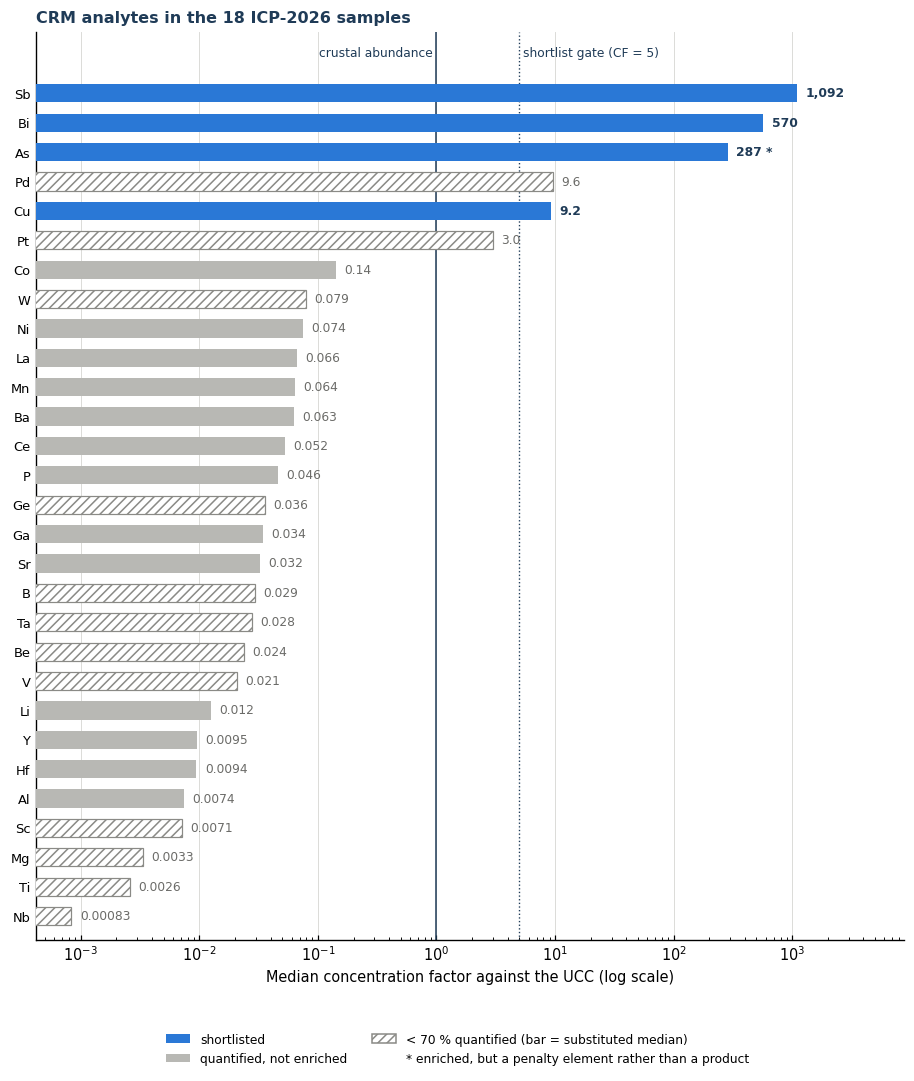

In [ ]:
# Figure 1 - concentration factor of every CRM analyte
def cf_label(x):
    return f"{x:,.0f}" if x >= 10 else (f"{x:.1f}" if x >= 1 else f"{x:.2g}")

_d = SCREEN_CRM.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.4, 0.27 * len(_d) + 2.0))
for i, r in _d.iterrows():
    short = r["Status"].startswith("shortlisted")
    poor = r["Status"] == "insufficiently quantified"
    ax.barh(i, r["CF median"], left=0, height=0.62,
            color=(C_SERIES[0] if short else ("white" if poor else "#b8b8b4")),
            edgecolor=("#8a8a86" if poor else "none"), linewidth=0.8, hatch=("////" if poor else None), zorder=3)
    lab = cf_label(r["CF median"]) + (" *" if r["Element"] in DELETERIOUS else "")
    ax.text(r["CF median"] * 1.18, i, lab, va="center", ha="left", fontsize=8,
            color=C_INK if short else C_MUTED, fontweight="bold" if short else "normal")
ax.set_xscale("log")
ax.set_xlim(SCREEN_CRM["CF median"].min() * 0.5, SCREEN_CRM["CF median"].max() * 8)
ax.set_yticks(range(len(_d)))
ax.set_yticklabels(_d["Element"], fontsize=8.5)
ax.axvline(1.0, color=C_INK, lw=1.0, zorder=2)
ax.axvline(SHORTLIST_MIN_CF, color=C_INK, lw=0.9, ls=":", zorder=2)
ax.text(0.93, len(_d) + 0.15, "crustal abundance", fontsize=8, color=C_INK, va="bottom", ha="right")
ax.text(SHORTLIST_MIN_CF * 1.08, len(_d) + 0.15, f"shortlist gate (CF = {SHORTLIST_MIN_CF:g})", fontsize=8, color=C_INK,
        va="bottom", ha="left")
ax.set_ylim(-0.8, len(_d) + 1.1)
ax.grid(axis="x", color=C_GRID, lw=0.6, zorder=0)
ax.set_xlabel("Median concentration factor against the UCC (log scale)")
ax.set_title(f"CRM analytes in the {len(SAMP)} ICP-2026 samples", loc="left",
             fontweight="bold", color=C_INK)
_h = [Patch(fc=C_SERIES[0], label="shortlisted"), Patch(fc="#b8b8b4", label="quantified, not enriched"),
      Patch(fc="white", ec="#8a8a86", hatch="////", label=f"< {SHORTLIST_MIN_QUANT_PCT:g} % quantified (bar = substituted median)")]
if any(e in DELETERIOUS for e in SHORTLIST):
    _h.append(Line2D([0], [0], color="none", label="* enriched, but a penalty element rather than a product"))
fig.legend(handles=_h, loc="lower center", ncol=2, fontsize=8, frameon=False, bbox_to_anchor=(0.5, 0.0))
plt.tight_layout(rect=(0, 0.07, 1, 1))
savefig(fig, "Fig1_CRM_concentration_factors_ICP2026")
plt.show()

### 5.3 · What the shortlisted CRMs travel with

In [ ]:
CO_PRODUCTS = [e for e in ("Pb", "Ag", "Au", "Zn", "Sn", "In", "Hg", "Se") if e in META.index]
rows = []
for el in CO_PRODUCTS:
    z, f = located_ppm(el)
    n_odl = int(np.sum(f == "odl"))
    rows.append({"Element": el, "n samples": len(z), "n > UDL": n_odl,
                 "Median (ppm)": (">= " if n_odl >= len(z) / 2 else "") + fmt_num(float(np.median(z))),
                 "Max (ppm)": ("> " if n_odl else "") + fmt_num(float(np.max(z))),
                 "Crust (ppm)": fmt_num(UCC_PPM[el]),
                 "CF median": (">= " if n_odl >= len(z) / 2 else "") + fmt_num(float(np.median(z)) / UCC_PPM[el])})
CONTEXT_TABLE = pd.DataFrame(rows)
print("Non-CRM elements reported by the same package (context only; '>=' marks a lower bound set by the upper limit):")
show_table(CONTEXT_TABLE)

_corr_els = RES_ELS + [e for e in ("Pb", "Ag", "Au", "Fe", "Zn") if e in META.index]
_q = {}
for el in _corr_els:
    f = FLAG[el].to_numpy()[LOCATED]
    v = VAL[el].to_numpy(float)[LOCATED]
    _q[el] = np.where(f == "ok", v, np.nan)
SPEARMAN = pd.DataFrame(_q).corr(method="spearman", min_periods=10)
_few = [c for c in SPEARMAN.columns if SPEARMAN[c].drop(c).isna().all()]
SPEARMAN = SPEARMAN.drop(index=_few, columns=_few)
if _few:
    print(f"\n(fewer than 10 quantified values for a rank correlation: {', '.join(_few)} - mostly above the upper limit)")
print(f"\nSpearman rank correlation, {int(LOCATED.sum())} located samples, quantified values only:")
display(SPEARMAN.round(2))
if all(e in SPEARMAN for e in ("Sb", "Bi", "Cu")):
    print(f"  Sb-Bi {SPEARMAN.loc['Sb', 'Bi']:+.2f}   |   Cu-Sb {SPEARMAN.loc['Cu', 'Sb']:+.2f}   Cu-Bi {SPEARMAN.loc['Cu', 'Bi']:+.2f}"
          + (f"   |   Bi-Au {SPEARMAN.loc['Bi', 'Au']:+.2f}   Sb-Au {SPEARMAN.loc['Sb', 'Au']:+.2f}" if "Au" in SPEARMAN else ""))
    if SPEARMAN.loc["Sb", "Bi"] > 0.5 and SPEARMAN.loc["Cu", "Bi"] < -0.3:
        print("  -> as in r2, Sb and Bi rise and fall together and Cu varies against them: a Sb-Bi(-Au) material and a "
              "Cu(-Fe) material,\n     so one mean grade for the whole polygon is a simplification.")

Non-CRM elements reported by the same package (context only; '>=' marks a lower bound set by the upper limit):


Element,n samples,n > UDL,Median (ppm),Max (ppm),Crust (ppm),CF median
Pb,18,15,">= 10,000","> 10,000",17,>= 588.2
Ag,18,10,>= 100,> 100,0.053,">= 1,887"
Au,18,0,0.7076,4.543,0.0015,471.8
Zn,18,0,373.5,"2,024",67,5.574
Sn,18,12,>= 100,> 100,2.1,>= 47.62
In,18,0,0.53,4.6,0.056,9.464
Hg,18,10,>= 50,> 50,0.05,">= 1,000"
Se,18,5,32.3,> 100,0.09,358.9



(fewer than 10 quantified values for a rank correlation: Pb, Ag - mostly above the upper limit)

Spearman rank correlation, 18 located samples, quantified values only:


,Sb,Bi,As,Cu,Au,Fe,Zn
Sb,1.00,0.90,0.32,-0.13,0.91,-0.23,0.36
Bi,0.90,1.00,0.10,-0.24,0.89,-0.21,0.15
As,0.32,0.10,1.00,0.58,0.16,0.43,0.48
Cu,-0.13,-0.24,0.58,1.00,-0.25,0.81,0.60
Au,0.91,0.89,0.16,-0.25,1.00,-0.37,0.33
Fe,-0.23,-0.21,0.43,0.81,-0.37,1.00,0.37
Zn,0.36,0.15,0.48,0.60,0.33,0.37,1.00


  Sb-Bi +0.90   |   Cu-Sb -0.13   Cu-Bi -0.24   |   Bi-Au +0.89   Sb-Au +0.91


## 6 · Stage C mapping domain, DEM, and the 193 m base

In [ ]:
def parse_kmz_boundary(kmz_path, epsg_out=EPSG_UTM):
    """Outer ring of the first polygon in a KMZ, projected to UTM; (None, None) if unavailable."""
    if not Path(kmz_path).exists():
        return None, None
    try:
        with zipfile.ZipFile(kmz_path) as z:
            kml_name = next(n for n in z.namelist() if n.endswith(".kml"))
            root = ET.fromstring(z.read(kml_name).decode("utf-8"))
        node = next((e for e in root.iter() if e.tag.endswith("outerBoundaryIs")), None)
        node = next((e for e in (node.iter() if node is not None else root.iter())
                     if e.tag.endswith("coordinates")), None)
        if node is None or not (node.text and node.text.strip()):
            print("  KMZ parse warning: no coordinate node found.")
            return None, None
        pts = [tuple(map(float, t.split(",")[:2])) for t in node.text.split() if len(t.split(",")) >= 2]
        if len(pts) < 3:
            return None, None
        xs, ys = lonlat_to_utm([p[0] for p in pts], [p[1] for p in pts], epsg=epsg_out)
        if not (xs[0] == xs[-1] and ys[0] == ys[-1]):
            xs, ys = np.append(xs, xs[0]), np.append(ys, ys[0])
        return xs, ys
    except Exception as e:
        print(f"  KMZ parse error: {e}")
        return None, None

XY_ALL = SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(float)
px_utm, py_utm = parse_kmz_boundary(KMZ_FILE)
KMZ_LOADED = px_utm is not None
if KMZ_LOADED:
    print(f"KMZ boundary loaded: {len(px_utm) - 1} vertices")
elif SHAPELY_OK:
    _hull = MultiPoint([tuple(p) for p in XY_ALL]).convex_hull.buffer(60)
    px_utm, py_utm = map(np.array, _hull.exterior.coords.xy)
    print(f"'{KMZ_FILE}' not found - using the convex hull of the located ICP samples buffered by 60 m.")
else:
    from scipy.spatial import ConvexHull
    h = ConvexHull(XY_ALL)
    px_utm = np.append(XY_ALL[h.vertices, 0], XY_ALL[h.vertices[0], 0])
    py_utm = np.append(XY_ALL[h.vertices, 1], XY_ALL[h.vertices[0], 1])
    print(f"'{KMZ_FILE}' not found - using the plain convex hull of the located samples.")

BND_PATH = MPath(np.column_stack([px_utm, py_utm]))
if SHAPELY_OK:
    boundary_poly = ShapelyPolygon(zip(px_utm, py_utm))
    boundary_poly = boundary_poly if boundary_poly.is_valid else boundary_poly.buffer(0)
    print(f"  Boundary area: {boundary_poly.area / 1e4:.2f} ha")
else:
    boundary_poly = None

def inside_domain(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if SHAPELY_OK and hasattr(shapely, "contains_xy"):
        return shapely.contains_xy(boundary_poly, x, y)
    return BND_PATH.contains_points(np.column_stack([x, y]))

SAMP["In_domain"] = False
SAMP.loc[LOCATED, "In_domain"] = inside_domain(XY_ALL[:, 0], XY_ALL[:, 1])
xmin_u, xmax_u = float(px_utm.min()), float(px_utm.max())
ymin_u, ymax_u = float(py_utm.min()), float(py_utm.max())
pad_x, pad_y = (xmax_u - xmin_u) * PAD_FRAC, (ymax_u - ymin_u) * PAD_FRAC
BND_LABEL = "Waste polygon" if KMZ_LOADED else "60 m buffered hull"
BND_LEGEND = "Waste boundary" if KMZ_LOADED else "Mapping domain"
n_out = int((SAMP.loc[LOCATED, "In_domain"] == False).sum())
print(f"  Located samples outside the domain: {n_out}"
      + (f" -> {', '.join(SAMP.loc[LOCATED & ~SAMP['In_domain'], 'Sample'])}" if n_out else ""))

KMZ boundary loaded: 146 vertices
  Boundary area: 16.25 ha
  Located samples outside the domain: 1 -> LG_26_G2_14


In [ ]:
from scipy import ndimage as ndi

def read_usgs_dem(path):
    """Read a USGS ASCII DEM (record A header + one record B per profile, 1024-byte blocks).
    Profiles run south -> north and are ordered west -> east; each carries its own starting northing, so profiles of
    different length are placed on one lattice. Returns (header, x[nx], y[ny] north -> south, Z[ny, nx] with NaN voids)."""
    raw = Path(path).read_bytes().decode("ascii", errors="replace")
    fl = lambda s: float(s.replace("D", "E"))
    A = raw[:1024]
    hdr = dict(ref_sys=int(A[156:162]), zone=int(A[162:168]), xy_unit=int(A[528:534]), z_unit=int(A[534:540]),
               corners=[(fl(A[546 + 48 * k:570 + 48 * k]), fl(A[570 + 48 * k:594 + 48 * k])) for k in range(4)],
               zmin=fl(A[738:762]), zmax=fl(A[762:786]),
               dx=float(A[816:828]), dy=float(A[828:840]), dz=float(A[840:852]), n_profiles=int(A[858:864]))
    pos, profs = 1024, []
    for _ in range(hdr["n_profiles"]):
        B = raw[pos:pos + 1024]
        m = int(B[12:18])                                         # number of elevations in this profile
        xgo, ygo, datum = fl(B[24:48]), fl(B[48:72]), fl(B[72:96])
        vals = [int(B[144 + 6 * k:150 + 6 * k]) for k in range(min(m, 146))]
        pos += 1024
        while len(vals) < m:                                      # continuation blocks hold 170 values each
            B = raw[pos:pos + 1024]
            vals += [int(B[6 * k:6 * k + 6]) for k in range(min(m - len(vals), 170))]
            pos += 1024
        profs.append((xgo, ygo, datum, np.asarray(vals, float)))
    hdr["bytes_read"], hdr["bytes_total"] = pos, len(raw)
    dx, dy = hdr["dx"], hdr["dy"]
    full = [p for p in profs if len(p[3])]
    y_min = min(p[1] for p in full)
    y_max = max(p[1] + (len(p[3]) - 1) * dy for p in full)
    ny, nx = int(round((y_max - y_min) / dy)) + 1, len(profs)
    Z = np.full((ny, nx), np.nan)
    for j, (x0, y0, datum, v) in enumerate(profs):
        if not len(v):
            continue
        k0 = (y0 - y_min) / dy
        if abs(k0 - round(k0)) > 1e-6:
            raise ValueError("DEM profiles do not share one northing lattice.")
        k = int(round(k0)) + np.arange(len(v))
        ok = v > -32000
        Z[ny - 1 - k[ok], j] = v[ok] * hdr["dz"] + datum
    x = np.array([p[0] for p in profs])
    if not np.allclose(np.diff(x), dx, atol=1e-6):
        raise ValueError("DEM profiles are not equally spaced in easting.")
    return hdr, x, y_max - np.arange(ny) * dy, Z

DEM_HDR, DEM_X, DEM_Y, DEM_Z = read_usgs_dem(DEM_FILE)
DX, DY, DZ_STEP = DEM_HDR["dx"], DEM_HDR["dy"], DEM_HDR["dz"]
CELL_AREA = DX * DY
if not (DEM_HDR["ref_sys"] == 1 and DEM_HDR["zone"] == int(EPSG_UTM[-2:]) and DEM_HDR["xy_unit"] == 2 and DEM_HDR["z_unit"] == 2):
    raise ValueError(f"DEM is not UTM zone {EPSG_UTM[-2:]} in metres: {DEM_HDR}")
VALID = np.isfinite(DEM_Z)
_XX, _YY = np.meshgrid(DEM_X, DEM_Y)
xv, yv, zv = _XX[VALID], _YY[VALID], DEM_Z[VALID]
DEM_AREA = VALID.sum() * CELL_AREA
_in = inside_domain(xv, yv)
_levels = np.unique(zv)

print(f"DEM  : {DEM_Z.shape[1]} x {DEM_Z.shape[0]} nodes at {DX:g} m, {int(VALID.sum()):,} with data "
      f"({DEM_AREA / 1e4:.2f} ha); file fully parsed: {DEM_HDR['bytes_read'] == DEM_HDR['bytes_total']}")
print(f"       UTM zone {DEM_HDR['zone']}, metres; E {DEM_X.min():.1f}-{DEM_X.max():.1f}, N {DEM_Y.min():.1f}-{DEM_Y.max():.1f}")
print(f"       elevation {zv.min():g} - {zv.max():g} m in the data (header: {DEM_HDR['zmin']:g} - {DEM_HDR['zmax']:g} m); "
      f"vertical step {DZ_STEP:g} m -> {len(_levels)} distinct levels")
print(f"       against the KMZ polygon ({boundary_poly.area / 1e4:.2f} ha): {int((~_in).sum()):,} DEM nodes "
      f"({(~_in).sum() * CELL_AREA:,.0f} m2) fall outside it -> the DEM was clipped with this polygon and the two agree "
      f"to {100 * abs(DEM_AREA - boundary_poly.area) / boundary_poly.area:.2f} % in area")

DEM_CROSSCHECK = "rasterio not installed - independent read skipped"
try:
    import rasterio
    with rasterio.open(DEM_FILE) as _ds:
        _z = _ds.read(1).astype(float)
        _z[_z == _ds.nodata] = np.nan
        _t = _ds.transform
    # GDAL builds its lattice from the header corners and snaps profile origins to it; align the two by position
    _r0 = int(round(((_t.f + 0.5 * _t.e) - DEM_Y[0]) / DY))
    _c0 = int(round((DEM_X[0] - (_t.c + 0.5 * _t.a)) / DX))
    _sub = _z[_r0:_r0 + DEM_Z.shape[0], _c0:_c0 + DEM_Z.shape[1]]
    _same = (_sub.shape == DEM_Z.shape and int(np.isfinite(_z).sum()) == int(np.isfinite(_sub).sum())
             and np.array_equal(np.isnan(_sub), np.isnan(DEM_Z)) and float(np.nanmax(np.abs(_sub - DEM_Z))) == 0.0)
    _dyo = DEM_Y[0] - (_t.f + (_r0 + 0.5) * _t.e)
    _dxo = DEM_X[0] - (_t.c + (_c0 + 0.5) * _t.a)
    DEM_CROSSCHECK = (f"all {int(np.isfinite(_sub).sum()):,} elevations identical to the GDAL/rasterio read: {_same}; GDAL snaps the "
                      f"profile origins to its own lattice, {_dxo:+.3f} m E and {_dyo:+.3f} m N of the positions stored in the file "
                      f"(the stored positions are used here)")
    DEM_SAME = bool(_same)
except ImportError:
    DEM_SAME = None
except Exception as _e:
    DEM_SAME, DEM_CROSSCHECK = None, f"rasterio could not open the DEM ({str(_e)[:80]}) - independent read skipped"
print(f"       cross-check: {DEM_CROSSCHECK}")

# elevation of every located sample (nearest DEM node)
_tree = cKDTree(np.column_stack([xv, yv]))
_d, _i = _tree.query(SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(float))
SAMP["DEM_z"] = np.nan
SAMP.loc[LOCATED, "DEM_z"] = np.where(_d <= 2 * max(DX, DY), zv[_i], np.nan)
print(f"Samples: surface elevation {np.nanmin(SAMP['DEM_z']):g} - {np.nanmax(SAMP['DEM_z']):g} m; "
      f"{int(SAMP.loc[LOCATED, 'DEM_z'].isna().sum())} located sample(s) lie off the DEM "
      f"({', '.join(SAMP.loc[LOCATED & SAMP['DEM_z'].isna().to_numpy(), 'Sample']) or '-'})")

DEM  : 1149 x 1054 nodes at 0.5 m, 649,983 with data (16.25 ha); file fully parsed: True
       UTM zone 29, metres; E 661412.6-661986.6, N 4165350.2-4165876.7
       elevation 193 - 213 m in the data (header: 193 - 214 m); vertical step 1 m -> 21 distinct levels
       against the KMZ polygon (16.25 ha): 1 DEM nodes (0 m2) fall outside it -> the DEM was clipped with this polygon and the two agree to 0.00 % in area
       cross-check: all 649,983 elevations identical to the GDAL/rasterio read: True; GDAL snaps the profile origins to its own lattice, +0.000 m E and +0.154 m N of the positions stored in the file (the stored positions are used here)
Samples: surface elevation 200 - 211 m; 0 located sample(s) lie off the DEM (-)


### 6.1 · Base elevation, thickness and volume

In [ ]:
Z_BASE = float(BASE_ELEVATION_M)
_below = int(np.sum(zv < Z_BASE))
SCENARIOS = {"A": dict(label=f"Base case - horizontal base at {Z_BASE:g} m a.s.l., thickness = DEM - {Z_BASE:g} m",
                       short=f"base {Z_BASE:g} m", base=np.full_like(zv, Z_BASE))}
BASE_CASE = "A"
for s in SCENARIOS.values():
    s["th"] = np.clip(zv - s["base"], 0.0, None)        # thickness per DEM node, m
    s["volume"] = float(s["th"].sum() * CELL_AREA)      # m3
TH = SCENARIOS["A"]["th"]
TH_MEAN = float(TH.mean())
VOL_Q = 0.5 * DZ_STEP * DEM_AREA
CASE_LABEL = {"A": f"DEM thickness on the {Z_BASE:g} m base (base case)", "U": f"uniform slab, {TH_MEAN:.2f} m everywhere"}

# margin of the polygon = valid nodes with a void (or the array edge) among their 8 neighbours
RING = VALID & ~ndi.binary_erosion(VALID, structure=np.ones((3, 3)), border_value=0)
zr = DEM_Z[RING]

_bands = [(0, 5), (5, 10), (10, 15), (15, 99)]
rows = [{"Thickness class (m)": f"{a}-{b}" if b < 99 else f"> {a}", "Area (ha)": float(np.sum((TH >= a) & (TH < b)) * CELL_AREA / 1e4),
         "Volume (Mm3)": float(TH[(TH >= a) & (TH < b)].sum() * CELL_AREA / 1e6)} for a, b in _bands]
rows.append({"Thickness class (m)": "all", "Area (ha)": DEM_AREA / 1e4, "Volume (Mm3)": SCENARIOS["A"]["volume"] / 1e6})
VOLUME_TABLE = pd.DataFrame(rows)
VOLUME_TABLE["Share of volume (%)"] = 100 * VOLUME_TABLE["Volume (Mm3)"] / (SCENARIOS["A"]["volume"] / 1e6)
show_table(VOLUME_TABLE, precision=3)

print(f"Base        : {Z_BASE:g} m a.s.l.; lowest elevation in the DEM {zv.min():g} m"
      + (" (identical: the base touches the surface at its lowest point)" if zv.min() == Z_BASE else "")
      + (f"; {_below:,} DEM nodes lie below the base and are given zero thickness" if _below else ""))
print(f"Volume      : {SCENARIOS['A']['volume'] / 1e6:.3f} Mm3 over {DEM_AREA / 1e4:.2f} ha; thickness {TH.min():g} - {TH.max():g} m, "
      f"mean {TH_MEAN:.2f} m, median {np.median(TH):g} m")
print(f"Uniform slab: {DEM_AREA / 1e4:.2f} ha x {TH_MEAN:.2f} m = {DEM_AREA * TH_MEAN / 1e6:.3f} Mm3 (the same volume by construction)")
print(f"Implication : at the margin of the polygon the surface stands at {zr.min():g} - {zr.max():g} m (mean {zr.mean():.1f} m), so the "
      f"base case carries {zr.mean() - Z_BASE:.1f} m of waste\n              on average right up to the boundary. The waste is taken to "
      "end against the boundary at full thickness, not to thin out towards it.")

Thickness class (m),Area (ha),Volume (Mm3),Share of volume (%)
0-5,0.660,0.015,0.822
5-10,6.062,0.431,24.208
10-15,5.442,0.675,37.909
> 15,4.086,0.660,37.061
all,16.250,1.780,100.000


Base        : 193 m a.s.l.; lowest elevation in the DEM 193 m (identical: the base touches the surface at its lowest point)
Volume      : 1.780 Mm3 over 16.25 ha; thickness 0 - 20 m, mean 10.96 m, median 11 m
Uniform slab: 16.25 ha x 10.96 m = 1.780 Mm3 (the same volume by construction)
Implication : at the margin of the polygon the surface stands at 193 - 213 m (mean 203.8 m), so the base case carries 10.8 m of waste
              on average right up to the boundary. The waste is taken to end against the boundary at full thickness, not to thin out towards it.


### 6.2 · Block model

The 3 m lattice of the OK and IDW notebooks is kept. Every DEM node is assigned to its nearest lattice node, and a
block's area, mean surface elevation and volume are sums over its DEM nodes. The total volume is therefore
conserved exactly, which the audit in Section 14 verifies.

In [ ]:
G = float(GRID_DENSITY_M)
_ix = np.rint((xv - xmin_u) / G).astype(np.int64)
_iy = np.rint((yv - ymin_u) / G).astype(np.int64)
if _ix.min() < 0 or _iy.min() < 0:
    raise ValueError("DEM extends beyond the polygon's bounding box - check that the DEM and the KMZ belong together.")
NCOL, NROW = int(_ix.max()) + 1, int(_iy.max()) + 1
_key, BLK_INV = np.unique(_iy * NCOL + _ix, return_inverse=True)
BLK_INV = np.asarray(BLK_INV).ravel()
BLK_IX, BLK_IY = _key % NCOL, _key // NCOL
BLK_XY = np.column_stack([xmin_u + BLK_IX * G, ymin_u + BLK_IY * G])
BLK_N = np.bincount(BLK_INV)
BLK_AREA = BLK_N * CELL_AREA
BLK_Z = np.bincount(BLK_INV, weights=zv) / BLK_N
BLK_VOL = {"A": np.bincount(BLK_INV, weights=TH * CELL_AREA),
           "U": BLK_AREA * TH_MEAN}          
BLK_TH = {k: BLK_VOL[k] / BLK_AREA for k in BLK_VOL}
NB = len(BLK_AREA)
XG = xmin_u + np.arange(NCOL) * G
YG = ymin_u + np.arange(NROW) * G

def to_grid(vals):
    """Block values -> (NROW, NCOL) raster, row 0 = south, NaN outside the model."""
    g = np.full(NROW * NCOL, np.nan)
    g[_key] = vals
    return g.reshape(NROW, NCOL)

print(f"Block model: {NB:,} blocks of {G:g} x {G:g} m on a {NCOL} x {NROW} lattice; {int((BLK_N < (G / DX) * (G / DY)).sum()):,} "
      f"partial blocks along the margin")
print(f"  area {BLK_AREA.sum() / 1e4:.3f} ha   |   volume {BLK_VOL['A'].sum() / 1e6:.4f} Mm3 (base case)   "
      f"{BLK_VOL['U'].sum() / 1e6:.4f} Mm3 (uniform slab)")
print(f"  tonnage at {BULK_DENSITY['base']:.2f} t/m3 (base case): {BULK_DENSITY['base'] * BLK_VOL['A'].sum() / 1e6:.2f} Mt")

Block model: 18,399 blocks of 3 x 3 m on a 192 x 177 lattice; 675 partial blocks along the margin
  area 16.250 ha   |   volume 1.7802 Mm3 (base case)   1.7802 Mm3 (uniform slab)
  tonnage at 1.25 t/m3 (base case): 2.23 Mt


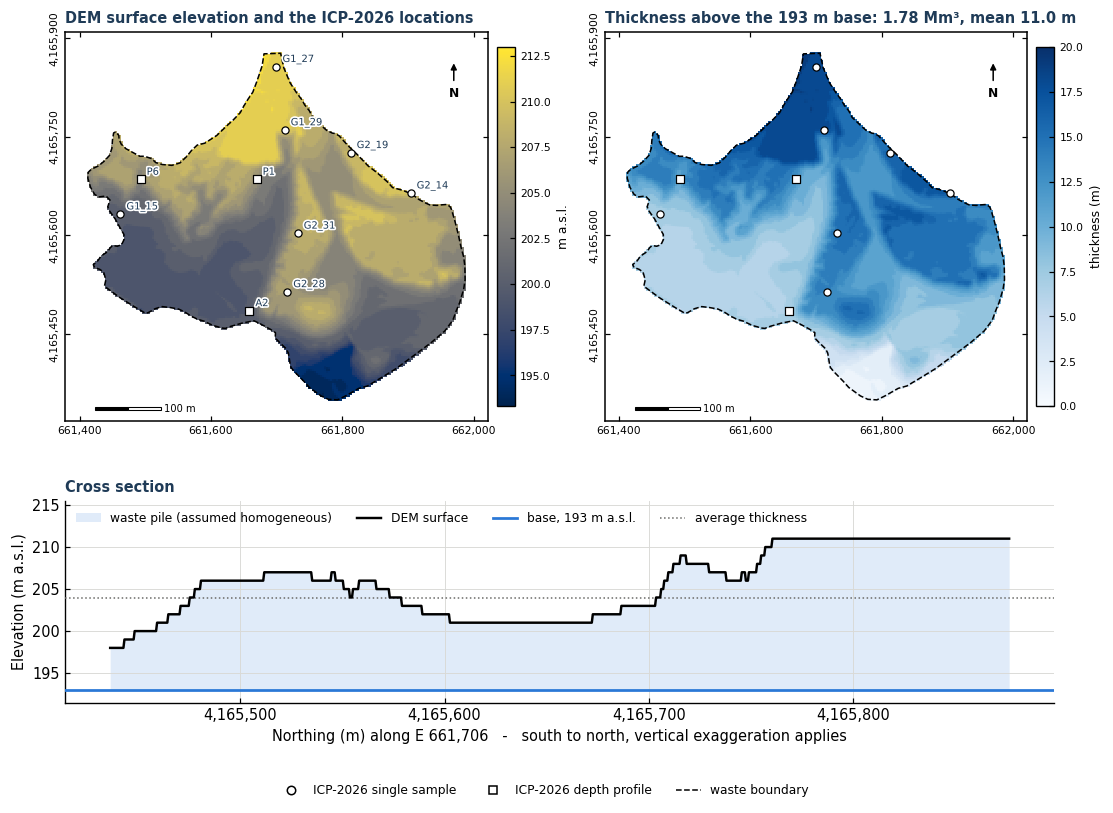

Station,Kind,In polygon,DEM z (m),Thickness above base (m),Deepest sample (m),Share of thickness sampled (%)
G1_15,single sample,True,200.0,7.0,,
G1_27,single sample,True,211.0,18.0,,
G1_29,single sample,True,211.0,18.0,,
G2_14,single sample,False,210.0,17.0,,
G2_19,single sample,True,208.0,15.0,,
G2_28,single sample,True,206.0,13.0,,
G2_31,single sample,True,208.0,15.0,,
P1,profile,True,205.0,12.0,0.5,4.2
P6,profile,True,204.0,11.0,3.0,27.3
A2,profile,True,200.0,7.0,0.4,5.9


The deepest profile reaches 3.0 m: P1 samples 4 % of its 12 m; P6 samples 27 % of its 11 m; A2 samples 6 % of its 7 m. Below that, and at every single-sample station, the grade at depth is the base-case assumption, not data.


In [ ]:
# Figure 2 - surface, thickness above the 193 m base, and a south-north section, with the ICP-2026 stations
EXTENT = [XG[0] - G / 2, XG[-1] + G / 2, YG[0] - G / 2, YG[-1] + G / 2]
pad_x, pad_y = (xmax_u - xmin_u) * PAD_FRAC, (ymax_u - ymin_u) * PAD_FRAC

def map_frame(ax, title=None, scale_bar=True, north=True, ylabels=True):
    """Neatline, boundary, plain UTM ticks, scale bar and north arrow (r2)."""
    for s in ax.spines.values():
        s.set_visible(True); s.set_linewidth(1.0); s.set_color("black")
    ax.plot(px_utm, py_utm, color="black", lw=1.0, ls="--", zorder=8)
    ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x); ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4)); ax.yaxis.set_major_locator(mticker.MaxNLocator(4))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(labelsize=7, top=True, right=True, length=3)
    for lab in ax.get_yticklabels():
        lab.set_rotation(90); lab.set_va("center")
    if not ylabels:
        ax.set_yticklabels([])
    if title:
        ax.set_title(title, loc="left", fontweight="bold", color=C_INK, fontsize=9.5)
    if scale_bar:
        sx, sy = xmin_u + 0.02 * (xmax_u - xmin_u), ymin_u - 0.5 * pad_y
        for i in range(2):
            ax.add_patch(Rectangle((sx + 50 * i, sy), 50, 5, fc="black" if i == 0 else "white", ec="black", lw=0.7, zorder=9))
        ax.text(sx + 104, sy + 2.5, "100 m", fontsize=6.5, va="center", ha="left", zorder=9)
    if north:
        nx_, ny_ = xmax_u - 0.03 * (xmax_u - xmin_u), ymax_u - 0.02 * (ymax_u - ymin_u)
        ax.annotate("N", xy=(nx_, ny_), xytext=(nx_, ny_ - 50), ha="center", va="center", fontsize=8, fontweight="bold",
                    arrowprops=dict(arrowstyle="-|>", color="black", lw=1.0), zorder=9)

_PROF = STATION_LIST["Kind"].eq("profile").to_numpy()

def plot_stations(ax, labels=True, size=1.0):
    """ICP-2026 stations: circles = single samples, squares = depth profiles."""
    sx, sy = STATION_LIST["X_utm"].to_numpy(float), STATION_LIST["Y_utm"].to_numpy(float)
    ax.scatter(sx[~_PROF], sy[~_PROF], s=22 * size, marker="o", c="white", edgecolors="black", linewidths=0.8, zorder=10)
    ax.scatter(sx[_PROF], sy[_PROF], s=30 * size, marker="s", c="white", edgecolors="black", linewidths=0.8, zorder=10)
    if labels:
        import matplotlib.patheffects as mpe
        for x_, y_, t_ in zip(sx, sy, STATION_LIST["Station"]):
            ax.annotate(t_, (x_, y_), xytext=(4, 3), textcoords="offset points", fontsize=6.5, color=C_INK, zorder=11,
                        path_effects=[mpe.withStroke(linewidth=2.2, foreground="white")])

STATION_HANDLES = [Line2D([0], [0], marker="o", color="w", mfc="white", mec="black", ms=5.5, label="ICP-2026 single sample"),
                   Line2D([0], [0], marker="s", color="w", mfc="white", mec="black", ms=5.5, label="ICP-2026 depth profile")]

_thmax = float(np.ceil(BLK_TH["A"].max()))
fig = plt.figure(figsize=(11.6, 8.0))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.50], hspace=0.24, wspace=0.20)
ax = fig.add_subplot(gs[0, 0])
im = ax.imshow(to_grid(BLK_Z), extent=EXTENT, origin="lower", cmap="cividis", interpolation="nearest", zorder=1)
plot_stations(ax)
map_frame(ax, "DEM surface elevation and the ICP-2026 locations")
cb = fig.colorbar(im, ax=ax, fraction=0.040, pad=0.02); cb.set_label("m a.s.l.", fontsize=8); cb.ax.tick_params(labelsize=7)
ax = fig.add_subplot(gs[0, 1])
im = ax.imshow(to_grid(BLK_TH["A"]), extent=EXTENT, origin="lower", cmap="Blues", vmin=0, vmax=_thmax, interpolation="nearest", zorder=1)
plot_stations(ax, labels=False)
map_frame(ax, f"Thickness above the {Z_BASE:g} m base: {SCENARIOS['A']['volume'] / 1e6:.2f} Mm³, mean {TH_MEAN:.1f} m")
cb = fig.colorbar(im, ax=ax, fraction=0.040, pad=0.02); cb.set_label("thickness (m)", fontsize=8); cb.ax.tick_params(labelsize=7)

# south-north section along the DEM column with the longest run of data
_jc = int(np.argmax(VALID.sum(axis=0)))
_rows = np.flatnonzero(VALID[:, _jc])
_ysec, _zsec = DEM_Y[_rows], DEM_Z[_rows, _jc]
ax = fig.add_subplot(gs[1, :])
ax.fill_between(_ysec, np.full_like(_zsec, Z_BASE), _zsec, color=C_SERIES[0], alpha=0.14, lw=0, zorder=1,
                label="waste pile (assumed homogeneous)")
ax.plot(_ysec, _zsec, color="black", lw=1.6, label="DEM surface", zorder=5)
ax.axhline(Z_BASE, color=C_SERIES[0], lw=1.8, label=f"base, {Z_BASE:g} m a.s.l.", zorder=4)
ax.axhline(Z_BASE + TH_MEAN, color=C_MUTED, lw=1.0, ls=":", label=f"average thickness", zorder=3)
ax.set_xlabel(f"Northing (m) along E {DEM_X[_jc]:,.0f}   -   south to north, vertical exaggeration applies")
ax.set_ylabel("Elevation (m a.s.l.)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(color=C_GRID, lw=0.6)
ax.set_ylim(Z_BASE - 1.5, float(_zsec.max()) + 4.5)
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper left")
ax.set_title("Cross section", loc="left", fontweight="bold", color=C_INK, fontsize=9.5)
fig.legend(handles=STATION_HANDLES + [Line2D([0], [0], color="black", lw=1.0, ls="--", label="waste boundary")],
           loc="lower center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.01))
savefig(fig, "Fig2_DEM_thickness_base_193m_ICP2026_stations")
plt.show()

# station geometry: surface elevation, waste thickness above the base, and the share of it that a profile samples
_d, _i = _tree.query(STATION_LIST[["X_utm", "Y_utm"]].to_numpy(float))
STATION_LIST["In polygon"] = np.asarray(inside_domain(STATION_LIST["X_utm"], STATION_LIST["Y_utm"]), bool)
STATION_LIST["DEM z (m)"] = np.where(_d <= 2 * max(DX, DY), zv[_i], np.nan)
STATION_LIST["Thickness above base (m)"] = np.clip(STATION_LIST["DEM z (m)"] - Z_BASE, 0, None)
_deep = SAMP[LOCATED].groupby("Station_no")["Base_cm"].max().reindex(STATION_LIST["Station_no"]).to_numpy() / 100
STATION_LIST["Deepest sample (m)"] = _deep
STATION_LIST["Share of thickness sampled (%)"] = 100 * _deep / STATION_LIST["Thickness above base (m)"]
show_table(STATION_LIST[["Station", "Kind", "In polygon", "DEM z (m)", "Thickness above base (m)", "Deepest sample (m)",
                         "Share of thickness sampled (%)"]], precision=1)
_pr = STATION_LIST[STATION_LIST["Kind"] == "profile"]
print(f"The deepest profile reaches {np.nanmax(_deep):.1f} m: "
      + "; ".join(f"{r['Station']} samples {r['Share of thickness sampled (%)']:.0f} % of its {r['Thickness above base (m)']:.0f} m"
                  for _, r in _pr.iterrows())
      + f". Below that, and at every single-sample station, the grade at depth is the base-case assumption, not data.")

## 7 · Stage D stations of the shortlisted CRMs

In [ ]:
def sample_ppm(el):
    """Every sample of `el` in ppm (censored values substituted, r2 factors) and its flag, in file order."""
    f = FLAG[el].to_numpy()
    v = VAL[el].to_numpy(float)
    z = np.where(f == "ok", v, np.where(f == "bdl", BDL_FACTOR * v, np.where(f == "odl", ODL_FACTOR * v, np.nan)))
    return z * TO_PPM[META.loc[el, "unit"]], f

_STNO = SAMP["Station_no"].to_numpy()

def station_values(el, rule=STATION_VALUE):
    """One value (ppm) and one flag string per station of STATION_LIST under `rule` ('depth' | 'equal' | 'surface')."""
    z, f = sample_ppm(el)
    vals, flags = [], []
    for s, kind in zip(STATION_LIST["Station_no"], STATION_LIST["Kind"]):
        idx = np.flatnonzero((_STNO == s) & LOCATED & np.isfinite(z))
        if idx.size == 0:
            vals.append(np.nan); flags.append(""); continue
        if kind == "profile" and rule == "surface":
            idx = idx[[int(np.argmin(SAMP["Top_cm"].to_numpy()[idx]))]]
            vals.append(float(z[idx[0]]))
        elif kind == "profile" and rule == "depth":
            w = SAMP["Depth_w_cm"].to_numpy()[idx]
            vals.append(float(np.sum(w * z[idx]) / np.sum(w)))
        else:
            vals.append(float(np.mean(z[idx])))
        flags.append(",".join(sorted(set(f[idx]))))
    return np.asarray(vals, float), np.asarray(flags, dtype=object)

STATIONS, ALT, rows = {}, {}, []
_names = STATION_LIST["Station"].to_numpy()
_coords_all = STATION_LIST[["X_utm", "Y_utm"]].to_numpy(float)
for el in RES_ELS:
    v, fl = station_values(el, STATION_VALUE)
    keep = np.isfinite(v)
    coords, v, fl = _coords_all[keep], v[keep], fl[keep]
    n = len(v)
    if n < 3 or len(np.unique(v)) < MIN_DISTINCT_VALS:
        raise ValueError(f"{el}: {n} stations with an assay - too few for a mean grade.")
    w, cell, _ = declustering_weights(coords, v)
    inside = np.asarray(inside_domain(coords[:, 0], coords[:, 1]), bool)
    odl = np.array(["odl" in x for x in fl])
    bdl = np.array(["bdl" in x for x in fl])
    sd = float(np.std(v, ddof=1))
    imax = int(np.argmax(np.abs(v - v.mean())))
    nn = cKDTree(coords).query(coords, k=2)[0][:, 1]
    STATIONS[el] = dict(coords=coords, v=v, w=w, cell=cell, inside=inside, odl=odl, bdl=bdl, names=_names[keep],
                        kind=STATION_LIST["Kind"].to_numpy()[keep], spacing=float(np.median(nn)), ex_d=float(nn.max()))
    ALT[el] = {r_: station_values(el, r_)[0][keep] for r_ in ("depth", "equal", "surface")}
    rows.append({"Element": el, "Stations": n, "Profiles": int((STATIONS[el]["kind"] == "profile").sum()),
                 "> UDL": int(odl.sum()), "< MDL": int(bdl.sum()), "Outside polygon": int((~inside).sum()),
                 "Mean (ppm)": v.mean(), "Median (ppm)": float(np.median(v)), "Min": v.min(), "Max": v.max(),
                 "CV": sd / v.mean(), "Skewness": float(stats.skew(v)),
                 "Cell-declustered mean": float(np.sum(w * v) / w.sum()), "Declustering cell (m)": cell,
                 "Top-1 share of variance": float(((v[imax] - v.mean()) ** 2 / (n - 1)) / sd ** 2),
                 "Most extreme station": _names[keep][imax]})
STATION_TABLE = pd.DataFrame(rows)
show_table(STATION_TABLE, precision=3)

STATION_VALUES = STATION_LIST[["Station", "Kind", "Depth (cm)"]].copy()
for el in RES_ELS:
    v_all = station_values(el, STATION_VALUE)[0]
    STATION_VALUES[f"{el} (ppm)"] = v_all
print(f"\nStation values used for the tonnage ('{STATION_VALUE}' composites):")
show_table(STATION_VALUES, precision=1)
for el in RES_ELS:
    S = STATIONS[el]
    if S["odl"].any():
        print(f"  {el}: {int(S['odl'].sum())} station(s) contain over-range assays held AT the limit "
              f"({', '.join(S['names'][S['odl']])}) -> the {el} grades below are lower bounds.")
    if S["bdl"].any():
        print(f"  {el}: {int(S['bdl'].sum())} station(s) contain '< MDL' assays at {BDL_FACTOR:g} x MDL.")
_out = STATIONS[RES_ELS[0]]
if (~_out["inside"]).any():
    _c = _out["coords"][~_out["inside"]]
    _dist = [boundary_poly.exterior.distance(Point(*c)) for c in _c] if SHAPELY_OK else [np.nan] * len(_c)
    print(f"  Outside the polygon: {', '.join(_out['names'][~_out['inside']])} "
          f"({', '.join(f'{d:.1f} m' for d in _dist)} from the boundary; kept, and tested in the sensitivity analysis).")
else:
    print("  Every station lies inside the waste polygon.")

Element,Stations,Profiles,> UDL,< MDL,Outside polygon,Mean (ppm),Median (ppm),Min,Max,CV,Skewness,Cell-declustered mean,Declustering cell (m),Top-1 share of variance,Most extreme station
Sb,10,3,0,0,1,448.880,435.250,18.18,912.91,0.678,0.085,442.263,215.0,0.259,G2_14
Bi,10,3,0,0,1,107.359,86.245,5.74,279.34,0.819,0.854,101.020,215.0,0.425,P1
As,10,3,0,0,1,2424.442,1379.550,349.20,5712.60,0.867,0.658,2292.609,156.6,0.272,G2_31
Cu,10,3,0,0,1,617.726,331.120,48.22,2725.53,1.314,1.930,609.298,150.7,0.749,G2_14



Station values used for the tonnage ('depth' composites):


Station,Kind,Depth (cm),Sb (ppm),Bi (ppm),As (ppm),Cu (ppm)
G1_15,single sample,,214.0,53.6,417.3,86.0
G1_27,single sample,,81.6,23.6,1372.8,220.9
G1_29,single sample,,18.2,5.7,349.2,441.3
G2_14,single sample,,912.9,134.7,5389.5,2725.5
G2_19,single sample,,354.7,66.8,1386.3,48.2
G2_28,single sample,,515.8,105.7,4879.2,988.7
G2_31,single sample,,538.2,115.8,5712.6,902.5
P1,profile,0-50,782.2,279.3,865.0,109.1
P6,profile,10-300,752.5,229.4,1353.4,175.9
A2,profile,0-41,318.8,58.9,2519.1,479.1


  Outside the polygon: G2_14 (0.8 m from the boundary; kept, and tested in the sensitivity analysis).


### 7.1 · What the profiles say about the vertical-homogeneity assumption

Element,Profile,Depth (cm),Shallowest (ppm),Composite (ppm),Deepest (ppm),Shallowest / composite,Shallowest / deepest,Max / min in profile
Sb,P1,0-50,924.12,782.21,722.94,1.18,1.28,1.33
Sb,P6,10-300,1628.40,752.46,626.08,2.16,2.60,9.48
Sb,A2,0-41,237.93,318.75,471.44,0.75,0.50,1.98
Bi,P1,0-50,348.28,279.34,280.07,1.25,1.24,1.59
Bi,P6,10-300,447.21,229.35,219.67,1.95,2.04,6.32
Bi,A2,0-41,58.62,58.93,76.68,0.99,0.76,1.41
As,P1,0-50,852.20,865.04,681.30,0.99,1.25,1.45
As,P6,10-300,2086.60,1353.37,973.90,1.54,2.14,2.96
As,A2,0-41,1723.10,2519.11,5038.50,0.68,0.34,2.92
Cu,P1,0-50,90.82,109.13,122.06,0.83,0.74,1.34


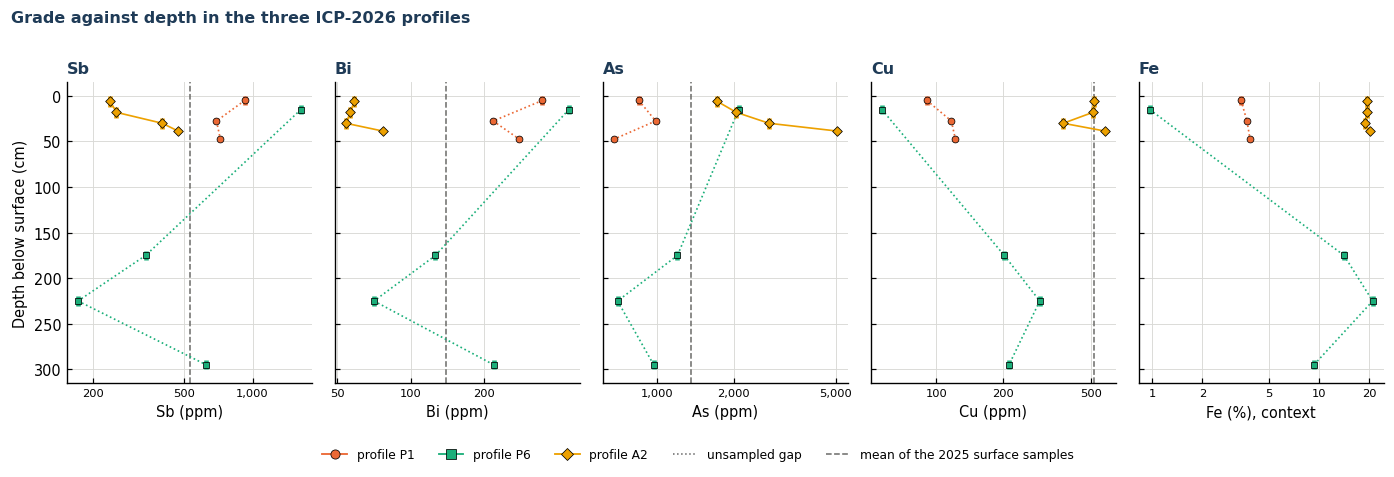

  Sb  shallowest / deepest interval: P1 1.28, P6 2.60, A2 0.50
  Bi  shallowest / deepest interval: P1 1.24, P6 2.04, A2 0.76
  As  shallowest / deepest interval: P1 1.25, P6 2.14, A2 0.34
  Cu  shallowest / deepest interval: P1 0.74, P6 0.27, A2 0.90


In [ ]:
PROFILE_ELS = list(RES_ELS) + (["Fe"] if "Fe" in META.index and "Fe" not in RES_ELS else [])
_profiles = STATION_LIST.loc[STATION_LIST["Kind"] == "profile", ["Station_no", "Station"]].to_numpy()
_pcol = {name: C_SERIES[(i + 1) % len(C_SERIES)] for i, (_, name) in enumerate(_profiles)}
_pmark = {name: m for (_, name), m in zip(_profiles, ("o", "s", "D", "^", "v"))}

rows = []
for el in PROFILE_ELS:
    z, _ = sample_ppm(el)
    for s, name in _profiles:
        idx = np.flatnonzero(_STNO == s)
        idx = idx[np.argsort(SAMP["Top_cm"].to_numpy()[idx])]
        w = SAMP["Depth_w_cm"].to_numpy()[idx]
        comp = float(np.sum(w * z[idx]) / np.sum(w))
        top, deep = float(z[idx[0]]), float(z[idx[-1]])
        rows.append({"Element": el, "Profile": name, "Depth (cm)": f"{SAMP['Top_cm'].iloc[idx[0]]:g}-{SAMP['Base_cm'].iloc[idx[-1]]:g}",
                     "Shallowest (ppm)": top, "Composite (ppm)": comp, "Deepest (ppm)": deep,
                     "Shallowest / composite": top / comp, "Shallowest / deepest": top / deep,
                     "Max / min in profile": float(z[idx].max() / z[idx].min())})
VERTICAL_TABLE = pd.DataFrame(rows)
show_table(VERTICAL_TABLE, precision=2)

fig, axes = plt.subplots(1, len(PROFILE_ELS), figsize=(2.55 * len(PROFILE_ELS), 4.2), sharey=True, squeeze=False)
for ax, el in zip(axes[0], PROFILE_ELS):
    z, _ = sample_ppm(el)
    for s, name in _profiles:
        idx = np.flatnonzero(_STNO == s)
        idx = idx[np.argsort(SAMP["Top_cm"].to_numpy()[idx])]
        t, b = SAMP["Top_cm"].to_numpy()[idx], SAMP["Base_cm"].to_numpy()[idx]
        for k in range(len(idx) - 1):
            ax.plot(z[idx[k:k + 2]], 0.5 * (t[k:k + 2] + b[k:k + 2]), color=_pcol[name], lw=1.1, zorder=3,
                    ls="-" if t[k + 1] - b[k] < 1e-9 else ":")
        ax.vlines(z[idx], t, b, color=_pcol[name], lw=3.0, zorder=4)
        ax.scatter(z[idx], 0.5 * (t + b), s=20, marker=_pmark[name], color=_pcol[name], edgecolors="black",
                   linewidths=0.5, zorder=5)
    if el in R2_REFERENCE:
        ax.axvline(R2_REFERENCE[el]["mean"], color=C_MUTED, lw=1.0, ls="--", zorder=2)
    ax.set_xscale("log")
    plain_log_axis(ax, "x", scale=1e4 if el == "Fe" else 1.0)
    ax.grid(color=C_GRID, lw=0.6, which="major")
    ax.set_xlabel(f"{el} ({'%' if el == 'Fe' else 'ppm'})" + (", context" if el not in RES_ELS else ""))
    ax.tick_params(axis="x", labelsize=7.5)
    ax.set_title(el, loc="left", fontweight="bold", color=C_INK)
axes[0, 0].set_ylabel("Depth below surface (cm)")
axes[0, 0].invert_yaxis()
fig.legend(handles=[Line2D([0], [0], color=_pcol[n], marker=_pmark[n], mec="black", mew=0.5, lw=1.2, label=f"profile {n}")
                    for _, n in _profiles]
                   + [Line2D([0], [0], color="0.4", lw=1.0, ls=":", label="unsampled gap"),
                      Line2D([0], [0], color=C_MUTED, lw=1.0, ls="--", label="mean of the 2025 surface samples")],
           loc="lower center", ncol=len(_profiles) + 2, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Grade against depth in the three ICP-2026 profiles", x=0.01, ha="left", fontsize=10.5,
             fontweight="bold", color=C_INK)
plt.tight_layout(rect=(0, 0.06, 1, 0.97))
savefig(fig, "Fig3_vertical_profiles_ICP2026")
plt.show()

for el in RES_ELS:
    d = VERTICAL_TABLE[VERTICAL_TABLE["Element"] == el].set_index("Profile")["Shallowest / deepest"]
    print(f"  {el:3s} shallowest / deepest interval: " + ", ".join(f"{p} {r:.2f}" for p, r in d.items()))

## 8 · Stage D can a variogram be estimated?

In [ ]:
def loo_nearest(coords, v):
    """Leave-one-out prediction by the nearest other station."""
    return np.asarray(v, float)[cKDTree(coords).query(coords, k=2)[1][:, 1]]

GRADE_BASIS, VARIO_ROWS = {}, []
for el in RES_ELS:
    S = STATIONS[el]
    c, v = S["coords"], S["v"]
    n = len(v)
    iu = np.triu_indices(n, k=1)
    h = np.hypot(c[iu[0], 0] - c[iu[1], 0], c[iu[0], 1] - c[iu[1], 1])
    cutoff = CUTOFF_FACTOR * _max_sep(c)
    vgm = experimental_variogram(c, v, cutoff)
    ok_n, ok_pairs = n >= MIN_STATIONS, n * (n - 1) // 2 >= MIN_PAIRS_TOTAL
    ok_vals, ok_lags = len(np.unique(v)) >= MIN_DISTINCT_VALS, len(vgm) >= MIN_LAGS
    feasible = ok_n and ok_pairs and ok_vals and ok_lags
    m0, m1, m2 = metrics(v, loo_mean(v)), metrics(v, loo_nearest(c, v)), metrics(v, loo_idw(c, v))
    GRADE_BASIS[el] = "block model (kriging)" if feasible else "global mean"
    VARIO_ROWS.append({"Element": el, "Stations": n, f"Stations >= {MIN_STATIONS}": ok_n, "Station pairs": int(h.size),
                       f"Pairs >= {MIN_PAIRS_TOTAL}": ok_pairs, "Cut-off (m)": cutoff,
                       "Pairs inside cut-off": int((h <= cutoff).sum()),
                       f"Lags of >= {MIN_PAIRS_LAG} pairs": len(vgm), f"Lags >= {MIN_LAGS}": ok_lags,
                       "Variogram estimable": "yes" if feasible else "no",
                       "RMSE LOO mean (ppm)": m0["RMSE"], "RMSE LOO nearest (ppm)": m1["RMSE"],
                       "RMSE LOO IDW (ppm)": m2["RMSE"], "R2 LOO nearest": m1["R2_pred"], "R2 LOO IDW": m2["R2_pred"],
                       "Grade used for tonnage": GRADE_BASIS[el]})
VARIO_TABLE = pd.DataFrame(VARIO_ROWS)
show_table(VARIO_TABLE, precision=3)

_c = STATIONS[RES_ELS[0]]["coords"]
_iu = np.triu_indices(len(_c), k=1)
_h = np.hypot(_c[_iu[0], 0] - _c[_iu[1], 0], _c[_iu[0], 1] - _c[_iu[1], 1])
_bins = [0, 50, 100, 150, 200, 250, np.inf]
_cnt = np.histogram(_h, bins=_bins)[0]
print("Station pairs by separation: " + ", ".join(f"{a:g}-{b:g} m: {k}" if np.isfinite(b) else f"> {a:g} m: {k}"
                                                 for a, b, k in zip(_bins[:-1], _bins[1:], _cnt)))
print(f"r2 needs >= {MIN_LAGS} lags x {MIN_PAIRS_LAG} pairs = {MIN_LAGS * MIN_PAIRS_LAG} pairs inside the cut-off; "
      f"the 2026 stations have {int((_h <= CUTOFF_FACTOR * _h.max()).sum())} (all {len(_h)} pairs together would still be too few).")
_r2_baseline = 1 - (len(_c) / (len(_c) - 1)) ** 2
print(f"Leave-one-out R2 of the mean of the other stations is {_r2_baseline:+.3f} by construction (n = {len(_c)}); "
      "a spatial predictor shows skill only if it does better than that.")
for _, r in VARIO_TABLE.iterrows():
    better = [(nm, 100 * (1 - r[k] / r["RMSE LOO mean (ppm)"]))
              for nm, k in (("nearest station", "RMSE LOO nearest (ppm)"), ("IDW", "RMSE LOO IDW (ppm)"))
              if 100 * (1 - r[k] / r["RMSE LOO mean (ppm)"]) >= LOO_MIN_GAIN_PCT]
    print(f"  {r['Element']:3s} variogram estimable: {r['Variogram estimable']}; "
          + ("; ".join(f"{nm} lowers the leave-one-out RMSE by {g:.0f} %" for nm, g in better)
             + " - a weak spatial signal from ten stations; the polygonal estimate is carried as a sensitivity (Section 11.1)"
             if better else f"neither the nearest station nor IDW beats the station mean by >= {LOO_MIN_GAIN_PCT:g} %")
          + f" -> grade for the tonnage: {r['Grade used for tonnage']}")
if any(b != "global mean" for b in GRADE_BASIS.values()):
    raise RuntimeError("A variogram is estimable for " + ", ".join(e for e, b in GRADE_BASIS.items() if b != "global mean")
                       + " - run r2's kriging route (Sections 8-9 of r2) for these elements; this notebook implements the "
                         "global-mean route only.")

Element,Stations,Stations >= 10,Station pairs,Pairs >= 45,Cut-off (m),Pairs inside cut-off,Lags of >= 30 pairs,Lags >= 3,Variogram estimable,RMSE LOO mean (ppm),RMSE LOO nearest (ppm),RMSE LOO IDW (ppm),R2 LOO nearest,R2 LOO IDW,Grade used for tonnage
Sb,10,True,45,True,221.431,20,0,False,no,320.578,474.800,352.772,-1.708,-0.495,global mean
Bi,10,True,45,True,221.431,20,0,False,no,92.638,149.878,107.367,-2.232,-0.658,global mean
As,10,True,45,True,221.431,20,0,False,no,2214.883,1796.333,1858.736,0.188,0.131,global mean
Cu,10,True,45,True,221.431,20,0,False,no,855.652,901.931,854.737,-0.372,-0.232,global mean


Station pairs by separation: 0-50 m: 0, 50-100 m: 5, 100-150 m: 6, 150-200 m: 6, 200-250 m: 9, > 250 m: 19
r2 needs >= 3 lags x 30 pairs = 90 pairs inside the cut-off; the 2026 stations have 20 (all 45 pairs together would still be too few).
Leave-one-out R2 of the mean of the other stations is -0.235 by construction (n = 10); a spatial predictor shows skill only if it does better than that.
  Sb  variogram estimable: no; neither the nearest station nor IDW beats the station mean by >= 2 % -> grade for the tonnage: global mean
  Bi  variogram estimable: no; neither the nearest station nor IDW beats the station mean by >= 2 % -> grade for the tonnage: global mean
  As  variogram estimable: no; nearest station lowers the leave-one-out RMSE by 19 %; IDW lowers the leave-one-out RMSE by 16 % - a weak spatial signal from ten stations; the polygonal estimate is carried as a sensitivity (Section 11.1) -> grade for the tonnage: global mean
  Cu  variogram estimable: no; neither the nearest sta

## 9 · Stage D block grades without kriging

In [ ]:
BLK_POLY, BLK_EXTRAP, POLY_SHARE = {}, {}, {}
for el in RES_ELS:
    S = STATIONS[el]
    d, i = cKDTree(S["coords"]).query(BLK_XY, k=1)
    BLK_POLY[el] = S["v"][i]
    BLK_EXTRAP[el] = d > S["ex_d"]
    POLY_SHARE[el] = np.bincount(i, weights=BLK_VOL[BASE_CASE], minlength=len(S["v"])) / BLK_VOL[BASE_CASE].sum()
_S0 = STATIONS[RES_ELS[0]]
_d0, _i0 = cKDTree(_S0["coords"]).query(BLK_XY, k=1)
POLY_TABLE = pd.DataFrame({"Station": _S0["names"], "Kind": _S0["kind"],
                           "Area nearest to it (ha)": np.bincount(_i0, weights=BLK_AREA, minlength=len(_S0["v"])) / 1e4,
                           "Volume nearest to it (Mm3)": np.bincount(_i0, weights=BLK_VOL[BASE_CASE], minlength=len(_S0["v"])) / 1e6})
POLY_TABLE["Share of volume (%)"] = 100 * POLY_TABLE["Volume nearest to it (Mm3)"] / POLY_TABLE["Volume nearest to it (Mm3)"].sum()
POLY_TABLE["Equal-weight share (%)"] = 100 / len(POLY_TABLE)
show_table(POLY_TABLE, precision=2)
print(f"Distance from a block to its nearest station: median {np.median(_d0):.0f} m, 95th percentile "
      f"{np.percentile(_d0, 95):.0f} m, max {_d0.max():.0f} m; {100 * BLK_EXTRAP[RES_ELS[0]].mean():.0f} % of blocks lie farther "
      f"than the largest station spacing ({_S0['ex_d']:.0f} m).")

Station,Kind,Area nearest to it (ha),Volume nearest to it (Mm3),Share of volume (%),Equal-weight share (%)
G1_15,single sample,1.68,0.12,6.51,10.0
G1_27,single sample,0.32,0.06,3.26,10.0
G1_29,single sample,1.02,0.17,9.43,10.0
G2_14,single sample,2.60,0.34,19.01,10.0
G2_19,single sample,0.78,0.11,5.99,10.0
G2_28,single sample,3.41,0.28,15.92,10.0
G2_31,single sample,1.75,0.21,11.87,10.0
P1,profile,1.82,0.23,12.96,10.0
P6,profile,1.22,0.16,8.98,10.0
A2,profile,1.65,0.11,6.06,10.0


Distance from a block to its nearest station: median 67 m, 95th percentile 174 m, max 230 m; 23 % of blocks lie farther than the largest station spacing (110 m).


## 10 · Stage E mean grade of the waste and its uncertainty

In [ ]:
def cov_structured(model, h):
    """Covariance of the structured part of a model (the nugget is added only on the station diagonal)."""
    h = np.asarray(h, float)
    if model.name == "Nugget":
        return np.zeros_like(h)
    return model.psill * (1.0 - SHAPES[model.name](h, model.rng))

_SUPER = (BLK_IY // 3) * (NCOL // 3 + 1) + (BLK_IX // 3)
_, _SUPER_INV = np.unique(_SUPER, return_inverse=True)
_SUPER_INV = np.asarray(_SUPER_INV).ravel()

def global_ok_mean(coords, v, model, weights):
    """Ordinary kriging of the weighted mean of all blocks (unique neighbourhood, linear, grade units).
    Returns (estimate, standard error, kriging weights)."""
    n = len(v)
    wn = np.asarray(weights, float) / np.sum(weights)
    D = np.hypot(coords[:, None, 0] - coords[None, :, 0], coords[:, None, 1] - coords[None, :, 1])
    C = cov_structured(model, D) + model.nugget * np.eye(n)
    c_iV = np.array([np.sum(wn * cov_structured(model, np.hypot(BLK_XY[:, 0] - c[0], BLK_XY[:, 1] - c[1]))) for c in coords])
    ws = np.bincount(_SUPER_INV, weights=wn)
    keep = ws > 0
    cx = np.bincount(_SUPER_INV, weights=wn * BLK_XY[:, 0])[keep] / ws[keep]
    cy = np.bincount(_SUPER_INV, weights=wn * BLK_XY[:, 1])[keep] / ws[keep]
    ws = ws[keep]
    c_VV = 0.0
    for s in range(0, len(ws), 500):
        d = np.hypot(cx[s:s + 500, None] - cx[None, :], cy[s:s + 500, None] - cy[None, :])
        c_VV += float(np.sum(ws[s:s + 500, None] * ws[None, :] * cov_structured(model, d)))
    A = np.zeros((n + 1, n + 1)); A[:n, :n] = C; A[:n, n] = 1.0; A[n, :n] = 1.0
    sol = np.linalg.solve(A, np.append(c_iV, 1.0))
    lam, nu = sol[:n], sol[n]
    var = max(c_VV - lam @ c_iV - nu, 0.0)
    scale = max(1.0, float(np.var(v, ddof=1)) / model.sill)
    return float(lam @ v), float(np.sqrt(var * scale)), lam, scale

def polygonal_mean(coords, v, weights):
    i = cKDTree(coords).query(BLK_XY, k=1)[1]
    return float(np.sum(weights * v[i]) / np.sum(weights))


NUGGET_MODEL = {el: VModel("Nugget", float(np.var(STATIONS[el]["v"], ddof=1)), 0.0, 1.0) for el in RES_ELS}

def mean_interval(v, level=CI_LEVEL, method=CI_METHOD):
    """Mean of the stations, its standard error s/sqrt(n), the quantile used, and the interval (floored at 0)."""
    v = np.asarray(v, float)
    n, m = len(v), float(np.mean(v))
    se = float(np.std(v, ddof=1) / np.sqrt(n))
    q = float(stats.t.ppf(0.5 + level / 2, n - 1)) if method == "student-t" else Z_CI
    return m, se, q, max(m - q * se, 0.0), m + q * se

def cox_interval(v, level=CI_LEVEL):
    """Mean of a lognormal population and its interval by Cox's method (Land 1971; Olsson 2005)."""
    y = np.log(np.asarray(v, float))
    n, s2 = len(y), float(np.var(y, ddof=1))
    c = float(np.mean(y)) + s2 / 2
    se = math.sqrt(s2 / n + s2 ** 2 / (2 * (n - 1)))
    q = float(stats.t.ppf(0.5 + level / 2, n - 1))
    return math.exp(c), math.exp(c - q * se), math.exp(c + q * se)

def boot_interval(v, level=CI_LEVEL, n_boot=N_BOOT_MEAN, seed=BOOT_SEED):
    """Percentile bootstrap of the station mean."""
    v = np.asarray(v, float)
    bm = v[np.random.default_rng(seed).integers(0, len(v), (n_boot, len(v)))].mean(axis=1)
    lo, hi = np.percentile(bm, [50 * (1 - level), 100 - 50 * (1 - level)])
    return float(lo), float(hi)

GRADE, BLK_GRADE, rows = {}, {}, []
for el in RES_ELS:
    S = STATIONS[el]
    c, v, w = S["coords"], S["v"], S["w"]
    vol = BLK_VOL[BASE_CASE]
    g_ok, se_ok, lam, scale = global_ok_mean(c, v, NUGGET_MODEL[el], vol)
    m, se, q, lo, hi = mean_interval(v)
    cox_m, cox_lo, cox_hi = cox_interval(v)
    b_lo, b_hi = boot_interval(v)
    e = dict(arithmetic=m, global_ok=g_ok, global_se=se_ok, ok_weight_range=(float(lam.min()), float(lam.max())),
             var_scale=scale, se=se, q=q, lo=lo, hi=hi, median=float(np.median(v)),
             declustered=float(np.sum(w * v) / w.sum()), polygonal=polygonal_mean(c, v, vol),
             polygonal_area=polygonal_mean(c, v, BLK_AREA), cox=cox_m, cox_lo=cox_lo, cox_hi=cox_hi,
             boot_lo=b_lo, boot_hi=b_hi, surface=float(np.mean(ALT[el]["surface"])), equal=float(np.mean(ALT[el]["equal"])))
    e["adopted"] = e["global_ok"]
    GRADE[el] = e
    BLK_GRADE[el] = np.full(NB, e["adopted"])
    others = [e["declustered"], e["polygonal"], e["equal"]]
    rows.append({"Element": el, "Arithmetic = global OK (pure nugget)": e["arithmetic"], "SE": e["se"],
                 "Median": e["median"], "Cell-declustered": e["declustered"], "Polygonal (volume)": e["polygonal"],
                 "r2 station rule": e["equal"], "Surface interval only": e["surface"],
                 "Adopted (ppm)": e["adopted"], f"{100 * CI_LEVEL:.0f} % low (t)": lo, f"{100 * CI_LEVEL:.0f} % high (t)": hi,
                 "Relative half-width %": 100 * q * se / m,
                 "Cox low": cox_lo, "Cox high": cox_hi, "Bootstrap low": b_lo, "Bootstrap high": b_hi,
                 "Checks inside the range": f"{sum(lo <= x <= hi for x in others)} of 3"})
GRADE_TABLE = pd.DataFrame(rows)
print(f"Mean grade of the waste, base case on the {Z_BASE:g} m base (ppm); n = {len(STATIONS[RES_ELS[0]]['v'])} stations, "
      f"t quantile {GRADE[RES_ELS[0]]['q']:.3f} (normal: {Z_CI:.3f}):")
show_table(GRADE_TABLE, precision=1)
for el in RES_ELS:
    e = GRADE[el]
    print(f"  {el:3s} global OK (pure nugget) = {e['global_ok']:,.2f} ppm, arithmetic mean = {e['arithmetic']:,.2f} ppm; "
          f"kriging weights {e['ok_weight_range'][0]:.4f}-{e['ok_weight_range'][1]:.4f} (1/n = {1 / len(STATIONS[el]['v']):.4f}); "
          f"SE {e['global_se']:,.2f} = s/sqrt(n) {e['se']:,.2f}")
print("'Checks inside the range' counts the cell-declustered, polygonal and r2-rule means that fall inside the adopted range.")

Mean grade of the waste, base case on the 193 m base (ppm); n = 10 stations, t quantile 1.833 (normal: 1.645):


Element,Arithmetic = global OK (pure nugget),SE,Median,Cell-declustered,Polygonal (volume),r2 station rule,Surface interval only,Adopted (ppm),90 % low (t),90 % high (t),Relative half-width %,Cox low,Cox high,Bootstrap low,Bootstrap high,Checks inside the range
Sb,448.9,96.2,435.2,442.3,547.4,444.9,542.6,448.9,272.6,625.2,39.3,240.3,1616.3,299.4,600.5,3 of 3
Bi,107.4,27.8,86.2,101.0,125.4,106.6,136.0,107.4,56.4,158.3,47.5,56.7,321.9,66.4,153.3,3 of 3
As,2424.4,664.5,1379.6,2292.6,3054.0,2447.7,2416.9,2424.4,1206.4,3642.5,50.2,1294.7,5566.9,1419.9,3494.7,3 of 3
Cu,617.7,256.7,331.1,609.3,899.0,620.7,607.7,617.7,147.2,1088.3,76.2,254.1,1860.0,269.2,1061.1,3 of 3


  Sb  global OK (pure nugget) = 448.88 ppm, arithmetic mean = 448.88 ppm; kriging weights 0.1000-0.1000 (1/n = 0.1000); SE 96.17 = s/sqrt(n) 96.17
  Bi  global OK (pure nugget) = 107.36 ppm, arithmetic mean = 107.36 ppm; kriging weights 0.1000-0.1000 (1/n = 0.1000); SE 27.79 = s/sqrt(n) 27.79
  As  global OK (pure nugget) = 2,424.44 ppm, arithmetic mean = 2,424.44 ppm; kriging weights 0.1000-0.1000 (1/n = 0.1000); SE 664.46 = s/sqrt(n) 664.46
  Cu  global OK (pure nugget) = 617.73 ppm, arithmetic mean = 617.73 ppm; kriging weights 0.1000-0.1000 (1/n = 0.1000); SE 256.70 = s/sqrt(n) 256.70
'Checks inside the range' counts the cell-declustered, polygonal and r2-rule means that fall inside the adopted range.


## 11 · Stage E tonnage, grade, and contained metal

In [ ]:
def round_sig(x, n=ET_SIG_FIGS):
    if x is None or not np.isfinite(x) or x == 0:
        return x
    return float(round(x, int(n - 1 - np.floor(np.log10(abs(x))))))

def fmt_sig(x, n=ET_SIG_FIGS):
    """round_sig(x) printed with exactly n significant figures (3.0, 270, 1,600)."""
    if x is None or not np.isfinite(x):
        return ""
    if x == 0:
        return "0"
    r_ = round_sig(x, n)
    return f"{r_:,.{max(0, int(n - 1 - np.floor(np.log10(abs(r_)))))}f}"

RHO = BULK_DENSITY["base"]
V_A = float(BLK_VOL[BASE_CASE].sum())
TONNES = dict(base=RHO * V_A)

rows_base, RES = [], {}
for el in RES_ELS:
    e = GRADE[el]
    M = TONNES["base"] * e["adopted"] * 1e-6
   
    RES[el] = dict(grade=e["adopted"], g_lo=e["lo"], g_hi=e["hi"], metal=M)
    rows_base.append({"Element": el, "Role": "penalty element (inventory)" if el in DELETERIOUS else "CRM recovery target",
                      "Grade basis": GRADE_BASIS[el], "Volume (Mm3)": V_A / 1e6, "Bulk density (t/m3)": RHO,
                      "Tonnage (Mt)": TONNES["base"] / 1e6, "Grade (ppm)": e["adopted"], "Contained metal (t)": M,
                      f"Rounded ({ET_SIG_FIGS} s.f.)": f"{fmt_sig(TONNES['base'] / 1e6)} Mt at {fmt_sig(e['adopted'])} ppm = "
                                                      f"{fmt_sig(M)} t"})
RESOURCE_BASE = pd.DataFrame(rows_base)

print(f"Base case: base at {Z_BASE:g} m a.s.l., homogeneous through the thickness, {V_A / 1e6:.3f} Mm3, bulk density "
      f"{RHO:g} t/m3 -> {TONNES['base'] / 1e6:.2f} Mt; grade = global mean of the {len(STATIONS[RES_ELS[0]]['v'])} "
      f"ICP-2026 stations")
show_table(RESOURCE_BASE, precision=2)
print("The uniform-slab test of r2 is omitted: with one global grade per element it changes nothing "
      "(r2 found +0.0 % for the global-mean element).")


Base case: base at 193 m a.s.l., homogeneous through the thickness, 1.780 Mm3, bulk density 1.25 t/m3 -> 2.23 Mt; grade = global mean of the 10 ICP-2026 stations


Element,Role,Grade basis,Volume (Mm3),Bulk density (t/m3),Tonnage (Mt),Grade (ppm),Contained metal (t),Rounded (2 s.f.)
Sb,CRM recovery target,global mean,1.78,1.25,2.23,448.88,998.84,"2.2 Mt at 450 ppm = 1,000 t"
Bi,CRM recovery target,global mean,1.78,1.25,2.23,107.36,238.89,2.2 Mt at 110 ppm = 240 t
As,penalty element (inventory),global mean,1.78,1.25,2.23,2424.44,5394.85,"2.2 Mt at 2,400 ppm = 5,400 t"
Cu,CRM recovery target,global mean,1.78,1.25,2.23,617.73,1374.56,"2.2 Mt at 620 ppm = 1,400 t"


The uniform-slab test of r2 is omitted: with one global grade per element it changes nothing (r2 found +0.0 % for the global-mean element).


### 11.1 · Sensitivity: what moves the contained metal

Element,Factor,Metal low (t),Metal high (t),Low vs base %,High vs base %,Note
Sb,Bulk density (1.10-1.40 t/m3),879.0,1118.7,-12.0,12.0,
Sb,Mean grade (90 % t-interval),606.5,1391.1,-39.3,39.3,
Sb,DEM vertical rounding (+/- 0.5 m),953.3,1044.4,-4.6,4.6,
Sb,Profiles: shallowest interval only,998.8,1207.3,0.0,20.9,543 ppm
Sb,Profiles: equal weight per sample (r2 rule),989.9,998.8,-0.9,0.0,445 ppm
Sb,"Estimator: polygonal, volume-weighted",998.8,1218.1,0.0,21.9,547 ppm
Sb,Estimator: cell-declustered,984.1,998.8,-1.5,0.0,442 ppm
Sb,Leave one station out,884.1,1105.3,-11.5,10.7,"low without G2_14, high without G1_29"
Sb,Stations outside polygon removed,884.1,998.8,-11.5,0.0,
Bi,Bulk density (1.10-1.40 t/m3),210.2,267.6,-12.0,12.0,


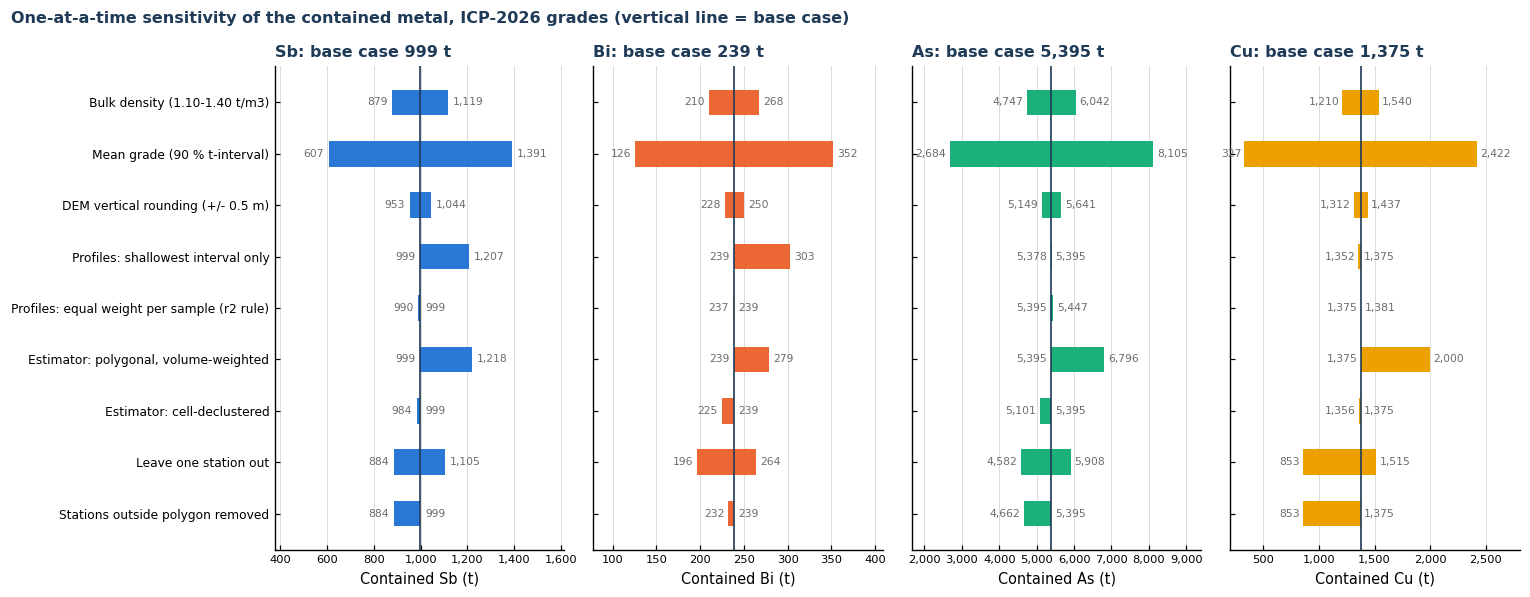

In [ ]:
SENS, rows = {}, []
for el in RES_ELS:
    S, R, e = STATIONS[el], RES[el], GRADE[el]
    M0, T0 = R["metal"], TONNES["base"]
    met = lambda g: T0 * g * 1e-6
    span = lambda m_: (min(m_, M0), max(m_, M0))
    items = [("Bulk density (1.10-1.40 t/m3)", M0 * BULK_DENSITY["low"] / RHO, M0 * BULK_DENSITY["high"] / RHO, ""),
             (f"Mean grade ({100 * CI_LEVEL:.0f} % t-interval)", met(R["g_lo"]), met(R["g_hi"]), ""),
             ("DEM vertical rounding (+/- 0.5 m)", M0 * (V_A - VOL_Q) / V_A, M0 * (V_A + VOL_Q) / V_A, ""),
             ("Profiles: shallowest interval only", *span(met(e["surface"])), f"{e['surface']:,.0f} ppm"),
             ("Profiles: equal weight per sample (r2 rule)", *span(met(e["equal"])), f"{e['equal']:,.0f} ppm"),
             ("Estimator: polygonal, volume-weighted", *span(met(e["polygonal"])), f"{e['polygonal']:,.0f} ppm"),
             ("Estimator: cell-declustered", *span(met(e["declustered"])), f"{e['declustered']:,.0f} ppm")]
    loo = np.array([np.delete(S["v"], i).mean() for i in range(len(S["v"]))])
    i_lo, i_hi = int(np.argmin(loo)), int(np.argmax(loo))
    items.append(("Leave one station out", met(loo[i_lo]), met(loo[i_hi]),
                  f"low without {S['names'][i_lo]}, high without {S['names'][i_hi]}"))
    if (~S["inside"]).any():
        items.append(("Stations outside polygon removed", *span(met(S["v"][S["inside"]].mean())), ""))
    if S["odl"].any():
        v3 = np.where(S["odl"], S["v"] * ODL_SENS_FACTOR / ODL_FACTOR, S["v"])
        items.append((f"Over-range assays at {ODL_SENS_FACTOR:g} x limit", *span(met(v3.mean())), ""))
    SENS[el] = items
    for name, lo, hi, note in items:
        rows.append({"Element": el, "Factor": name, "Metal low (t)": lo, "Metal high (t)": hi,
                     "Low vs base %": 100 * (lo / M0 - 1), "High vs base %": 100 * (hi / M0 - 1), "Note": note})
SENS_TABLE = pd.DataFrame(rows)
show_table(SENS_TABLE, precision=1)

# Figure 4 - one panel per element, one measure (contained metal), bars span low to high around the base case
_factors = list(dict.fromkeys(n for el in RES_ELS for n, *_ in SENS[el]))[::-1]
fig, axes = plt.subplots(1, len(RES_ELS), figsize=(3.5 * len(RES_ELS), 0.42 * len(_factors) + 1.7), sharey=True, squeeze=False)
for ax, el in zip(axes[0], RES_ELS):
    M0 = RES[el]["metal"]
    for name, lo, hi, note in SENS[el]:
        yk = _factors.index(name)
        ax.barh(yk, max(hi - lo, M0 * 0.004), left=lo, height=0.5, color=ELEMENT_COLOUR[el], zorder=3)
        ax.text(lo - 0.02 * M0, yk, f"{lo:,.0f}", ha="right", va="center", fontsize=7, color=C_MUTED)
        ax.text(hi + 0.02 * M0, yk, f"{hi:,.0f}", ha="left", va="center", fontsize=7, color=C_MUTED)
    ax.axvline(M0, color=C_INK, lw=1.1, zorder=4)
    ax.set_xlim(min(l for _, l, _, _ in SENS[el]) * 0.62, max(h for _, _, h, _ in SENS[el]) * 1.16)
    ax.set_yticks(range(len(_factors))); ax.set_yticklabels(_factors, fontsize=8)
    ax.set_ylim(-0.7, len(_factors) - 0.3)
    ax.grid(axis="x", color=C_GRID, lw=0.6, zorder=0)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(axis="x", labelsize=7.5)
    ax.set_xlabel(f"Contained {el} (t)")
    ax.set_title(f"{el}: base case {M0:,.0f} t", loc="left", fontweight="bold", color=C_INK)
fig.suptitle("One-at-a-time sensitivity of the contained metal, ICP-2026 grades (vertical line = base case)", x=0.01,
             ha="left", fontsize=10.5, fontweight="bold", color=C_INK)
plt.tight_layout()
savefig(fig, "Fig4_sensitivity_contained_metal_ICP2026")
plt.show()

## 12 · Grade maps

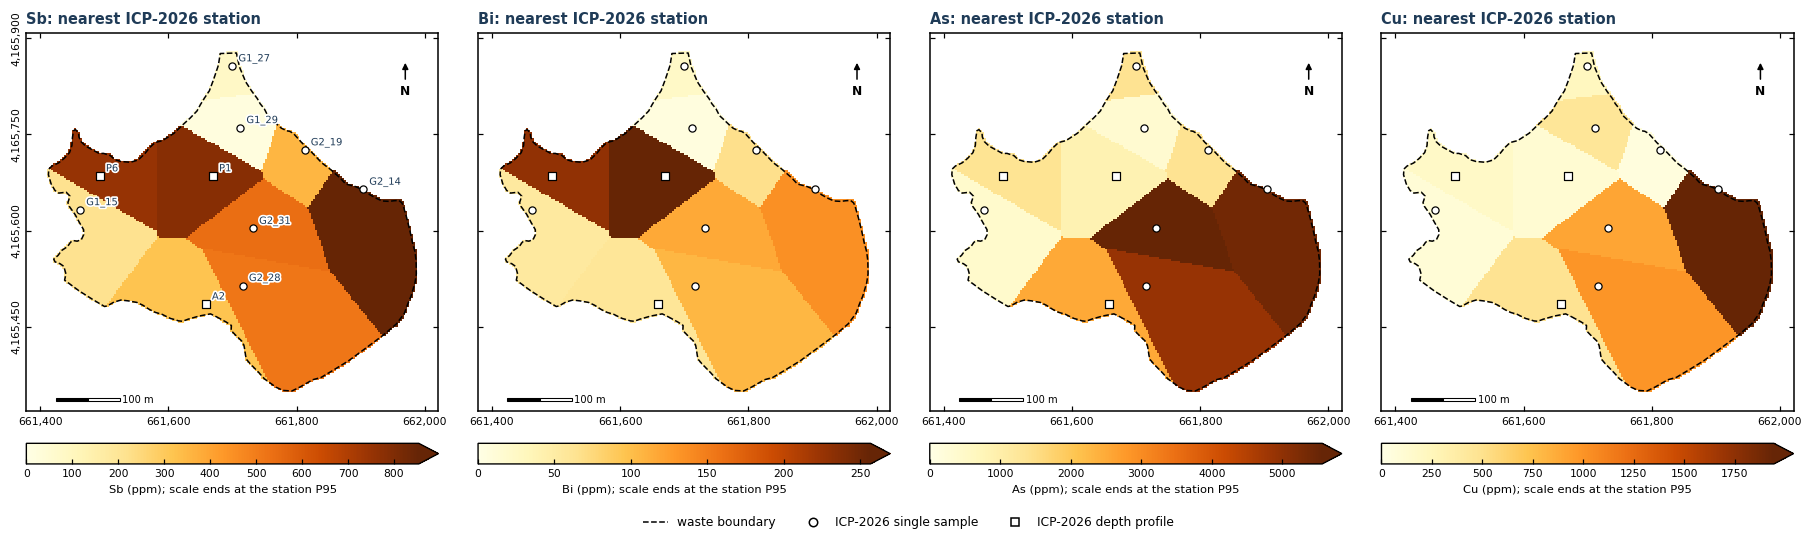

No grade-tonnage curve: no element has a predictive block model, so a curve would only describe the partition into ten nearest-station polygons. Every element is carried at its global mean grade.


In [ ]:
fig, axes = plt.subplots(1, len(RES_ELS), figsize=(4.15 * len(RES_ELS), 4.9), squeeze=False)
for j, el in enumerate(RES_ELS):
    S = STATIONS[el]
    vmax = float(np.percentile(S["v"], 95))
    ax = axes[0, j]
    im = ax.imshow(to_grid(BLK_POLY[el]), extent=EXTENT, origin="lower", cmap="YlOrBr", vmin=0, vmax=vmax,
                   interpolation="nearest", zorder=1)
    plot_stations(ax, labels=(j == 0))
    map_frame(ax, f"{el}: nearest ICP-2026 samples", ylabels=(j == 0))
    cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.045, pad=0.07, extend="max")
    cb.set_label(f"{el} (ppm)", fontsize=7.5); cb.ax.tick_params(labelsize=7)
fig.legend(handles=[Line2D([0], [0], color="black", lw=1.0, ls="--", label="waste boundary")] + STATION_HANDLES,
           loc="lower center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.04, 1, 1))
savefig(fig, "Fig5_nearest_station_maps_ICP2026")
plt.show()
print("No grade-tonnage curve: no element has a predictive block model, so a curve would only describe the "
      "partition into ten nearest-station polygons. Every element is carried at its global mean grade.")

## 13 · Validation against 2025 ICP assessment

In [ ]:
R2_OK_SELECTION = {"Sb": ("none", "Nugget"), "Bi": ("log", "Spherical"), "As": ("nscore", "Spherical"),
                   "Cu": ("nscore", "Spherical")}

def load_r2_stations(elements):
    """r2 dataset as in r2 Sections 3 and 7: located samples with an assay, censored values substituted with r2's
    factors, replicates within STATION_TOL_M collapsed by r2's station_means, r2 declustering."""
    val, flg, meta, info = read_lab_sheet(ICP25_XLSX, SHEET_DATA)
    aq = [c for c in meta.index if meta.loc[c, "method"] == "AQ251"]
    lf = [c for c in meta.index if meta.loc[c, "method"] == "LF725"]
    keys = val["Lab_ID"].map(canon_id)
    if keys.isna().any():
        raise ValueError(f"Unparseable laboratory IDs: {list(val.loc[keys.isna(), 'Lab_ID'])}")
    val["Sample"] = [f"{p}-{y:02d}-{n:02d}" for p, y, n in keys]
    val["_key"] = [f"{LAB_TO_FIELD_PREFIX.get(p, p)}-{y:02d}-{n:02d}" for p, y, n in keys]
    has_any = flg[aq].isin(["ok", "bdl", "odl"]).any(axis=1) | flg[lf].isin(["ok", "bdl", "odl"]).any(axis=1)
    ws = openpyxl.load_workbook(ICP25_XLSX, data_only=True, read_only=True)[SHEET_LOC]
    loc = pd.DataFrame([r[:3] for r in ws.iter_rows(min_row=2, values_only=True)],
                       columns=["No", "Field_ID_recorded", "Location"]).dropna(subset=["Field_ID_recorded"])
    loc["No"] = loc["No"].astype(int)
    loc[["Lat", "Lon"]] = loc["Location"].apply(lambda s: pd.Series(dms_pair(s)))
    loc["X_utm"], loc["Y_utm"] = lonlat_to_utm(loc["Lon"], loc["Lat"])
    loc["Field_ID"] = loc["Field_ID_recorded"].astype(str).str.strip()
    for fx in LOCATION_ID_FIXES:
        hit = (loc["No"] == fx["no"]) & (loc["Field_ID_recorded"].astype(str).str.upper().str.replace(" ", "")
                                         == fx["recorded"].upper())
        if hit.any() and (fx["kind"] != "inferred" or APPLY_INFERRED_FIXES):
            loc.loc[hit, "Field_ID"] = fx["corrected"]
    loc["_key"] = [f"{p}-{y:02d}-{n:02d}" for p, y, n in loc["Field_ID"].map(canon_id)]
    loc_ok = loc.loc[~loc["_key"].duplicated(keep=False)].set_index("_key")
    samp = val.loc[has_any, ["Sample", "_key"]].join(loc_ok[["X_utm", "Y_utm"]], on="_key")
    located = samp["X_utm"].notna().to_numpy()
    out = {}
    for el in elements:
        f = flg.loc[has_any, el].to_numpy()
        v = val.loc[has_any, el].to_numpy(float)
        z = np.where(f == "ok", v, np.where(f == "bdl", BDL_FACTOR * v, np.where(f == "odl", ODL_FACTOR * v, np.nan)))
        d = pd.DataFrame({"Sample": samp["Sample"].to_numpy(), "X_utm": samp["X_utm"].to_numpy(),
                          "Y_utm": samp["Y_utm"].to_numpy(), el: z, "flag": f})
        d = d[located & np.isfinite(z)].reset_index(drop=True)
        st, _ = station_means(d, "X_utm", "Y_utm", el, tol_m=STATION_TOL_M, id_col="Sample", flag_col="flag")
        coords = st[["X_utm", "Y_utm"]].to_numpy(float)
        vv = st[el].to_numpy(float) * TO_PPM[meta.loc[el, "unit"]]
        w, cell, _ = declustering_weights(coords, vv)
        out[el] = dict(coords=coords, v=vv, w=w, cell=cell, odl=st["flag"].str.contains("odl").to_numpy(),
                       samples=st["Sample"].to_numpy())
    return out, info

R2_ST, R2_SOURCE = {}, "R2_REFERENCE (documented statistics)"
if HAVE_R2_WORKBOOK:
    R2_ST, _info = load_r2_stations(RES_ELS)
    R2_SOURCE = f"{ICP25_XLSX} (job {_info.get('Job Number', '?')}), rebuilt with r2's rules"
    rows = []
    for el in RES_ELS:
        v25, ref = R2_ST[el]["v"], R2_REFERENCE.get(el)
        dec = float(np.sum(R2_ST[el]["w"] * v25) / R2_ST[el]["w"].sum())
        got = dict(n=len(v25), mean=float(v25.mean()), median=float(np.median(v25)), sd=float(np.std(v25, ddof=1)),
                   declustered=dec, n_odl=int(R2_ST[el]["odl"].sum()))
        same = ref is not None and all(np.isclose(got[k], ref[k], rtol=1e-4, atol=1e-3) for k in ref)
        rows.append({"Element": el, **{f"{k} (rebuilt)": got[k] for k in got},
                     "Matches the r2 output": "yes" if same else ("no reference" if ref is None else "NO")})
    R2_CHECK = pd.DataFrame(rows)
    show_table(R2_CHECK, precision=3)
else:
    R2_CHECK = pd.DataFrame()
print(f"r2 dataset: {R2_SOURCE}")

Element,n (rebuilt),mean (rebuilt),median (rebuilt),sd (rebuilt),declustered (rebuilt),n_odl (rebuilt),Matches the r2 output
Sb,36,532.430,336.775,511.507,485.075,2,yes
Bi,36,139.724,80.675,149.135,128.190,0,yes
As,36,1361.525,898.750,1250.401,1386.875,0,yes
Cu,36,511.453,239.950,877.228,413.487,0,yes


r2 dataset: ICP-DATA_2026.xlsx (job PLKRK2600014), rebuilt with r2's rules


### 13.1 · Same population?

Element,2025 stations,2025 mean,2025 median,2025 declustered,2025 90 % low,2025 90 % high,2025 > UDL,2026 stations,2026 mean (composites),2026 90 % low,2026 90 % high,2026 mean (shallowest interval),2026 composites vs 2025 (%),2026 shallowest vs 2025 (%),Welch p (composites),Welch p (shallowest),Mann-Whitney p (shallowest),2025 mean inside 2026 range,2026 mean inside 2025 range
Sb,36,532.43,336.78,485.08,388.39,676.47,2,10,448.88,272.58,625.18,542.58,-15.69,1.91,0.52,0.96,0.80,yes,yes
Bi,36,139.72,80.68,128.19,97.73,181.72,0,10,107.36,56.41,158.30,136.01,-23.16,-2.66,0.39,0.94,0.86,yes,yes
As,36,1361.52,898.75,1386.87,1009.42,1713.63,0,10,2424.44,1206.40,3642.48,2416.88,78.07,77.51,0.16,0.16,0.23,yes,no
Cu,36,511.45,239.95,413.49,264.43,758.48,0,10,617.73,147.17,1088.28,607.69,20.78,18.82,0.72,0.75,0.93,yes,yes


  Sb: 2 of the 2025 stations are held at the upper limit - the 2025 mean is a lower bound.
Welch's test compares means without assuming equal variances; Mann-Whitney compares the 2026 shallowest intervals with the 2025 samples as distributions (needs the r2 workbook).
  Sb  2026 vs 2025 mean: shallowest intervals  +1.9 %, depth composites -15.7 % -> the difference between the two (-17.3 %) is the effect of compositing the profiles over depth
  Bi  2026 vs 2025 mean: shallowest intervals  -2.7 %, depth composites -23.2 % -> the difference between the two (-21.1 %) is the effect of compositing the profiles over depth
  As  2026 vs 2025 mean: shallowest intervals +77.5 %, depth composites +78.1 % -> the difference between the two (+0.3 %) is the effect of compositing the profiles over depth
  Cu  2026 vs 2025 mean: shallowest intervals +18.8 %, depth composites +20.8 % -> the difference between the two (+1.7 %) is the effect of compositing the profiles over depth


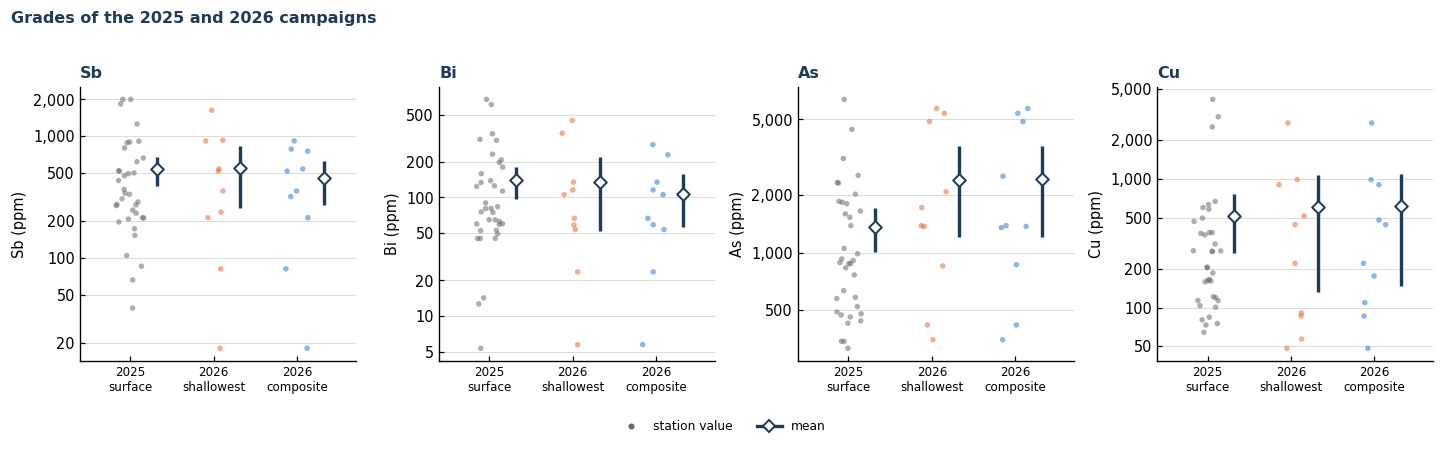

In [ ]:
def r2_summary(el):
    if R2_ST:
        v = R2_ST[el]["v"]
        return dict(n=len(v), mean=float(v.mean()), median=float(np.median(v)), sd=float(np.std(v, ddof=1)),
                    declustered=float(np.sum(R2_ST[el]["w"] * v) / R2_ST[el]["w"].sum()), n_odl=int(R2_ST[el]["odl"].sum()))
    return dict(R2_REFERENCE[el]) if el in R2_REFERENCE else None

T0 = TONNES["base"]
rows, CMP = [], {}
for el in RES_ELS:
    r25 = r2_summary(el)
    if r25 is None:
        continue
    q25 = float(stats.t.ppf(0.5 + CI_LEVEL / 2, r25["n"] - 1))
    se25 = r25["sd"] / math.sqrt(r25["n"])
    lo25, hi25 = max(r25["mean"] - q25 * se25, 0.0), r25["mean"] + q25 * se25
    v26, s26 = STATIONS[el]["v"], ALT[el]["surface"]
    m26, se26, q26, lo26, hi26 = mean_interval(v26)
    ms, ses, qs, los, his = mean_interval(s26)
    welch = stats.ttest_ind_from_stats(m26, float(np.std(v26, ddof=1)), len(v26), r25["mean"], r25["sd"], r25["n"],
                                       equal_var=False)
    welch_s = stats.ttest_ind_from_stats(ms, float(np.std(s26, ddof=1)), len(s26), r25["mean"], r25["sd"], r25["n"],
                                         equal_var=False)
    mw = stats.mannwhitneyu(s26, R2_ST[el]["v"], alternative="two-sided").pvalue if R2_ST else np.nan
    CMP[el] = dict(r25=r25, lo25=lo25, hi25=hi25, m26=m26, lo26=lo26, hi26=hi26, ms=ms, los=los, his=his)
    rows.append({"Element": el, "2025 stations": r25["n"], "2025 mean": r25["mean"], "2025 median": r25["median"],
                 "2025 declustered": r25["declustered"], f"2025 {100 * CI_LEVEL:.0f} % low": lo25,
                 f"2025 {100 * CI_LEVEL:.0f} % high": hi25, "2025 > UDL": r25["n_odl"],
                 "2026 stations": len(v26), "2026 mean (composites)": m26,
                 f"2026 {100 * CI_LEVEL:.0f} % low": lo26, f"2026 {100 * CI_LEVEL:.0f} % high": hi26,
                 "2026 mean (shallowest interval)": ms, "2026 composites vs 2025 (%)": 100 * (m26 / r25["mean"] - 1),
                 "2026 shallowest vs 2025 (%)": 100 * (ms / r25["mean"] - 1),
                 "Welch p (composites)": welch.pvalue, "Welch p (shallowest)": welch_s.pvalue,
                 "Mann-Whitney p (shallowest)": mw,
                 "2025 mean inside 2026 range": "yes" if lo26 <= r25["mean"] <= hi26 else "no",
                 "2026 mean inside 2025 range": "yes" if lo25 <= m26 <= hi25 else "no"})
COMPARE_TABLE = pd.DataFrame(rows)
show_table(COMPARE_TABLE, precision=2)
for el in RES_ELS:
    if el in CMP and CMP[el]["r25"]["n_odl"]:
        print(f"  {el}: {CMP[el]['r25']['n_odl']} of the 2025 stations are held at the upper limit - the 2025 mean is a lower bound.")
print("Welch's test compares means without assuming equal variances; Mann-Whitney compares the 2026 shallowest intervals "
      "with the 2025 samples as distributions (needs the r2 workbook).")
for el in RES_ELS:
    if el in CMP:
        c_ = CMP[el]
        print(f"  {el:3s} 2026 vs 2025 mean: shallowest intervals {100 * (c_['ms'] / c_['r25']['mean'] - 1):+5.1f} %, depth composites "
              f"{100 * (c_['m26'] / c_['r25']['mean'] - 1):+5.1f} % -> the difference between the two ({100 * (c_['m26'] / c_['ms'] - 1):+.1f} %) "
              f"is the effect of compositing the profiles over depth")

# Figure 6 - stations of both campaigns (dots) with the mean and its 90 % range (bar), one panel per element, log axis
_series = [("2025\nsurface", None, C_MUTED), ("2026\nshallowest", "surface", C_SERIES[1]),
           ("2026\ncomposite", "depth", C_SERIES[0])]
fig, axes = plt.subplots(1, len(RES_ELS), figsize=(3.3 * len(RES_ELS), 3.9), squeeze=False)
_rng = np.random.default_rng(3)
for ax, el in zip(axes[0], RES_ELS):
    if el not in CMP:
        ax.set_visible(False); continue
    for k, (lab, key, col) in enumerate(_series):
        if key is None:
            pts = R2_ST[el]["v"] if R2_ST else np.array([])
            m, lo, hi = CMP[el]["r25"]["mean"], CMP[el]["lo25"], CMP[el]["hi25"]
        else:
            pts = ALT[el][key]
            m, _, _, lo, hi = mean_interval(pts)
        if len(pts):
            ax.scatter(k + _rng.uniform(-0.17, 0.17, len(pts)), pts, s=13, color=col, alpha=0.55, edgecolors="none", zorder=3)
        ax.vlines(k + 0.32, max(lo, 1e-9), hi, color=C_INK, lw=2.2, zorder=4)
        ax.scatter([k + 0.32], [m], s=34, marker="D", color="white", edgecolors=C_INK, linewidths=1.3, zorder=5)
    ax.set_yscale("log")
    plain_log_axis(ax, "y")
    ax.set_xticks(range(len(_series))); ax.set_xticklabels([s[0] for s in _series], fontsize=7.8)
    ax.set_xlim(-0.6, len(_series) - 0.3)
    ax.grid(axis="y", color=C_GRID, lw=0.6, which="major")
    ax.set_ylabel(f"{el} (ppm)")
    ax.set_title(el, loc="left", fontweight="bold", color=C_INK)
fig.legend(handles=[Line2D([0], [0], marker="o", color="w", mfc=C_MUTED, ms=5, label="station value"),
                    Line2D([0], [0], marker="D", color=C_INK, mfc="white", mew=1.3, lw=2.2,
                           label=f"mean")],
           loc="lower center", ncol=2, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Grades of the 2025 and 2026 campaigns" + ("" if R2_ST else " (2025: documented mean and range only)"),
             x=0.01, ha="left", fontsize=10.5, fontweight="bold", color=C_INK)
plt.tight_layout(rect=(0, 0.05, 1, 0.96))
savefig(fig, "Fig6_campaign_comparison_2025_2026")
plt.show()

### 13.2 · Do the 2025 kriged surfaces predict the 2026 grades?

r2's Stage 2 (variogram, model and transform selection) is rerun on the 2025 stations, and the selected model
kriges the ten 2026 positions. The predictions are compared with the 2026 shallowest intervals (the like-for-like
support) and with the depth composites. Skill is judged against the plainest rival, the 2025 mean used everywhere:
a positive "skill vs 2025 mean" means the 2025 surface predicts the 2026 grades better than its own average does.

Element,r2 selection (2025 stations),Same as r2 OK output,2026 observed,n,Mean observed,Mean predicted,ME (pred - obs),RMSE,RMSE of the 2025 mean,Skill vs 2025 mean,Spearman
Sb,none Nugget,yes,shallowest interval,10,542.582,550.781,8.199,472.862,467.663,-0.022,-0.164
Sb,none Nugget,yes,depth composite,10,448.880,550.781,101.901,392.385,300.374,-0.706,-0.382
Bi,log Spherical,yes,shallowest interval,10,136.008,134.446,-1.562,130.042,138.041,0.113,0.055
Bi,log Spherical,yes,depth composite,10,107.359,134.446,27.086,103.370,89.435,-0.336,-0.006
As,nscore Spherical,yes,shallowest interval,10,2416.880,1893.381,-523.499,2364.993,2244.180,-0.111,-0.261
As,nscore Spherical,yes,depth composite,10,2424.442,1893.381,-531.061,2341.072,2259.074,-0.074,-0.042
Cu,nscore Spherical,yes,shallowest interval,10,607.690,415.557,-192.133,752.524,784.300,0.079,0.697
Cu,nscore Spherical,yes,depth composite,10,617.726,415.557,-202.169,752.065,777.385,0.064,0.636



Station by station (ppm):


Station,Kind,Nearest 2025 station (m),Sb 2026 shallowest,Sb 2026 composite,Sb 2025 OK,Sb nearest 2025 station,Bi 2026 shallowest,Bi 2026 composite,Bi 2025 OK,Bi nearest 2025 station,As 2026 shallowest,As 2026 composite,As 2025 OK,As nearest 2025 station,Cu 2026 shallowest,Cu 2026 composite,Cu 2025 OK,Cu nearest 2025 station
G1_15,single sample,25.6,214.0,214.0,818.3,895.7,53.6,53.6,244.1,303.7,417.3,417.3,1071.5,460.0,86.0,86.0,180.0,121.3
G1_27,single sample,84.0,81.6,81.6,659.3,432.2,23.6,23.6,170.5,80.8,1372.8,1372.8,2839.5,6377.0,220.9,220.9,244.5,158.7
G1_29,single sample,49.9,18.2,18.2,627.3,798.7,5.7,5.7,124.8,159.0,349.2,349.2,3047.8,1806.2,441.3,441.3,291.7,84.2
G2_14,single sample,48.0,912.9,912.9,316.6,519.8,134.7,134.7,126.1,138.7,5389.5,5389.5,1143.2,887.1,2725.5,2725.5,405.3,160.9
G2_19,single sample,63.0,354.7,354.7,539.2,213.5,66.8,66.8,90.9,52.5,1386.3,1386.3,2277.1,2336.2,48.2,48.2,336.0,186.0
G2_28,single sample,60.4,515.8,515.8,318.9,269.1,105.7,105.7,74.0,45.1,4879.2,4879.2,1807.0,1386.9,988.7,988.7,915.7,669.3
G2_31,single sample,59.1,538.2,538.2,440.5,38.9,115.8,115.8,78.0,5.3,5712.6,5712.6,1739.8,488.6,902.5,902.5,636.7,2538.3
P1,profile,51.6,924.1,782.2,624.2,472.3,348.3,279.3,104.6,80.6,852.2,865.0,1718.7,4435.3,90.8,109.1,335.9,599.3
P6,profile,25.3,1628.4,752.5,834.7,616.3,447.2,229.4,261.6,207.6,2086.6,1353.4,1071.8,477.8,57.0,175.9,157.2,64.2
A2,profile,6.8,237.9,318.8,329.0,273.2,58.6,58.9,69.8,59.9,1723.1,2519.1,2217.3,3120.6,516.0,479.1,652.6,276.5


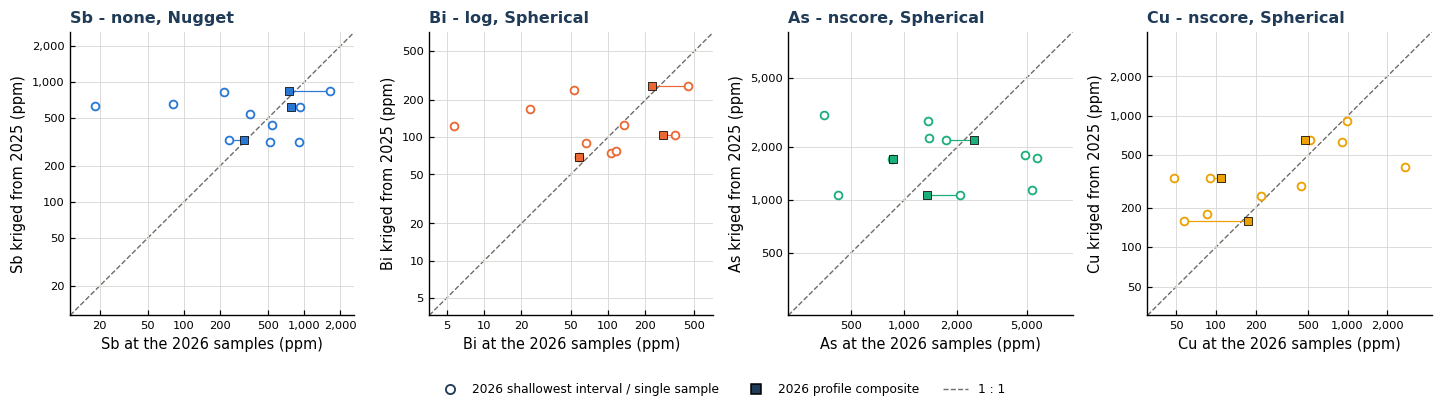

In [ ]:
PRED, rows, VAL_STATION = {}, [], pd.DataFrame()
if R2_ST:
    _vs = pd.DataFrame({"Station": STATIONS[RES_ELS[0]]["names"], "Kind": STATIONS[RES_ELS[0]]["kind"]})
    for el in RES_ELS:
        c25, v25, w25 = R2_ST[el]["coords"], R2_ST[el]["v"], R2_ST[el]["w"]
        _cands, f = fit_element(c25, v25, w25, label=el)
        tgt = STATIONS[el]["coords"]
        r = ok_batch(tgt, c25, f["y"], f["model"], radius=f["radius"])
        p = r["est"] if f["transform"] == "none" else f["tf"].back(r["est"], var=r["var"], mu=r["mu"])
        p = np.clip(p, 0.0, None)
        d_nn, i_nn = cKDTree(c25).query(tgt, k=1)
        sel = (f["transform"], f["model"].name)
        PRED[el] = dict(pred=p, nn_d=d_nn, nn_v=v25[i_nn], selection=sel,
                        same_as_r2=(R2_OK_SELECTION.get(el) == sel) if el in R2_OK_SELECTION else None)
        m25 = float(v25.mean())
        for basis, obs in (("shallowest interval", ALT[el]["surface"]), ("depth composite", STATIONS[el]["v"])):
            mk = metrics(obs, p)
            mse0 = float(np.mean((obs - m25) ** 2))
            rows.append({"Element": el, "r2 selection (2025 stations)": f"{sel[0]} {sel[1]}",
                         "Same as r2 OK output": {True: "yes", False: "NO", None: "-"}[PRED[el]["same_as_r2"]],
                         "2026 observed": basis, "n": mk["n"], "Mean observed": float(obs.mean()),
                         "Mean predicted": float(p.mean()), "ME (pred - obs)": mk["ME_bias"], "RMSE": mk["RMSE"],
                         "RMSE of the 2025 mean": math.sqrt(mse0), "Skill vs 2025 mean": 1 - mk["RMSE"] ** 2 / mse0,
                         "Spearman": mk["Spearman_r"]})
        _vs[f"{el} 2026 shallowest"] = ALT[el]["surface"]
        _vs[f"{el} 2026 composite"] = STATIONS[el]["v"]
        _vs[f"{el} 2025 OK"] = p
        _vs[f"{el} nearest 2025 station"] = v25[i_nn]
    _vs.insert(2, "Nearest 2025 station (m)", PRED[RES_ELS[0]]["nn_d"])
    VAL_STATION = _vs
    PRED_TABLE = pd.DataFrame(rows)
    show_table(PRED_TABLE, precision=3)
    print("\nStation by station (ppm):")
    show_table(VAL_STATION, precision=1)

    # Figure 7 - 2025 OK prediction against the 2026 grade at the same position
    fig, axes = plt.subplots(1, len(RES_ELS), figsize=(3.3 * len(RES_ELS), 3.6), squeeze=False)
    for ax, el in zip(axes[0], RES_ELS):
        p, prof = PRED[el]["pred"], STATIONS[el]["kind"] == "profile"
        o_s, o_c = ALT[el]["surface"], STATIONS[el]["v"]
        allv = np.r_[p, o_s, o_c]
        lim = (allv.min() / 1.6, allv.max() * 1.6)
        ax.plot(lim, lim, color=C_MUTED, lw=0.9, ls="--", zorder=1)
        ax.scatter(o_s, p, s=26, marker="o", facecolors="white", edgecolors=ELEMENT_COLOUR[el], linewidths=1.2, zorder=3)
        ax.scatter(o_c[prof], p[prof], s=26, marker="s", color=ELEMENT_COLOUR[el], edgecolors="black", linewidths=0.5, zorder=4)
        for xo, xc, yp in zip(o_s[prof], o_c[prof], p[prof]):
            ax.plot([xo, xc], [yp, yp], color=ELEMENT_COLOUR[el], lw=0.8, zorder=2)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
        plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
        ax.tick_params(labelsize=7.5)
        ax.set_xlabel(f"{el} at the 2026 samples (ppm)"); ax.set_ylabel(f"{el} kriged from 2025 (ppm)")
        ax.grid(color=C_GRID, lw=0.6)
        ax.set_title(f"{el} - {PRED[el]['selection'][0]}, {PRED[el]['selection'][1]}", loc="left", fontweight="bold", color=C_INK)
    fig.legend(handles=[Line2D([0], [0], marker="o", color="w", mfc="white", mec=C_INK, mew=1.2, ms=6,
                               label="2026 shallowest interval / single sample"),
                        Line2D([0], [0], marker="s", color="w", mfc=C_INK, mec="black", ms=6, label="2026 profile composite"),
                        Line2D([0], [0], color=C_MUTED, lw=0.9, ls="--", label="1 : 1")],
               loc="lower center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.04))
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    savefig(fig, "Fig7_r2_kriging_against_ICP2026")
    plt.show()
else:
    PRED_TABLE = pd.DataFrame()
    print("r2 workbook not present - the 2025 kriging cannot be refitted; 13.2 skipped.")

### 13.3 · What the comparison means for the contained metal

Both campaigns are put on the same footing: the same base-case tonnage, the station mean as the grade, and the
Student-t range. This isolates the effect of the samples. The r2 resource figures for elements with a kriged block
model are not reproduced here.

In [ ]:
rows = []
for el in RES_ELS:
    if el not in CMP:
        continue
    c_ = CMP[el]
    rows.append({"Element": el,
                 "2025 surface samples: metal (t)": T0 * c_["r25"]["mean"] * 1e-6,
                 "2025 range (t)": f"{T0 * c_['lo25'] * 1e-6:,.0f} - {T0 * c_['hi25'] * 1e-6:,.0f}",
                 "2026 shallowest interval: metal (t)": T0 * c_["ms"] * 1e-6,
                 "2026 depth composites: metal (t)": RES[el]["metal"],
                 "2026 range (t)": f"{T0 * c_['lo26'] * 1e-6:,.0f} - {T0 * c_['hi26'] * 1e-6:,.0f}",
                 "2026 / 2025": RES[el]["metal"] / (T0 * c_["r25"]["mean"] * 1e-6),
                 "Ranges overlap": "yes" if (c_["lo26"] <= c_["hi25"] and c_["lo25"] <= c_["hi26"]) else "no"})
METAL_COMPARE = pd.DataFrame(rows)
print(f"Contained metal at the base-case tonnage ({T0 / 1e6:.2f} Mt), grade = station mean, {100 * CI_LEVEL:.0f} % t-range:")
show_table(METAL_COMPARE, precision=2)

Contained metal at the base-case tonnage (2.23 Mt), grade = station mean, 90 % t-range:


Element,2025 surface samples: metal (t),2025 range (t),2026 shallowest interval: metal (t),2026 depth composites: metal (t),2026 range (t),2026 / 2025,Ranges overlap
Sb,1184.76,"864 - 1,505",1207.35,998.84,"607 - 1,391",0.84,yes
Bi,310.91,217 - 404,302.64,238.89,126 - 352,0.77,yes
As,3029.65,"2,246 - 3,813",5378.02,5394.85,"2,684 - 8,105",1.78,yes
Cu,1138.08,"588 - 1,688",1352.23,1374.56,"327 - 2,422",1.21,yes


## 14 · Audit

In [ ]:
def _f(x, nd=0):
    return f"{x:,.{nd}f}"

AUDIT = []
def check(name, ok, detail=""):
    AUDIT.append({"Check": name, "Status": "PASS" if bool(ok) else "FAIL", "Detail": detail})

# input file
check("One row per sample, unique sample IDs", SAMP["Sample"].is_unique, f"{len(SAMP)} samples, {len(META)} analytes")
_empty = sum(int((_TXT[c].astype(str).str.strip() == "").sum()) for c in ANALYTE_COLS)
_cens = int(FLAG.isin(["bdl", "odl"]).to_numpy().sum())
_lt_gt = sum(int(_TXT[c].astype(str).str.strip().str[:1].isin(["<", ">"]).sum()) for c in ANALYTE_COLS)
check("Every empty (or '<', '>') cell is censored, and nothing else", _empty + _lt_gt == _cens,
      f"{_empty} empty + {_lt_gt} signed cells, {_cens} censored flags")
check("Reported values lie between the configured MDL and upper limit", not LIMIT_VIOLATIONS,
      "; ".join(LIMIT_VIOLATIONS) or f"{len(META)} analytes")
_fac = {"ppm": 1.0, "ppb": 1e-3, "pct": 1e4}
_bad = []
for k in META.index:
    col = META.loc[k, "col"]
    raw = pd.to_numeric(_TXT[col].astype(str).str.strip().replace("", np.nan), errors="coerce").to_numpy(float)
    ok_ = FLAG[k].to_numpy() == "ok"
    z, _ = sample_ppm(k)
    if not np.allclose(z[ok_], raw[ok_] * _fac[col.rsplit("_", 1)[1]], rtol=1e-12, equal_nan=True):
        _bad.append(k)
check("Unit conversion to ppm from the column headers", not _bad, ", ".join(_bad) or "ppb x 1e-3, % x 1e4, ppm x 1")

# stations and composites
for _, r in STATION_LIST[STATION_LIST["Kind"] == "profile"].iterrows():
    g = SAMP[SAMP["Station_no"] == r["Station_no"]]
    check(f"Depth weights of {r['Station']} add up to its deepest base", np.isclose(g["Depth_w_cm"].sum(), g["Base_cm"].max()),
          f"{g['Depth_w_cm'].sum():g} cm = {g['Base_cm'].max():g} cm")
_bad, _n_chk, _n_skip = [], 0, 0
for el in RES_ELS:
    raw = pd.to_numeric(_TXT[META.loc[el, "col"]], errors="coerce").to_numpy(float) * _fac[META.loc[el, "col"].rsplit("_", 1)[1]]
    sv = station_values(el)[0]
    for i, s in enumerate(STATION_LIST["Station_no"]):
        m = (SAMP["Station_no"] == s).to_numpy()
        if np.isnan(raw[m]).any():                 # a censored sample: its substitution is checked with the flags above
            _n_skip += 1
            continue
        if STATION_LIST["Kind"].iloc[i] == "profile" and STATION_VALUE == "depth":
            ref = np.average(raw[m], weights=SAMP.loc[m, "Depth_w_cm"].to_numpy())
        elif STATION_LIST["Kind"].iloc[i] == "profile" and STATION_VALUE == "surface":
            ref = raw[m][np.argmin(SAMP.loc[m, "Top_cm"].to_numpy())]
        else:
            ref = np.mean(raw[m])
        _n_chk += 1
        if not np.isclose(ref, sv[i], rtol=1e-12):
            _bad.append(f"{el}@{STATION_LIST['Station'].iloc[i]}")
check(f"Station values ('{STATION_VALUE}') recomputed from the raw file", not _bad,
      ", ".join(_bad) or f"{_n_chk} station values identical" + (f" ({_n_skip} with censored samples not re-derived)" if _n_skip else ""))

# geometry and tonnage
check("Block volumes add up to the DEM volume", np.isclose(BLK_VOL["A"].sum(), SCENARIOS["A"]["volume"], rtol=1e-12),
      f"{BLK_VOL['A'].sum():,.1f} m3 = {SCENARIOS['A']['volume']:,.1f} m3")
check("DEM volume = sum of (surface - base) x cell area", np.isclose(SCENARIOS["A"]["volume"],
      float(np.sum(np.clip(zv - Z_BASE, 0, None)) * DX * DY), rtol=1e-12), f"{SCENARIOS['A']['volume'] / 1e6:.4f} Mm3")
check("Base tonnage = bulk density x volume", np.isclose(TONNES["base"], BULK_DENSITY["base"] * V_A, rtol=1e-12),
      f"{BULK_DENSITY['base']:g} x {V_A:,.0f} = {TONNES['base']:,.0f} t")
check("Volume and tonnage are single base-case values (no low / high)",
      set(TONNES) == {"base"} and all(set(RES[el]) == {"grade", "g_lo", "g_hi", "metal"} for el in RES_ELS)
      and "Tonnage (Mt)" in RESOURCE_BASE and not any(("low" in c.lower()) or ("high" in c.lower()) for c in RESOURCE_BASE),
      f"{TONNES['base'] / 1e6:.2f} Mt at {BULK_DENSITY['base']:g} t/m3")

# grade and contained metal
for el in RES_ELS:
    v, e = STATIONS[el]["v"], GRADE[el]
    n = len(v)
    lo_, hi_ = stats.t.interval(CI_LEVEL, n - 1, loc=float(np.mean(v)), scale=float(stats.sem(v)))
    check(f"{el}: global OK (pure nugget) = arithmetic mean, SE = s/sqrt(n)",
          np.isclose(e["global_ok"], np.mean(v), rtol=1e-10) and np.isclose(e["global_se"], stats.sem(v), rtol=1e-10),
          f"{e['global_ok']:,.3f} = {np.mean(v):,.3f} ppm; {e['global_se']:,.3f} = {stats.sem(v):,.3f}")
    check(f"{el}: {100 * CI_LEVEL:.0f} % range = scipy.stats.t.interval (floored at 0)",
          np.isclose(e["lo"], max(lo_, 0.0)) and np.isclose(e["hi"], hi_), f"{e['lo']:,.2f} - {e['hi']:,.2f} ppm")
    R = RES[el]
    check(f"{el}: contained metal = bulk density x volume x grade x 1e-6 (base case)",
          np.isclose(R["metal"], BULK_DENSITY["base"] * float(BLK_VOL["A"].sum()) * e["adopted"] * 1e-6, rtol=1e-12),
          f"{BULK_DENSITY['base']:g} t/m3 x {BLK_VOL['A'].sum():,.0f} m3 x {e['adopted']:,.2f} ppm = {R['metal']:,.1f} t")

# screening on stations instead of samples
_st_short = []
for el in SCREEN_CRM["Element"]:
    zs = station_values(el, "depth")[0]
    fs = station_values(el, "depth")[1]
    zs, fs = zs[np.isfinite(zs)], fs[np.isfinite(zs)]
    q_ok = 100 * np.mean([x == "ok" for x in fs]) >= SHORTLIST_MIN_QUANT_PCT
    if q_ok and np.median(zs) / UCC_PPM[el] >= SHORTLIST_MIN_CF:
        _st_short.append(el)
check("Shortlist unchanged when screened on station composites instead of samples",
      sorted(_st_short) == sorted(SHORTLIST), f"stations: {', '.join(_st_short)}; samples: {', '.join(SHORTLIST)}")

# r2 reproduction
if R2_ST:
    check("r2 station statistics reproduced from the r2 workbook",
          (R2_CHECK["Matches the r2 output"] != "NO").all(), ", ".join(f"{r['Element']}: {r['Matches the r2 output']}"
                                                                for _, r in R2_CHECK.iterrows()))
    _sel = {el: PRED[el]["same_as_r2"] for el in PRED}
    check("r2 kriging selection reproduced on the 2025 stations", all(v is not False for v in _sel.values()),
          ", ".join(f"{el}: {' '.join(PRED[el]['selection'])}" for el in PRED))
AUDIT_TABLE = pd.DataFrame(AUDIT)
show_table(AUDIT_TABLE, status_col="Status")
print(f"{int((AUDIT_TABLE['Status'] == 'PASS').sum())} of {len(AUDIT_TABLE)} checks passed.")

Check,Status,Detail
"One row per sample, unique sample IDs",PASS,"18 samples, 53 analytes"
"Every empty (or '<', '>') cell is censored, and nothing else",PASS,"239 empty + 0 signed cells, 239 censored flags"
Reported values lie between the configured MDL and upper limit,PASS,53 analytes
Unit conversion to ppm from the column headers,PASS,"ppb x 1e-3, % x 1e4, ppm x 1"
Depth weights of P1 add up to its deepest base,PASS,50 cm = 50 cm
Depth weights of P6 add up to its deepest base,PASS,300 cm = 300 cm
Depth weights of A2 add up to its deepest base,PASS,41 cm = 41 cm
Station values ('depth') recomputed from the raw file,PASS,40 station values identical
Block volumes add up to the DEM volume,PASS,"1,780,153.5 m3 = 1,780,153.5 m3"
DEM volume = sum of (surface - base) x cell area,PASS,1.7802 Mm3


27 of 27 checks passed.


## 15 · Export and draft text

In [ ]:
SHEETS = {"Censoring": CENSOR_TABLE, "Stations": STATION_LIST, "Station values": STATION_VALUES,
          "CRM table": CRM_TABLE, "Screening": SCREEN_CRM, "Context": CONTEXT_TABLE, "Volume": VOLUME_TABLE,
          "Station summary": STATION_TABLE, "Vertical": VERTICAL_TABLE, "Variogram check": VARIO_TABLE,
          "Polygonal shares": POLY_TABLE, "Grade": GRADE_TABLE, "Resource": RESOURCE_BASE,
          "Sensitivity": SENS_TABLE, "Compare 2025": COMPARE_TABLE, "Metal 2025 vs 2026": METAL_COMPARE,
          "r2 kriging at 2026": PRED_TABLE, "Station validation": VAL_STATION, "Audit": AUDIT_TABLE}
if len(MDL_CHECK):
    SHEETS["MDL check"] = MDL_CHECK
XLSX_OUT = os.path.join(OUT_DIR, "Lagunazo_ICP2026_resource_tables.xlsx")
if OPENPYXL_OK:
    with pd.ExcelWriter(XLSX_OUT, engine="openpyxl") as xw:
        for name, df in SHEETS.items():
            if isinstance(df, pd.DataFrame) and len(df):
                df.to_excel(xw, sheet_name=name[:31], index=False)
    print(f"Tables written to {XLSX_OUT} ({sum(1 for d in SHEETS.values() if len(d))} sheets)")

def _sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest() if Path(p).exists() else None

def _ver(mod):
    try:
        return __import__(mod).__version__
    except Exception:
        return None

MANIFEST = dict(
    notebook="Lagunazo_CRM_Resource_Assessment_ICP2026_validation_r2", started=RUN_STARTED,
    finished=datetime.now(timezone.utc).isoformat(timespec="seconds"),
    inputs={p: _sha(p) for p in (ICP26_CSV, KMZ_FILE, DEM_FILE, ICP25_XLSX)},
    python=platform.python_version(), packages={m: _ver(m) for m in ("numpy", "pandas", "scipy", "matplotlib", "pyproj", "shapely")},
    settings=dict(base_m=BASE_ELEVATION_M, density_t_m3=BULK_DENSITY["base"], station_value=STATION_VALUE, ci=CI_LEVEL, ci_method=CI_METHOD,
                  bdl_factor=BDL_FACTOR, odl_factor=ODL_FACTOR),
    volume_m3=V_A, tonnes=TONNES["base"],
    results={el: dict(grade_ppm=RES[el]["grade"], metal_t=RES[el]["metal"]) for el in RES_ELS},
    audit=f"{int((AUDIT_TABLE['Status'] == 'PASS').sum())}/{len(AUDIT_TABLE)} PASS")
with open(os.path.join(OUT_DIR, "run_manifest.json"), "w") as fh:
    json.dump(MANIFEST, fh, indent=2, default=float)
print(f"Run manifest written to {os.path.join(OUT_DIR, 'run_manifest.json')}")

Tables written to results_ICP2026_validation_base193\Lagunazo_ICP2026_resource_tables.xlsx (20 sheets)
Run manifest written to results_ICP2026_validation_base193\run_manifest.json


In [ ]:
_WORDS = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight", 9: "nine", 10: "ten",
          11: "eleven", 12: "twelve", 13: "thirteen", 14: "fourteen", 15: "fifteen", 16: "sixteen", 17: "seventeen",
          18: "eighteen", 19: "nineteen", 20: "twenty"}

def _w(n, cap=False):
    s = _WORDS.get(int(n), f"{int(n)}")
    return s[0].upper() + s[1:] if cap else s

def _and(items):
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]

_prof_rows = STATION_LIST[STATION_LIST["Kind"] == "profile"]
_n_prof = len(_prof_rows)
_prof_txt = _and([f"{r['Station']} to {r['Deepest sample (m)']:.2f} m" for _, r in _prof_rows.iterrows()])
_cf = SCREEN_CRM.set_index("Element")["CF median"]
_res_txt = _and([f"{fmt_sig(RES[el]['metal'])} t {el} at {fmt_sig(RES[el]['grade'])} ppm"
                 + (" (a penalty element)" if el in DELETERIOUS else "") for el in RES_ELS])
_cmp = [f"{_f(CMP[el]['m26'])} against {_f(CMP[el]['r25']['mean'])} ppm {el}"
        + (" (the 2025 value is a lower bound)" if CMP[el]["r25"]["n_odl"] else "") for el in RES_ELS if el in CMP]
_cmp_s = [f"{_f(CMP[el]['ms'])} ppm {el} ({100 * (CMP[el]['ms'] / CMP[el]['r25']['mean'] - 1):+.0f} %)".replace("-", "\u2212")
          for el in RES_ELS if el in CMP]
_inside = [el for el in RES_ELS if el in CMP and CMP[el]["lo26"] <= CMP[el]["r25"]["mean"] <= CMP[el]["hi26"]]
_outside = [el for el in RES_ELS if el in CMP and el not in _inside]
_vt = VERTICAL_TABLE.set_index(["Element", "Profile"])
_deep_prof = STATION_LIST.loc[STATION_LIST["Deepest sample (m)"].idxmax(), "Station"]
_deep_m = float(STATION_LIST["Deepest sample (m)"].max())
_n_deep = int((STATION_LIST["Deepest sample (m)"] > 0.5).sum())
_ratios = {el: float(_vt.loc[(el, _deep_prof), "Shallowest / deepest"]) for el in RES_ELS if (el, _deep_prof) in _vt.index}
_up = [f"{el} ×{r:.1f}" for el, r in _ratios.items() if r >= 1]
_down = [f"{el} ×{r:.2f}" for el, r in _ratios.items() if r < 1]
_contrast = any(abs(math.log(r)) > math.log(1.5) for r in _ratios.values())
_skill = []
for _, r in VARIO_TABLE.iterrows():
    g = 100 * (1 - min(r["RMSE LOO nearest (ppm)"], r["RMSE LOO IDW (ppm)"]) / r["RMSE LOO mean (ppm)"])
    if g >= LOO_MIN_GAIN_PCT:
        _skill.append(f"{r['Element']} ({g:.0f} % lower error)")
_skill_txt = ("neither the nearest station nor inverse-distance weighting predicts a withheld station better than "
              "the mean of the others" if not _skill else
              "a simple spatial predictor beats the mean of the other stations in leave-one-out tests only for "
              + _and(_skill))

DRAFT = (
    f"The 2026 campaign provides {_w(len(SAMP))} samples from {_w(N_STATIONS)} positions in the Lagunazo waste: "
    f"{_w(N_STATIONS - _n_prof)} single samples and {_w(_n_prof)} depth profiles ({_prof_txt}). They were analysed with "
    f"the same aqua-regia ICP package (AQ251) as the 2025 samples. No QC records accompany the 2026 export, so the "
    f"precision of this batch is not assessed here. Screened against the upper continental crust with the rules "
    f"applied to the 2025 data, the 2026 samples select the same elements, {_and(SHORTLIST)}, with median "
    f"concentration factors of {_and([f'{_cf[e]:,.0f}' for e in SHORTLIST])} respectively"
    + (", arsenic being inventoried as a penalty element rather than a product" if "As" in SHORTLIST else "") + ". "
    f"{_w(N_STATIONS, cap=True)} stations are too few for an experimental variogram under those rules, and {_skill_txt}. "
    f"The 2026 grades therefore enter the tonnage as global means. In the base case, the waste above {Z_BASE:g} m a.s.l. "
    f"occupies {V_A / 1e6:.2f} Mm³, which at {RHO:g} t/m³ is {TONNES['base'] / 1e6:.2f} Mt; at the global-mean grades it "
    f"contains about {_res_txt}. The station means of the two campaigns are {_and(_cmp)}. Compared like for like with the 2025 "
    f"surface samples, the shallowest 2026 intervals give {_and(_cmp_s)}. "
    + (f"The 2025 mean lies inside the {100 * CI_LEVEL:.0f} % Student-t range of the 2026 mean for {_and(_inside)}" if _inside else
       f"The 2025 mean lies outside the {100 * CI_LEVEL:.0f} % Student-t range of the 2026 mean for every element")
    + (f" but not for {_and(_outside)}" if _inside and _outside else "") + ". "
    f"The profiles test the assumption that grade is homogeneous through the thickness. In {_deep_prof}"
    + (", the only profile deeper than 0.5 m," if _n_deep == 1 else ",")
    + " the shallowest interval holds "
    + _and([t for t in (f"more {_and([s.split()[0] for s in _up])} than the deepest one ({', '.join(_up)})" if _up else "",
                        f"less {_and([s.split()[0] for s in _down])} ({', '.join(_down)})" if _down else "") if t])
    + ". "
    + (f"The assumption is therefore not supported in the upper {_deep_m:g} m at that position" if _contrast else
       f"Within the upper {_deep_m:g} m at that position the grades are consistent with the assumption")
    + f", and it remains untested below {_deep_m:g} m and at the single-sample stations. [CONFIRM: interpretation of "
      f"the vertical contrast, for example near-surface oxidation and leaching, and whether {_deep_prof} is representative.]")
print(DRAFT)
with open(os.path.join(OUT_DIR, "draft_text_ICP2026_validation.txt"), "w", encoding="utf-8") as fh:
    fh.write(DRAFT + "\n")

The 2026 campaign provides eighteen samples from ten positions in the Lagunazo waste: seven single samples and three depth profiles (P1 to 0.50 m, P6 to 3.00 m and A2 to 0.41 m). They were analysed with the same aqua-regia ICP package (AQ251) as the 2025 samples. No QC records accompany the 2026 export, so the precision of this batch is not assessed here. Screened against the upper continental crust with the rules applied to the 2025 data, the 2026 samples select the same elements, Sb, Bi, As and Cu, with median concentration factors of 1,092, 570, 287 and 9 respectively, arsenic being inventoried as a penalty element rather than a product. Ten stations are too few for an experimental variogram under those rules, and a simple spatial predictor beats the mean of the other stations in leave-one-out tests only for As (19 % lower error). The 2026 grades therefore enter the tonnage as global means. In the base case, the waste above 193 m a.s.l. occupies 1.78 Mm³, which at 1.25 t/m³ is 2.23 